# BTCUSDT v2 — primare long-only, meta-labeling și rezoluția barelor (1m / 5m / 15m / 30m)

**Întrebarea.** Două reguli simple long-only (Bollinger mean reversion și CUSUM + o condiție) sunt construite identic pe bare de 1, 5, 15 și 30 de minute. Toate tranzacțiile ies prin aceeași triplă barieră (`mlfinpy`, TP = 1 × daily vol, SL = 2 × daily vol, expirare 24 h). Pe evenimentele fiecărei primare antrenăm trei modele secundare (LR-L2, Random Forest, LightGBM) și răspundem separat la trei întrebări:

1. **Există informație predictivă?** (AUC, log loss, Brier, calibrare, comparație cu o primară aleatoare);
2. **Filtrul selectează tranzacții mai bune?** (randament pe tranzacție al celor acceptate vs filtre aleatoare de aceeași mărime);
3. **Strategia acoperă costurile?** (comisioane, slippage din book, funding).

Răspunsul la (1) nu e condiționat de (3): un model poate avea informație reală fără ca strategia să fie profitabilă net.

**Limitare declarată de la început.** Tot istoricul (iun. 2025 – oct. 2026) a fost deja explorat în notebookurile anterioare, inclusiv fereastra iun.–oct. 2026 folosită aici ca test. Testul este deci *out-of-sample față de alegerile din acest notebook*, nu un istoric complet nevăzut. Orice concluzie pozitivă trebuie confirmată pe date de după 31.10.2026.

**Sursa datelor.** Directorul cerut, `derived/book_features/btcusdt_v2/time_1m-bf7241b5e9`, există dar este **gol** (fișierele intermediare de book au fost eliminate după asamblare). Același set de bare (`spec_id` identic, `time_1m-bf7241b5e9`) există asamblat în `derived/datasets/btcusdt_v2/time_1m-bf7241b5e9`: bare + toate familiile de features + features de book, unite deja pe `bar_id`/`decision_time_ns`. Folosim acest director și verificăm mai jos identificatorii și alinierea temporală.

In [1]:
import os, sys, json, time, math, warnings, platform, pickle, hashlib
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib as mpl
import matplotlib.pyplot as plt
from numba import njit
import sklearn, lightgbm
import mlfinpy
import mlfinpy as ml
import mlfinpy.filters, mlfinpy.util, mlfinpy.labeling, mlfinpy.sampling
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss, brier_score_loss,
                             precision_recall_fscore_support, confusion_matrix)
from lightgbm import LGBMClassifier
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
T0 = time.time()
SEED = 20261110
WORKERS = int(os.environ.get("QF_WORKERS", "14"))
CACHE = Path(os.environ["QF_CACHE"]) if os.environ.get("QF_CACHE") else None
N_RANDOM_DRAWS = int(os.environ.get("QF_RANDOM_DRAWS", "20"))

def find_repo_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data/cryptohftdata/derived/datasets/btcusdt_v2/manifest.json").exists():
            return p
    raise FileNotFoundError("Rulează notebookul din interiorul repository-ului QuantForge.")
ROOT = find_repo_root()
CHDDS = ROOT / "data/cryptohftdata"
DATA = CHDDS / "derived/datasets/btcusdt_v2"
REQUESTED = CHDDS / "derived/book_features/btcusdt_v2/time_1m-bf7241b5e9"
SID = "time_1m-bf7241b5e9"
sys.path.insert(0, str(CHDDS))
from chdds.dataset import incident_rows
MAN = json.loads((DATA / "manifest.json").read_text())
FILES = sorted((DATA / SID).glob("*.parquet"))

def cached(name, fn):
    """Etapele grele sunt păstrate pe disc doar dacă QF_CACHE este setat."""
    if CACHE is None:
        return fn()
    CACHE.mkdir(parents=True, exist_ok=True)
    p = CACHE / f"{name}.pkl"
    if p.exists():
        return pickle.loads(p.read_bytes())
    out = fn(); p.write_bytes(pickle.dumps(out)); return out

C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", purple="#7a5bd0", red="#e34948", yellow="#d9a400", gray="#898781")
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 105, "font.size": 9,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 10, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True, "lines.linewidth": 1.6, "legend.frameon": False, "legend.fontsize": 8})
pd.set_option("display.width", 250, "display.max_columns", 60, "display.max_rows", 300, "display.float_format", lambda v: f"{v:,.4g}")
MODEL_COLORS = {"LR": C["blue"], "RF": C["aqua"], "LGBM": C["orange"]}
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | "
      f"lightgbm {lightgbm.__version__} | mlfinpy {getattr(mlfinpy, '__version__', '?')} ({Path(mlfinpy.__file__).parent})")
print(f"Director cerut: {REQUESTED} -> {len(list(REQUESTED.glob('*')))} fișiere. Folosit: {DATA / SID} -> {len(FILES)} fișiere lunare.")
print(f"Workers: {WORKERS} | cache: {CACHE} | extrageri primară aleatoare: {N_RANDOM_DRAWS}")

Python 3.11.13 | numpy 2.0.2 | pandas 2.3.3 | scikit-learn 1.7.2 | lightgbm 4.6.0 | mlfinpy 0.1.2 (/home/octa/miniconda3/envs/disertatie/lib/python3.11/site-packages/mlfinpy)
Director cerut: /home/octa/Desktop/QuantForge/data/cryptohftdata/derived/book_features/btcusdt_v2/time_1m-bf7241b5e9 -> 0 fișiere. Folosit: /home/octa/Desktop/QuantForge/data/cryptohftdata/derived/datasets/btcusdt_v2/time_1m-bf7241b5e9 -> 17 fișiere lunare.
Workers: 14 | cache: None | extrageri primară aleatoare: 20


## 1. Date, schema și agregarea la 5 / 15 / 30 de minute

Barele de 1 minut sunt bare de timp pe grila UTC: `t_start_ns` = începutul minutului, `t_end_ns` = `decision_time_ns` = sfârșitul minutului, iar `eval_time_ns` = `decision_time_ns − 1 ns` (toate features sunt evaluate strict înainte de momentul deciziei). Încărcăm numai coloanele folosite: identificatori, OHLCV, stări de calitate, costuri din book, funding și features candidate.

In [2]:
ID_COLS = ["bar_id", "decision_time_ns", "eval_time_ns", "t_start_ns", "t_end_ns", "m_open_ms", "complete", "feed_complete", "book_state"]
BAR_COLS = ["bar_open", "bar_high", "bar_low", "bar_close", "bar_n_trades", "bar_volume_btc", "bar_notional_usdt", "bar_vwap", "bar_tfi_btc",
            "bar_tfi_ratio", "bar_count_imbalance", "bar_duration_s", "bar_return_log", "last_trade_price", "last_trade_age_ms"]
EXEC_COLS = ["cost_buy_10000usdt_atmid_bps", "cost_sell_10000usdt_atmid_bps", "spread_bps", "funding_rate_asof", "time_to_funding_s"]
SNAP_COLS = ["ret_trade_15m", "ret_trade_1h", "ret_trade_4h", "ret_trade_24h", "rv_trade_1h_grid1s", "rv_ratio_2m_1h_grid1s", "range_log_1h",
             "tfi_ratio_15m", "tfi_ratio_1h", "large_trade_share_15m", "notional_15m_vs_slot_median_28d", "notional_1h_usdt",
             "qi_1", "qi_top10", "qi_25bps", "depth_bid_25bps_btc", "depth_ask_25bps_btc", "cost_buy_100000usdt_atmid_bps",
             "ofi_norm_15m", "tw_qi_1_15m", "basis_mark_index_bps", "oi_log_change_known_1h", "oi_log_change_known_24h", "oi_level_rz_7d",
             "log1p_liq_notional_1h", "liq_imbalance_1h", "liq_notional_long_1h_usdt", "hour_of_day_sin", "hour_of_day_cos", "is_weekend",
             "close_location_1h", "drawdown_from_high_1h", "vwap_distance_1h_bps"]
LOAD_COLS = list(dict.fromkeys(ID_COLS + BAR_COLS + EXEC_COLS + SNAP_COLS))

def load_1m():
    schema = pq.ParquetFile(FILES[0]).schema_arrow.names
    parts = []
    for f in FILES:
        t = pq.read_table(f, columns=LOAD_COLS).to_pandas()
        for c in t.columns:
            if t[c].dtype == np.float64 and not c.startswith("bar_") and c != "last_trade_price":     # bare: float64 (sume exacte)
                t[c] = t[c].astype(np.float32)
        parts.append(t)
    return schema, pd.concat(parts, ignore_index=True)
SCHEMA, B1 = cached("load_1m", load_1m)
assert B1["bar_id"].is_unique and (np.diff(B1["decision_time_ns"].to_numpy()) == 60 * 10**9).all(), "grila de 1 minut nu este continuă"
assert (B1["decision_time_ns"] == B1["t_end_ns"]).all() and (B1["eval_time_ns"] == B1["decision_time_ns"] - 1).all()
assert (B1["t_end_ns"] - B1["t_start_ns"] == 60 * 10**9).all()
B1.index = pd.DatetimeIndex(pd.to_datetime(B1["decision_time_ns"]), name="t")       # UTC, fără tz (mlfinpy lucrează cu index naiv)
print(f"Schema completă: {len(SCHEMA)} coloane (bare + trades + mark/index + OI + lichidări + ticker + calendar + book + combinații). Încărcate: {len(LOAD_COLS)}.")
print(f"{len(B1):,} bare de 1 minut, {B1.index[0]} … {B1.index[-1]}; bar_id unic, grilă continuă de 60 s, decision = t_end, eval = decision − 1 ns: OK.")
fam = pd.Series(SCHEMA).str.extract(r"^([a-z]+)")[0].value_counts().head(12)
print("Prefixe de coloane cele mai frecvente:", ", ".join(f"{k} ({v})" for k, v in fam.items()))
q = pd.DataFrame({"minute fără tranzacții": [(B1["bar_n_trades"] == 0).sum()], "feed incomplet": [(B1["feed_complete"] == 0).sum()],
                  "book invalid (state ∉ {0,9})": [(~B1["book_state"].isin([0, 9])).sum()]}, index=["număr de minute"])
display(q)

Schema completă: 664 coloane (bare + trades + mark/index + OI + lichidări + ticker + calendar + book + combinații). Încărcate: 62.
707,040 bare de 1 minut, 2025-06-28 00:01:00 … 2026-11-01 00:00:00; bar_id unic, grilă continuă de 60 s, decision = t_end, eval = decision − 1 ns: OK.
Prefixe de coloane cele mai frecvente: liq (58), tw (56), rv (41), tfi (27), notional (26), oi (25), trade (22), bar (21), mlofi (20), ret (19), book (18), basis (17)


,minute fără tranzacții,feed incomplet,"book invalid (state ∉ {0,9})"
număr de minute,523,2848,19090


**Reguli de agregare.** Nu aplicăm aceeași operație tuturor coloanelor. Fiecare bară de R minute (R = 5, 15, 30) grupează R minute consecutive aliniate la grila UTC (`t_start // R`). Se păstrează numai blocurile complete (toate cele R minute prezente); ultima bară incompletă nu este folosită. Momentul deciziei este sfârșitul ultimului minut, deci toate valorile de mai jos sunt cunoscute la închiderea barei.

| Tip de coloană | Exemple | Regula |
|---|---|---|
| Preț OHLC | `bar_open/high/low/close` | primul open nenul, maxim, minim, ultimul close (minutele fără tranzacții păstrează ultimul preț) |
| Cantități aditive | volum, notional, număr de tranzacții, TFI (BTC), durată | sumă |
| Rapoarte ale barei | VWAP, `tfi_ratio`, `count_imbalance`, randament, range, close location | **recalculate** din componentele agregate (VWAP = Σnotional/Σvolum; TFI ratio = ΣTFI/Σvolum; count imbalance ponderat cu numărul de tranzacții; randament = log(C/C₋₁); range = log(H/L); close location = (C−L)/(H−L)) |
| Features pe ferestre fixe de timp | `ret_trade_1h`, `rv_trade_1h`, `tfi_ratio_15m`, OI 24h, lichidări 1h | **ultima valoare** (instantaneu al ferestrei care se termină la decizie; agregarea lor ar amesteca ferestre suprapuse) |
| Stări ale book-ului și ale contractului | `qi_1`, adâncime, spread, funding, bază, calendar | **ultima valoare** (starea la decizie) |
| Calitate | `feed_complete`, `book_state` | bara este validă doar dacă toate minutele au feed complet; `book_state` = ultima stare |

Verificăm regulile comparând agregarea noastră la 5 minute cu setul nativ `time_5m-d2c874c2e5`, construit independent de pipeline direct din tranzacții.

In [3]:
RES = [1, 5, 15, 30]
NS_MIN = 60 * 10**9
B1["close_ff"] = B1["bar_close"].ffill()                       # preț curent în minutele fără tranzacții
B1["ok"] = (B1["feed_complete"] == 1) & (B1["complete"] == 1)
B1["book_ok"] = B1["book_state"].isin([0, 9])

def aggregate(R):
    if R == 1:
        A = B1.copy()
        A["n_min"] = 1
        return A
    g = (B1["t_start_ns"].to_numpy() // (R * NS_MIN))
    grp = B1.groupby(g, sort=True)
    A = pd.DataFrame({
        "t_start_ns": grp["t_start_ns"].first(), "decision_time_ns": grp["decision_time_ns"].last(), "n_min": grp.size(),
        "bar_open": grp["bar_open"].first(), "bar_high": grp["bar_high"].max(), "bar_low": grp["bar_low"].min(),
        "close_ff": grp["close_ff"].last(), "bar_close": grp["bar_close"].last(),
        "bar_n_trades": grp["bar_n_trades"].sum(), "bar_volume_btc": grp["bar_volume_btc"].sum(), "bar_notional_usdt": grp["bar_notional_usdt"].sum(),
        "bar_tfi_btc": grp["bar_tfi_btc"].sum(), "bar_duration_s": grp["bar_duration_s"].sum(),
        "ok": grp["ok"].all(), "book_state": grp["book_state"].last(), "book_ok": grp["book_ok"].last(),
    })
    ci_w = (B1["bar_count_imbalance"].astype(float) * B1["bar_n_trades"].astype(float)).groupby(g).sum()
    A["bar_count_imbalance"] = ci_w / A["bar_n_trades"].replace(0, np.nan)
    A["bar_vwap"] = A["bar_notional_usdt"] / A["bar_volume_btc"].replace(0, np.nan)
    A["bar_tfi_ratio"] = A["bar_tfi_btc"] / A["bar_volume_btc"].replace(0, np.nan)
    is_last = np.r_[g[1:] != g[:-1], True]                     # ultimul minut al blocului (NU ultima valoare nenulă: o valoare lipsă la decizie rămâne lipsă)
    lastrow = B1.loc[is_last].set_index(g[is_last])
    A[EXEC_COLS + SNAP_COLS + ["last_trade_age_ms"]] = lastrow[EXEC_COLS + SNAP_COLS + ["last_trade_age_ms"]]
    A = A[A["n_min"] == R].copy()                              # numai blocuri complete
    A.index = pd.DatetimeIndex(pd.to_datetime(A["decision_time_ns"]), name="t")
    return A

def finish_bar_fields(A):
    c = A["close_ff"]
    A["bar_return_log"] = np.log(c / c.shift(1))
    A["bar_range_log"] = np.log(A["bar_high"] / A["bar_low"])
    A["bar_close_location"] = (A["bar_close"] - A["bar_low"]) / (A["bar_high"] - A["bar_low"]).replace(0, np.nan)
    return A

BARS = {R: finish_bar_fields(aggregate(R)) for R in RES}
assert all((np.diff(BARS[R]["decision_time_ns"].to_numpy()) == R * NS_MIN).all() for R in RES)
display(pd.DataFrame({f"{R}m": {"bare": len(BARS[R]), "bare valide (feed complet în toate minutele)": f"{BARS[R]['ok'].mean():.2%}",
                                "prima decizie": BARS[R].index[0], "ultima decizie": BARS[R].index[-1]} for R in RES}))

# Verificare față de setul nativ time_5m (pipeline independent, construit din tranzacții)
SID5 = next(k for k, v in MAN["bar_sets"].items() if v["name"] == "time_5m")
chk_cols = ["decision_time_ns", "bar_open", "bar_high", "bar_low", "bar_close", "bar_volume_btc", "bar_n_trades", "bar_vwap", "bar_tfi_ratio",
            "bar_count_imbalance", "ret_trade_1h", "qi_1", "tfi_ratio_15m", "oi_log_change_known_24h", "funding_rate_asof"]
N5 = pd.concat([pq.read_table(f, columns=chk_cols).to_pandas() for f in sorted((DATA / SID5).glob("*.parquet"))], ignore_index=True)
N5.index = pd.DatetimeIndex(pd.to_datetime(N5["decision_time_ns"]))
J = BARS[5].join(N5, rsuffix="_nat", how="inner")
rows = []
for c in chk_cols[1:]:
    a, b = J[c].astype(float), J[c + "_nat"].astype(float)
    m = a.notna() & b.notna()
    rel = (np.abs(a[m] - b[m]) / np.maximum(np.abs(b[m]), 1e-12))
    rows.append({"coloană": c, "perechi": int(m.sum()), "nule doar într-o parte": int((a.isna() ^ b.isna()).sum()),
                 "eroare absolută max": np.abs(a[m] - b[m]).max(), "identice (rel < 1e-6 sau abs < 1e-9) %": 100 * ((rel < 1e-6) | (np.abs(a[m] - b[m]) < 1e-9)).mean()})
display(pd.DataFrame(rows).set_index("coloană"))
print(f"Bare de 5 minute comune: {len(J):,} din {len(BARS[5]):,} agregate și {len(N5):,} native.")

,1m,5m,15m,30m
bare,707040,141408,47136,23568
bare valide (feed complet în toate minutele),99.60%,98.66%,96.57%,93.81%
prima decizie,2025-06-28 00:01:00,2025-06-28 00:05:00,2025-06-28 00:15:00,2025-06-28 00:30:00
ultima decizie,2026-11-01 00:00:00,2026-11-01 00:00:00,2026-11-01 00:00:00,2026-11-01 00:00:00


,perechi,nule doar într-o parte,eroare absolută max,identice (rel < 1e-6 sau abs < 1e-9) %
coloană,,,,
bar_open,141337,0,0,100
bar_high,141337,0,0,100
bar_low,141337,0,0,100
bar_close,141337,0,0,100
bar_volume_btc,141408,0,3.638e-12,100
bar_n_trades,141408,0,0,100
bar_vwap,141337,0,5.821e-11,100
bar_tfi_ratio,141337,0,5.551e-16,100
bar_count_imbalance,141337,0,2.22e-16,100


Bare de 5 minute comune: 141,408 din 141,408 agregate și 141,408 native.


Agregarea reproduce setul nativ de 5 minute: OHLC, volum, număr de tranzacții, VWAP și rapoartele recalculate coincid (diferențe doar de rotunjire float32), iar instantaneele de la decizie (`ret_trade_1h`, `qi_1`, OI, funding) sunt identice, deci alinierea temporală este corectă. Aceleași reguli se aplică la 15 și 30 de minute.

## 2. Volatilitatea comună (`ml.util.get_daily_vol`) și seria de prețuri pentru bariere

`get_daily_vol(close, lookback)` calculează, la fiecare punct al seriei, randamentul simplu față de ultimul preț de **cu cel puțin o zi înainte**, apoi deviația standard exponențială a acestor randamente zilnice cu `span = lookback`. Parametrul `lookback` este în **număr de observații**, nu în zile. Valoarea implicită 100 pe o serie de 1 minut înseamnă 100 de minute de randamente zilnice aproape identice (suprapuse în proporție de 93–99,9%), deci o estimare foarte zgomotoasă și sistematic prea mică.

**Alegerea.** O singură definiție pentru toate rezoluțiile: `get_daily_vol` pe seria de close-uri de **1 minut**, cu `lookback = 14 400` observații (span ≈ 10 zile). Valoarea de la decizie este apoi citită pentru evenimentele fiecărei rezoluții. Astfel barierele nu se schimbă când schimbăm rezoluția semnalului. Comparăm cu `lookback = 100` și cu o volatilitate realizată din randamente de 1 minut pe 10 zile (√1440 × RMS).

,mediană (bps),E|r| / (σ·√(2/π)),corelație Spearman cu |r 24h|,variația zilnică a estimării (mediana |Δlog σ|)
get_daily_vol lookback=14400,175.3,0.999,0.16,0.061
get_daily_vol lookback=100,23.77,6.459,0.133,0.337
RV 1m pe 10 zile,197.9,0.88,0.177,0.032


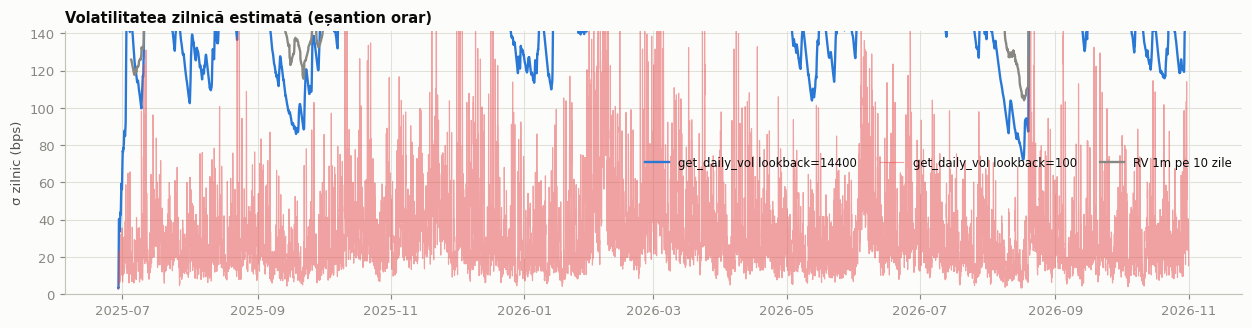

In [4]:
CLOSE1 = B1["close_ff"].astype(float)
VOL_LOOKBACK = 14_400
def daily_vols():
    v = ml.util.get_daily_vol(CLOSE1, lookback=VOL_LOOKBACK)
    v100 = ml.util.get_daily_vol(CLOSE1, lookback=100)
    r = np.log(CLOSE1).diff()
    rv10 = np.sqrt(1440 * (r ** 2).rolling(14_400, min_periods=10_000).mean())
    return v, v100, rv10
VOL, VOL100, RV10 = cached("daily_vol", daily_vols)
VOL = VOL.reindex(CLOSE1.index)
# Evaluare: cât de bine prezice fiecare estimare |randamentul următoarelor 24 h| (raport mediu, la ora 00:00 a fiecărei zile)
fwd = np.log(CLOSE1.shift(-1440) / CLOSE1).abs()
day_pts = CLOSE1.index[(CLOSE1.index.hour == 0) & (CLOSE1.index.minute == 0)]
ev = pd.DataFrame({"get_daily_vol lookback=14400": VOL.reindex(day_pts), "get_daily_vol lookback=100": VOL100.reindex(day_pts),
                   "RV 1m pe 10 zile": RV10.reindex(day_pts), "|r 24h următoare|": fwd.reindex(day_pts)}).dropna()
summ = pd.DataFrame({c: {"mediană (bps)": 1e4 * ev[c].median(), "E|r| / (σ·√(2/π))": ev["|r 24h următoare|"].mean() / (ev[c].mean() * np.sqrt(2 / np.pi)),
                         "corelație Spearman cu |r 24h|": ev[c].corr(ev["|r 24h următoare|"], method="spearman"),
                         "variația zilnică a estimării (mediana |Δlog σ|)": np.median(np.abs(np.diff(np.log(ev[c]))))} for c in ev.columns[:3]}).T
display(summ.round(3))
fig, ax = plt.subplots(figsize=(12, 3.2))
SER = {"get_daily_vol lookback=14400": VOL, "get_daily_vol lookback=100": VOL100, "RV 1m pe 10 zile": RV10}
for (c, s_), col in zip(SER.items(), [C["blue"], C["red"], C["gray"]]):
    ax.plot(1e4 * s_.iloc[::60], color=col, lw=0.8 if "100" in c else 1.6, alpha=0.5 if "100" in c else 1, label=c)
ax.set_ylabel("σ zilnic (bps)"); ax.set_title("Volatilitatea zilnică estimată (eșantion orar)"); ax.legend(ncol=3); ax.set_ylim(0, 1e4 * VOL100.quantile(0.995))
fig.tight_layout(); plt.show()

Cu `lookback = 100`, estimarea oscilează mult de la o zi la alta. Cu `lookback = 14 400`, nivelul este apropiat de volatilitatea realizată și se schimbă lent. Raportul E|r|/(σ√(2/π)) apropiat de 1 arată că σ are scara potrivită pentru randamentele de 24 h (pentru o distribuție normală raportul ar fi exact 1).

**Seria de prețuri pentru bariere.** Pentru **toate** rezoluțiile și ambele primare, atingerea barierelor se observă pe aceeași serie de 1 minut: **prima și ultima tranzacție din fiecare minut** (open-ul, indexat la momentul primei tranzacții `m_open_ms`, și close-ul, indexat la sfârșitul minutului). Intrarea simulată se face la **prima tranzacție de după decizie**, adică la open-ul minutului care urmează deciziei, punct care există deja în serie. Astfel:
* decizia folosește numai informația până la `decision_time` (închiderea barei de R minute);
* barierele și rezultatul pornesc de la prețul de intrare;
* seria de observație este aceeași pentru orice rezoluție și primară, deci schimbarea rezoluției semnalului nu schimbă modul în care sunt observate barierele.

**Limite ale rezoluției de 1 minut.** Nu vedem traseul din interiorul minutului: o atingere este înregistrată la primul open sau close de minut aflat dincolo de barieră, deci (a) momentul ieșirii are precizie de 1 minut, (b) prețul de ieșire depășește de obicei bariera (cu atât mai mult în mișcările bruște), (c) o atingere în interiorul minutului, urmată de revenire până la close, nu este înregistrată. Nu folosim cel mai nefavorabil preț al minutului (high/low) ca preț de execuție.

In [5]:
def entry_points(dec_ns):
    """Minutul următor deciziei: momentul primei tranzacții (open) și prețul ei. Pentru minutele fără tranzacții se caută primul minut cu tranzacții (maxim 10)."""
    k = np.searchsorted(B1["decision_time_ns"].to_numpy(), dec_ns) + 1                 # rândul minutului care începe la decizie
    op, mo, ts = B1["bar_open"].to_numpy(), B1["m_open_ms"].to_numpy(), B1["t_start_ns"].to_numpy()
    out_t, out_p, out_k = np.zeros(len(k), np.int64), np.full(len(k), np.nan), np.full(len(k), -1)
    for i, kk in enumerate(k):
        for j in range(kk, min(kk + 10, len(op))):
            if np.isfinite(op[j]):
                off = min(max(int(mo[j]) * 10**6 - ts[j], 10**6), 59 * 10**9)    # strict în interiorul minutului, diferit de close-uri
                out_t[i], out_p[i], out_k[i] = ts[j] + off, op[j], j
                break
    return out_t, out_p, out_k
_has = np.isfinite(B1["bar_open"].to_numpy())
_ts = B1["t_start_ns"].to_numpy(); _mo = B1["m_open_ms"].to_numpy()
_open_ns = _ts + np.minimum(np.maximum(_mo * 10**6 - _ts, 10**6), 59 * 10**9)
PATH = pd.concat([pd.Series(B1["bar_open"].to_numpy()[_has], index=pd.to_datetime(_open_ns[_has])), CLOSE1]).sort_index()
assert PATH.index.is_unique
PATH_NS, PATH_PX = PATH.index.asi8, PATH.to_numpy()
print(f"Seria de observație a barierelor: {len(PATH):,} puncte (open + close pentru fiecare minut cu tranzacții).")
_t, _p, _k = entry_points(B1["decision_time_ns"].to_numpy()[100_000:100_005])
print("Exemplu: decizie", list(B1.index[100_000:100_002]), "→ intrare", list(pd.to_datetime(_t[:2])), "la", _p[:2])

Seria de observație a barierelor: 1,413,557 puncte (open + close pentru fiecare minut cu tranzacții).
Exemplu: decizie [Timestamp('2025-09-05 10:41:00'), Timestamp('2025-09-05 10:42:00')] → intrare [Timestamp('2025-09-05 10:41:00.319000'), Timestamp('2025-09-05 10:42:00.344000')] la [112280.  112323.2]


## 3. Perioade, setul comun de features și primarele

**Granițe calendaristice comune** (aceleași pentru toate strategiile, rezoluțiile și modelele):

| Segment | Decizii între | Folosit pentru |
|---|---|---|
| warm-up | 28.06 – 06.07.2025 | doar istoric pentru indicatori (σ zilnic, OI 7 zile) |
| **train** | 07.07.2025 – 31.01.2026 | alegerea parametrilor primarelor, preprocesare, antrenarea modelelor |
| **validation** | 01.02 – 31.05.2026 | alegerea pragului de filtrare (singura alegere declarată pe validation) |
| **test** | 01.06 – 31.10.2026 | evaluare finală (deja văzut de notebookurile anterioare — vezi limitarea de la început) |

**Purjare.** Un eveniment aparține segmentului în care este luată decizia. Fiecare etichetă poate dura până la 24 h (bariera verticală), așa că eliminăm evenimentele cu decizia în ultimele 24 h + 10 min înaintea fiecărei granițe (și înaintea sfârșitului datelor). Purjarea folosește bariera verticală maximă, nu momentul real al ieșirii, pentru ca selecția evenimentelor să nu depindă de rezultat. Astfel nicio fereastră de etichetă nu traversează o graniță. Features folosesc doar trecutul (ferestre de până la 7 zile), deci nu e nevoie de embargo suplimentar pe partea de features.

In [6]:
START = pd.Timestamp("2025-07-07"); VAL_START = pd.Timestamp("2026-02-01"); TEST_START = pd.Timestamp("2026-06-01"); DATA_END = pd.Timestamp("2026-11-01")
HOLD = pd.Timedelta(hours=24)                    # bariera verticală (durata maximă a poziției)
PURGE = HOLD + pd.Timedelta(minutes=10)
SEGMENTS = ["train", "val", "test"]
SEG_RO = {"train": "train", "val": "validation", "test": "test"}
def segment_of(t):
    t = pd.DatetimeIndex(t)
    seg = np.full(len(t), "", dtype=object)
    for name, a, b in [("train", START, VAL_START), ("val", VAL_START, TEST_START), ("test", TEST_START, DATA_END)]:
        seg[(t >= a) & (t < b - PURGE)] = name
    return seg

**Setul comun de features (41, în 11 familii).** Criterii: (a) aceeași semnificație la orice rezoluție, (b) acoperire bună (excludem ferestrele stricte cu > 80% lipsă, ex. `rv_trade_24h_grid1m`), (c) câte un reprezentant pentru fiecare mecanism economic, nu zeci de variante corelate ale aceleiași mărimi.

* Majoritatea features sunt **instantanee pe ferestre fixe de ceas** (15 min – 7 zile), citite la decizie. Pentru același moment ele au exact aceeași valoare la 1m și la 30m; diferă doar momentele selectate de primare.
* Două familii sunt **native rezoluției**: bara curentă (randament, range, TFI, close location, ritm de volum pe bara de R minute) și indicatorii Bollinger pe 20 de bare. Ele își schimbă orizontul odată cu rezoluția și permit să vedem dacă importanța se mută de la informația pe ceas la cea pe bare.
* `sigma_d` (σ zilnic de la `get_daily_vol`) este lățimea barierelor; o includem explicit, fiindcă determină mecanic probabilitatea de atingere.

In [7]:
FAMILIES = {
    "randamente (ceas)": ["ret_trade_15m", "ret_trade_1h", "ret_trade_4h", "ret_trade_24h"],
    "volatilitate": ["log_vol_1h", "log_sigma_d", "rv_ratio_2m_1h_grid1s", "range_log_1h"],
    "flux tranzacții": ["tfi_ratio_15m", "tfi_ratio_1h", "large_trade_share_15m", "notional_15m_vs_slot_median_28d", "log_notional_1h"],
    "book (nivel)": ["qi_1", "qi_top10", "qi_25bps", "log_depth_25bps", "cost_buy_100000usdt_atmid_bps"],
    "OFI / imbalance 15m": ["ofi_norm_15m", "tw_qi_1_15m"],
    "derivate (funding, bază, OI)": ["funding_rate_asof", "basis_mark_index_bps", "oi_log_change_known_1h", "oi_log_change_known_24h", "oi_level_rz_7d"],
    "lichidări": ["log1p_liq_notional_1h", "liq_imbalance_1h", "liq_long_share_1h"],
    "calendar": ["hour_of_day_sin", "hour_of_day_cos", "is_weekend"],
    "poziție în range 1h": ["close_location_1h", "drawdown_from_high_1h", "vwap_distance_1h_bps"],
    "bară nativă (R)": ["bar_return_log", "bar_range_log", "bar_tfi_ratio", "bar_close_location", "log_volrate_bar"],
    "Bollinger nativ (R)": ["bb_z", "bb_width", "ret_20b"],
}
FEATS = [f for v in FAMILIES.values() for f in v]
FAM_OF = {f: k for k, v in FAMILIES.items() for f in v}
BB_N, BB_K = 20, 2.0

def build_features(R):
    A = BARS[R]
    F = pd.DataFrame(index=A.index)
    for c in EXEC_COLS + SNAP_COLS:
        if c in FEATS:
            F[c] = A[c].astype(float)
    F["log_vol_1h"] = 0.5 * np.log(A["rv_trade_1h_grid1s"].astype(float).where(lambda x: x > 0))
    F["log_sigma_d"] = np.log(VOL.reindex(A.index))
    F["log_notional_1h"] = np.log(A["notional_1h_usdt"].astype(float).where(lambda x: x > 0))
    F["log_depth_25bps"] = np.log((A["depth_bid_25bps_btc"] + A["depth_ask_25bps_btc"]).astype(float).where(lambda x: x > 0))
    F["liq_long_share_1h"] = (A["liq_notional_long_1h_usdt"] / A["notional_1h_usdt"]).astype(float)
    F["bar_return_log"] = A["bar_return_log"]
    F["bar_range_log"] = A["bar_range_log"]
    F["bar_tfi_ratio"] = A["bar_tfi_ratio"]
    F["bar_close_location"] = A["bar_close_location"]
    F["log_volrate_bar"] = np.log1p(A["bar_volume_btc"] / R)
    c = A["close_ff"]
    ma, sd = c.rolling(BB_N).mean(), c.rolling(BB_N).std(ddof=0)
    F["bb_z"] = (c - ma) / sd
    F["bb_width"] = sd / ma
    F["ret_20b"] = np.log(c / c.shift(BB_N))
    F = F.replace([np.inf, -np.inf], np.nan)
    return F[FEATS], ma - BB_K * sd
FEAT, LOWER = {}, {}
for R in RES:
    FEAT[R], LOWER[R] = build_features(R)
cov = pd.DataFrame({f"{R}m": FEAT[R].loc[START:].notna().mean() for R in RES})
cov["familie"] = cov.index.map(FAM_OF)
print("Acoperirea features (fracție nenulă, de la începutul train):")
display(cov.groupby("familie").agg(["min", "mean"]).round(3))

Acoperirea features (fracție nenulă, de la începutul train):


1m          5m         15m         30m      
                               min  mean   min  mean   min  mean   min  mean
familie                                                                     
Bollinger nativ (R)              1     1     1     1     1     1     1     1
OFI / imbalance 15m          0.863 0.863 0.863 0.863 0.864 0.864 0.887 0.887
bară nativă (R)                  1     1     1     1     1     1     1     1
book (nivel)                 0.938 0.959 0.939  0.96  0.94  0.96 0.942 0.961
calendar                         1     1     1     1     1     1     1     1
derivate (funding, bază, OI) 0.987 0.992 0.992 0.997 0.995 0.998 0.994 0.998
flux tranzacții              0.887 0.934 0.887 0.934 0.887 0.934 0.887 0.937
lichidări                    0.845 0.893 0.845 0.893 0.846 0.894 0.847 0.895
poziție în range 1h          0.887 0.887 0.887 0.887 0.887 0.887 0.887 0.887
randamente (ceas)            0.998 0.998 0.998 0.998 0.999 0.999 0.999 0.999
volatilitate                 0.887 0.915 0.887 0.915 0.887 0.915 0.887 0.915

### 3.1 Bollinger Bands mean reversion

**Regula.** Pe barele de rezoluție R: media mobilă simplă și deviația standard (populație) a close-ului pe **20 de bare**, banda inferioară = MA − 2·SD. Semnal long la bara t dacă close-ul **traversează în jos** banda: `close_t < lower_t` și `close_{t−1} ≥ lower_{t−1}`.

* Parametrii (20, 2) sunt cei canonici. **Nu i-am optimizat**, nici pe train: orice căutare ar adăuga un grad de libertate care nu ține de întrebarea despre rezoluție și meta-labeling.
* Condiția de traversare (nu simpla poziție sub bandă) dă un singur semnal pe excursie, nu câte unul la fiecare bară sub bandă.
* **Ferestrele sunt exprimate în număr de bare.** Regula „BB(20, 2) pe graficul de R minute” acoperă 20 min la 1m, 100 min la 5m, 5 h la 15m și 10 h la 30m. Diferențele dintre rezoluții includ deci și orizontul indicatorului, nu doar granularitatea datelor. Ieșirile, în schimb, sunt fixe în timp (24 h, σ zilnic).

### 3.2 CUSUM + o condiție long

**Evenimente.** `ml.filters.cusum_filter(close_R, threshold)` primește **prețurile** de close ale barelor de rezoluție R și calculează intern randamentele logaritmice semnate (`log(p).diff()`), cu două sume S⁺ și S⁻ resetate la depășirea pragului. Am verificat în cod că inputul este prețul, nu randamentul, și că funcția nu folosește randamente absolute. Pragul este o serie: `threshold = h × σ_zilnic` (aceeași σ ca la bariere), deci exprimat în unități de randament și independent de rezoluție. Pentru o mișcare browniană, numărul de evenimente pe zi este ≈ (σ_zilnic / h)², adică ~16/zi pentru h = 0,25.

**Condiția long (două features).** `ret_trade_1h < 0` **și** `liq_long_share_1h ≥ q`, unde `liq_long_share_1h` = notionalul lichidărilor de poziții long din ultima oră / notionalul tranzacționat în ultima oră, iar q este mediana acestui raport pe evenimentele CUSUM descendente din **train**.

**Raționament economic.** CUSUM marchează o mișcare de preț neobișnuit de mare. Dacă mișcarea a fost în jos și o parte importantă din volum a fost **vânzare forțată** (lichidări de long), presiunea de preț este, cel puțin parțial, neinformațională: vânzătorii nu au o informație nouă, sunt obligați să iasă. Furnizorii de lichiditate care cumpără în aceste momente cer o primă care ar trebui să se vadă ca revenire a prețului. Fără lichidări, aceeași scădere poate reflecta informație și nu oferă motiv de revenire.

Ferestrele condiției sunt de **1 oră de ceas** la toate rezoluțiile, iar pragul CUSUM este fix în unități de σ. Prin construcție, primara CUSUM este aproape invariantă la rezoluție; se schimbă doar granularitatea cu care sunt observate prețurile pentru filtru. Contrastul cu Bollinger (ferestre în bare) este intenționat.

In [8]:
CUSUM_H = 0.25
def eligible_mask(R, idx):
    A = BARS[R].loc[idx]
    inc = incident_rows(A["t_start_ns"].to_numpy(), A["decision_time_ns"].to_numpy() + int(HOLD.value), MAN["quality_incidents"])
    return (A["ok"].to_numpy() & np.isfinite(VOL.reindex(idx).to_numpy()) & (segment_of(idx) != "") & ~inc)

def bb_events(R):
    c, lo = BARS[R]["close_ff"], LOWER[R]
    sig = (c < lo) & (c.shift(1) >= lo.shift(1))
    idx = sig.index[sig.to_numpy()]
    return idx[eligible_mask(R, idx)]

def cusum_raw(R):
    close = BARS[R]["close_ff"]
    thr = (CUSUM_H * VOL.reindex(close.index)).astype(float)
    ev = ml.filters.cusum_filter(close, threshold=thr)
    return ev[eligible_mask(R, ev)]
CUSUM_RAW = cached(f"cusum_raw_h{CUSUM_H}", lambda: {R: cusum_raw(R) for R in RES})
# Pragul condiției: ales numai pe train, la 1m (aceeași valoare apoi la toate rezoluțiile)
_e = CUSUM_RAW[1][segment_of(CUSUM_RAW[1]) == "train"]
_f = FEAT[1].loc[_e]
LIQ_Q = float(_f.loc[_f["ret_trade_1h"] < 0, "liq_long_share_1h"].median())
def cusum_events(R):
    e = CUSUM_RAW[R]; f = FEAT[R].loc[e]
    keep = (f["ret_trade_1h"] < 0) & (f["liq_long_share_1h"] >= LIQ_Q)
    return e[keep.to_numpy()]
EVENTS = {("BB", R): bb_events(R) for R in RES}
EVENTS.update({("CUSUM", R): cusum_events(R) for R in RES})
PRIMS = ["BB", "CUSUM"]
print(f"Prag condiție CUSUM (mediana pe train a liq_long_share_1h la evenimente descendente): {LIQ_Q:.5f} ({1e4 * LIQ_Q:.2f} bps din notional).")
days = {s: max(1, ((segment_of(BARS[1].index) == s).sum()) / 1440) for s in SEGMENTS}
rows = []
for R in RES:
    raw = CUSUM_RAW[R]
    rows.append({"rezoluție": f"{R}m", "CUSUM brut / zi (train)": (segment_of(raw) == "train").sum() / days["train"],
                 **{f"{p} / zi ({SEG_RO[s]})": (segment_of(EVENTS[(p, R)]) == s).sum() / days[s] for p in PRIMS for s in SEGMENTS},
                 **{f"{p} total": len(EVENTS[(p, R)]) for p in PRIMS}})
display(pd.DataFrame(rows).set_index("rezoluție").round(2))

Prag condiție CUSUM (mediana pe train a liq_long_share_1h la evenimente descendente): 0.00051 (5.06 bps din notional).


,CUSUM brut / zi (train),BB / zi (train),BB / zi (validation),BB / zi (test),CUSUM / zi (train),CUSUM / zi (validation),CUSUM / zi (test),BB total,CUSUM total
rezoluție,,,,,,,,,
1m,27.67,42.92,43.36,42.45,5.9,5.56,8.88,20539,3239
5m,19.14,8.7,8.62,8.76,4.22,4,6.22,4167,2299
15m,13.07,2.99,2.61,2.63,3.09,2.97,4.36,1332,1657
30m,9.35,1.41,1.11,1.3,2.38,2.19,3.38,624,1268


## 4. Triple barrier cu `mlfinpy`: alegeri, verificare pe exemple controlate, etichetare

**Bariere.** TP = 1 × σ_zilnic, SL = 2 × σ_zilnic (`pt_sl = [1, 2]`), `target` = σ_zilnic de la `get_daily_vol` citit **la decizie**, side = +1 transmis explicit prin `side_prediction`.

**Bariera verticală: 24 h, identică la toate rezoluțiile.** Barierele sunt scalate cu volatilitatea *zilnică*, deci scara naturală de timp a tranzacției este o zi. Cu o expirare mult mai scurtă (de exemplu 1–4 h), TP-ul de 1σ_zilnic ar fi atins rar, iar eticheta ar deveni practic un randament pe orizont fix. Cu o expirare mult mai lungă, am avea foarte puține evenimente independente. Valoarea de 24 h a fost fixată înainte de orice rezultat. Mai jos arătăm, doar pe train și fără profit, cum s-ar schimba proporțiile TP/SL/timeout pentru alte valori.

**Ce face efectiv implementarea instalată (citită în cod, `mlfinpy/labeling/labeling.py`):**
* `get_events`: dacă `side_prediction is None`, folosește `pt_sl_ = [pt_sl[0], pt_sl[0]]`, adică bariere **simetrice**, iar al doilea element este ignorat. Doar cu side transmis se folosește `pt_sl[:2] = [1, 2]`. Transmiterea explicită a side-ului este deci obligatorie pentru asimetrie.
* `triple_barriers`: randamentul simplu pe traseu, `close[t]/close[t0] − 1`, înmulțit cu side; TP la prima observație cu randament > 1·trgt, SL la prima cu randament < −2·trgt; `t1` = cea mai timpurie dintre TP, SL și bariera verticală.
* `get_bins` (cu side): `ret` = randamentul la `t1`; `barrier_touched` dă 1 / −1 / 0 pentru TP / SL / verticală, apoi pune `bin = 0` pentru orice `ret ≤ 0`. **Rezultatul în această versiune: `bin = 1` dacă și numai dacă TP a fost atins primul; `bin = 0` pentru SL și pentru orice timeout, inclusiv un timeout cu randament pozitiv.** Aceasta este exact ținta cerută („TP înaintea SL și a expirării”). Atenție: în meta-labeling-ul clasic din AFML (fără `barrier_touched`), un timeout pozitiv ar primi `bin = 1`. Verificăm comportamentul pe exemple controlate.

In [9]:
def mlf_label(close, t_events, trgt, vb, side=True):
    ev = ml.labeling.get_events(close=close, t_events=t_events, pt_sl=[1, 2], target=trgt, min_ret=0.0, num_threads=1,
                                vertical_barrier_times=vb, side_prediction=pd.Series(1.0, index=t_events) if side else None, verbose=False)
    return ev, ml.labeling.get_bins(ev, close)

# Exemple controlate: preț pornind de la 100, σ = 1% (TP la +1%, SL la −2%), barieră verticală după 10 minute
t = pd.date_range("2030-01-01", periods=60, freq="1min")
paths = {
    "TP atins (urcă +1,2% la min. 3)":           [100, 100.4, 100.8, 101.2, 101.5] + [101.0] * 55,
    "SL atins (scade −2,3% la min. 4)":          [100, 99.5, 99.0, 98.5, 97.7] + [97.0] * 55,
    "timeout pozitiv (+0,6% la expirare)":       [100] + list(np.linspace(100, 100.6, 10)) + [100.6] * 49,
    "timeout negativ (−1,5% la expirare)":       [100] + list(np.linspace(100, 98.5, 10)) + [98.5] * 49,
    "−1,5% apoi TP (SL de 2σ NU e atins)":       [100, 99.0, 98.5, 99.5, 100.5, 101.1] + [101.1] * 54,
}
rows = []
for name, p in paths.items():
    close = pd.Series(np.array(p, float), index=t)
    te = pd.DatetimeIndex([t[0]]); trgt = pd.Series([0.01], index=te)
    vb = ml.labeling.add_vertical_barrier(te, close, num_minutes=10)
    for side in (True, False):
        ev, bn = mlf_label(close, te, trgt, vb, side=side)
        rows.append({"traseu": name, "side transmis": "da (+1)" if side else "nu", "pt_sl efectiv": "[1, 2]" if side else "[1, 1]",
                     "t1 (minut)": int((ev["t1"].iloc[0] - t[0]) / pd.Timedelta("1min")), "ret la t1": f"{bn['ret'].iloc[0]:+.4f}", "bin": int(bn["bin"].iloc[0])})
CTRL = pd.DataFrame(rows)
display(CTRL.set_index(["traseu", "side transmis"]))
exp_side = {"TP atins (urcă +1,2% la min. 3)": (3, 1), "SL atins (scade −2,3% la min. 4)": (4, 0), "timeout pozitiv (+0,6% la expirare)": (10, 0),
            "timeout negativ (−1,5% la expirare)": (10, 0), "−1,5% apoi TP (SL de 2σ NU e atins)": (5, 1)}
for name, (tm, b) in exp_side.items():
    r = CTRL[(CTRL["traseu"] == name) & (CTRL["side transmis"] == "da (+1)")].iloc[0]
    assert (r["t1 (minut)"], r["bin"]) == (tm, b), (name, r.to_dict())
r = CTRL[(CTRL["traseu"] == "−1,5% apoi TP (SL de 2σ NU e atins)") & (CTRL["side transmis"] == "nu")].iloc[0]
assert r["t1 (minut)"] == 1, "fără side, SL-ul ar trebui să fie la 1σ (simetric)"
print("Toate cele 5 cazuri controlate dau rezultatul așteptat cu side = +1. Fără side, ultimul caz se oprește la −1σ (minutul 1):"
      " implementarea ignoră al doilea element din pt_sl, deci asimetria [1, 2] există doar cu side transmis.")

pt_sl efectiv  t1 (minut) ret la t1  bin
traseu                              side transmis                                         
TP atins (urcă +1,2% la min. 3)     da (+1)              [1, 2]           3   +0.0120    1
                                    nu                   [1, 1]           3   +0.0120    1
SL atins (scade −2,3% la min. 4)    da (+1)              [1, 2]           4   -0.0230    0
                                    nu                   [1, 1]           2   -0.0100    0
timeout pozitiv (+0,6% la expirare) da (+1)              [1, 2]          10   +0.0060    0
                                    nu                   [1, 1]          10   +0.0060    0
timeout negativ (−1,5% la expirare) da (+1)              [1, 2]          10   -0.0150    0
                                    nu                   [1, 1]           7   -0.0100    0
−1,5% apoi TP (SL de 2σ NU e atins) da (+1)              [1, 2]           5   +0.0110    1
                                    nu                   [1, 1]           1   -0.0100    0

Toate cele 5 cazuri controlate dau rezultatul așteptat cu side = +1. Fără side, ultimul caz se oprește la −1σ (minutul 1): implementarea ignoră al doilea element din pt_sl, deci asimetria [1, 2] există doar cu side transmis.


Ultimul exemplu este cel mai util: cu side transmis, scăderea de −1,5% nu atinge SL-ul de 2σ și tranzacția ajunge la TP. Fără side, aceeași scădere atinge un SL simetric de 1σ. Timeout-ul pozitiv primește `bin = 0`.

**Etichetarea evenimentelor reale.** Pentru fiecare eveniment: decizia = închiderea barei de R minute; intrarea = prima tranzacție din minutul următor (punct al seriei de observație open/close de 1 minut); `target` = σ_zilnic la decizie; bariera verticală = `add_vertical_barrier(intrări, serie, num_days=1)`. Pentru primarele aleatoare (secțiunea 12, mii de etichetări repetate) folosim o reimplementare numba a acelorași reguli. O verificăm aici: trebuie să dea exact aceleași `t1` și `ret` ca `mlfinpy` pe toate evenimentele reale.

**Costuri (raportate separat):**
* **Comision**: 5 bps pe parte (taker Binance USDⓈ-M, nivel de bază), 10 bps pe tranzacție completă. Considerăm taker și la TP, ceea ce este ușor conservator: un TP plasat ca ordin limită ar plăti comision de maker.
* **Slippage**: costul de execuție al unui ordin de 10.000 USDT față de mid, citit din book (`cost_buy_10000usdt_atmid_bps` la decizie pentru intrare și `cost_sell_…` în minutul ieșirii). Include jumătatea de spread și impactul pe adâncime. Valorile lipsă sunt înlocuite cu mediana din train.
* **Latență**: diferența dintre close-ul de la decizie și prețul de intrare (prima tranzacție de după decizie). Este inclusă în randamentul brut și raportată separat.
* **Funding**: suma ratelor de funding la decontările (00/08/16 UTC) dintre intrare și ieșire. O poziție long plătește rata când aceasta este pozitivă. Rata este cea cunoscută imediat înaintea decontării.

Prețul de ieșire este close-ul minutului în care atingerea este observată, nu cel mai nefavorabil preț al minutului. Pentru TP, un ordin limită ar ieși exact la barieră; close-ul este de obicei puțin peste barieră, deci ușor optimist. Pentru SL, un stop-market ar ieși la primul preț de după traversare, care poate fi mai bun sau mai rău decât close-ul. Prezentăm această convenție ca **estimare centrală**, nu ca execuție garantată.

In [10]:
FEE_BPS_SIDE = 5.0
CL1 = CLOSE1.to_numpy(); DEC1 = B1["decision_time_ns"].to_numpy()
COST_BUY1 = B1["cost_buy_10000usdt_atmid_bps"].astype(float).to_numpy(); COST_SELL1 = B1["cost_sell_10000usdt_atmid_bps"].astype(float).to_numpy()
_trn = (B1.index >= START) & (B1.index < VAL_START)
COST_BUY_MED, COST_SELL_MED = float(np.nanmedian(COST_BUY1[_trn])), float(np.nanmedian(COST_SELL1[_trn]))
# Decontările de funding: momentul = decizie + time_to_funding_s; rata = ultima rată cunoscută înaintea decontării
_ft = (B1["decision_time_ns"] + (B1["time_to_funding_s"].astype(float) * 1e9).round(-9).fillna(-1).astype(np.int64))
FUND_NS = np.unique(_ft[_ft > 0].to_numpy())
FUND_NS = FUND_NS[(FUND_NS % (3600 * 10**9) == 0)]
_fr = B1["funding_rate_asof"].astype(float).ffill().to_numpy()
FUND_RATE = _fr[np.clip(np.searchsorted(DEC1, FUND_NS, side="left") - 1, 0, len(DEC1) - 1)]
print(f"Decontări de funding identificate: {len(FUND_NS)} (ore UTC: {sorted(set(pd.to_datetime(FUND_NS).hour))}); rata medie {1e4 * FUND_RATE.mean():.2f} bps / decontare, "
      f"pozitivă în {np.mean(FUND_RATE > 0):.0%} din cazuri. Slippage median train (10k USDT): cumpărare {COST_BUY_MED:.4f} bps, vânzare {COST_SELL_MED:.4f} bps.")

def label_events(dec_idx):
    """Etichetare mlfinpy pentru deciziile dec_idx (DatetimeIndex al barelor de rezoluție R)."""
    dec_ns = dec_idx.asi8
    e_ns, e_px, e_k = entry_points(dec_ns)
    ok = e_k >= 0
    dec_ns, e_ns, e_px, e_k = dec_ns[ok], e_ns[ok], e_px[ok], e_k[ok]
    t_entry = pd.DatetimeIndex(pd.to_datetime(e_ns))
    path = PATH
    assert t_entry.isin(path.index).all() and np.allclose(path.reindex(t_entry).to_numpy(), e_px)
    trgt = pd.Series(VOL.reindex(pd.to_datetime(dec_ns)).to_numpy(), index=t_entry)
    vb = ml.labeling.add_vertical_barrier(t_entry, path, num_days=1)
    keep = t_entry.isin(vb.index) & np.isfinite(trgt.to_numpy())
    te = t_entry[keep]
    ev, bn = mlf_label(path, te, trgt[keep], vb[keep])
    out = pd.DataFrame({"dec": pd.to_datetime(dec_ns[keep]), "entry_t": te, "entry_px": e_px[keep], "entry_k": e_k[keep], "trgt": trgt[keep].to_numpy(),
                        "vb": vb[keep].to_numpy(), "t1": ev["t1"].reindex(te).to_numpy(), "ret": bn["ret"].reindex(te).to_numpy(), "bin": bn["bin"].reindex(te).to_numpy()})
    # uniqueness medie (AFML cap. 4) din mlfinpy, pe aceeași serie
    u = ml.sampling.get_av_uniqueness_from_triple_barrier(ev, path, num_threads=1, verbose=False)
    out["w"] = u["tW"].reindex(te).to_numpy()
    return out.reset_index(drop=True)

@njit(cache=True)
def tb_numba(entry_ns, trgt, path_ns, path_px, hold_ns, pt, sl):
    """Reimplementare a regulilor mlfinpy pe aceeași serie de observație (open + close de 1 minut)."""
    n = entry_ns.size
    t1 = np.zeros(n, np.int64); ret = np.full(n, np.nan); code = np.zeros(n, np.int8)
    for i in range(n):
        k = np.searchsorted(path_ns, entry_ns[i]); p0 = path_px[k]
        kv = np.searchsorted(path_ns, entry_ns[i] + hold_ns)            # primul punct ≥ intrare + 24 h (add_vertical_barrier)
        if kv >= path_ns.size:
            code[i] = -9; continue
        done = False
        for j in range(k, kv + 1):
            r = path_px[j] / p0 - 1.0
            if r > pt * trgt[i]:
                t1[i] = path_ns[j]; ret[i] = r; code[i] = 1; done = True; break
            if r < -sl * trgt[i]:
                t1[i] = path_ns[j]; ret[i] = r; code[i] = -1; done = True; break
        if not done:
            t1[i] = path_ns[kv]; ret[i] = path_px[kv] / p0 - 1.0; code[i] = 0
    return t1, ret, code

@njit(cache=True)
def uniqueness_numba(s_ns, e_ns, grid):
    """Uniqueness medie AFML pe grila de timp dată (numărul de etichete concurente pe fiecare punct)."""
    n = s_ns.size; m = grid.size
    cnt = np.zeros(m + 1, np.int64)
    a = np.searchsorted(grid, s_ns); b = np.searchsorted(grid, e_ns, side="right")
    for i in range(n):
        cnt[a[i]] += 1; cnt[b[i]] -= 1
    c = np.cumsum(cnt)[:m]
    w = np.zeros(n)
    for i in range(n):
        s = 0.0
        for j in range(a[i], b[i]):
            s += 1.0 / c[j]
        w[i] = s / max(1, b[i] - a[i])
    return w

def enrich(L, R):
    """Rezultat, costuri, durată, segment și features pentru un tabel de etichete."""
    L = L.copy()
    L["seg"] = segment_of(L["dec"])
    L["R"] = R
    L["gross_bps"] = 1e4 * L["ret"]
    L["outcome"] = np.where(L["bin"] == 1, "TP", np.where(L["ret"] < -2 * L["trgt"], "SL", np.where(L["ret"] > 0, "timeout+", "timeout−")))
    L["touch"] = L["outcome"].isin(["TP", "SL"]).astype(int)
    L["hold_min"] = (pd.to_datetime(L["t1"]) - pd.to_datetime(L["entry_t"])) / pd.Timedelta("1min")
    kd = np.searchsorted(DEC1, L["dec"].to_numpy().astype("datetime64[ns]").astype(np.int64))
    kx = np.searchsorted(DEC1, pd.to_datetime(L["t1"]).to_numpy().astype("datetime64[ns]").astype(np.int64), side="right") - 1   # starea book-ului cunoscută la ieșire
    L["lat_bps"] = 1e4 * np.log(L["entry_px"].to_numpy() / CL1[kd])
    L["slip_in_bps"] = np.where(np.isfinite(COST_BUY1[kd]), COST_BUY1[kd], COST_BUY_MED)
    L["slip_out_bps"] = np.where(np.isfinite(COST_SELL1[kx]), COST_SELL1[kx], COST_SELL_MED)
    e_ns = pd.to_datetime(L["entry_t"]).to_numpy().astype("datetime64[ns]").astype(np.int64); x_ns = pd.to_datetime(L["t1"]).to_numpy().astype("datetime64[ns]").astype(np.int64)
    cf = np.r_[0, np.cumsum(FUND_RATE)]
    L["fund_bps"] = 1e4 * (cf[np.searchsorted(FUND_NS, x_ns, side="right")] - cf[np.searchsorted(FUND_NS, e_ns, side="right")])
    L["fee_bps"] = 2 * FEE_BPS_SIDE
    L["net_bps"] = L["gross_bps"] - L["fee_bps"] - L["slip_in_bps"] - L["slip_out_bps"] - L["fund_bps"]
    L["tp_bps"] = 1e4 * L["trgt"]; L["sl_bps"] = 2e4 * L["trgt"]
    L["y_tp"] = L["bin"].astype(int)
    X = FEAT[R].reindex(pd.DatetimeIndex(L["dec"]))
    for c in FEATS:
        L[c] = X[c].to_numpy()
    return L[L["seg"] != ""].reset_index(drop=True)

def label_all():
    out = {}
    for key, idx in EVENTS.items():
        t0 = time.time()
        out[key] = label_events(idx)
        print(f"  {key[0]:5s} {key[1]:>2d}m: {len(out[key]):6,d} evenimente etichetate în {time.time() - t0:5.1f} s")
    return out
print("Etichetare mlfinpy (get_events + get_bins + uniqueness) pentru 2 primare × 4 rezoluții:")
LAB_RAW = cached("labels_mlfinpy", label_all)
EV = {key: enrich(L, key[1]) for key, L in LAB_RAW.items()}

# Verificarea reimplementării numba față de mlfinpy pe toate evenimentele reale
mism, tot = 0, 0
for key, L in LAB_RAW.items():
    e_ns = pd.to_datetime(L["entry_t"]).to_numpy().astype("datetime64[ns]").astype(np.int64)
    t1n, retn, coden = tb_numba(e_ns, L["trgt"].to_numpy(), PATH_NS, PATH_PX, int(HOLD.value), 1.0, 2.0)
    same = (t1n == pd.to_datetime(L["t1"]).to_numpy().astype("datetime64[ns]").astype(np.int64)) & np.isclose(retn, L["ret"].to_numpy(), rtol=0, atol=1e-12) \
           & ((coden == 1) == (L["bin"].to_numpy() == 1))
    mism += int((~same).sum()); tot += len(L)
    wn = uniqueness_numba(e_ns, pd.to_datetime(L["t1"]).to_numpy().astype("datetime64[ns]").astype(np.int64), PATH_NS)
    assert np.allclose(wn, L["w"].to_numpy(), atol=1e-9), key
print(f"Reimplementarea numba reproduce mlfinpy: t1, ret și bin identice pe {tot - mism:,} din {tot:,} evenimente; uniqueness identică pe toate.")
assert mism == 0

# Proporțiile pentru alte bariere verticale — DOAR train, fără randamente (justificarea celor 24 h)
rows = []
for key in [("BB", 15), ("CUSUM", 15)]:
    L = EV[key][EV[key]["seg"] == "train"]
    e_ns = pd.to_datetime(L["entry_t"]).to_numpy().astype("datetime64[ns]").astype(np.int64)
    for hh in [4, 12, 24, 48]:
        _, _, code = tb_numba(e_ns, L["trgt"].to_numpy(), PATH_NS, PATH_PX, hh * 3600 * 10**9, 1.0, 2.0)
        rows.append({"primară (15m, train)": key[0], "barieră verticală": f"{hh} h", "TP %": 100 * np.mean(code == 1), "SL %": 100 * np.mean(code == -1), "timeout %": 100 * np.mean(code == 0)})
display(pd.DataFrame(rows).set_index(["primară (15m, train)", "barieră verticală"]).round(1))

Decontări de funding identificate: 1471 (ore UTC: [0, 8, 16]); rata medie 0.38 bps / decontare, pozitivă în 81% din cazuri. Slippage median train (10k USDT): cumpărare 0.0046 bps, vânzare 0.0046 bps.
Etichetare mlfinpy (get_events + get_bins + uniqueness) pentru 2 primare × 4 rezoluții:


  BB     1m: 20,539 evenimente etichetate în  32.3 s


  BB     5m:  4,167 evenimente etichetate în   7.7 s


  BB    15m:  1,332 evenimente etichetate în   2.4 s


  BB    30m:    624 evenimente etichetate în   1.2 s


  CUSUM  1m:  3,239 evenimente etichetate în   6.0 s


  CUSUM  5m:  2,299 evenimente etichetate în   4.4 s


  CUSUM 15m:  1,657 evenimente etichetate în   3.3 s


  CUSUM 30m:  1,268 evenimente etichetate în   2.2 s


Reimplementarea numba reproduce mlfinpy: t1, ret și bin identice pe 35,125 din 35,125 evenimente; uniqueness identică pe toate.


TP %  SL %  timeout %
primară (15m, train) barieră verticală                       
BB                   4 h                 4.7   1.3       94.1
                     12 h               19.9   5.1       74.9
                     24 h               33.4  11.9       54.7
                     48 h               47.1  22.2       30.7
CUSUM                4 h                 6.4   1.2       92.4
                     12 h               20.2   6.2       73.5
                     24 h               34.9  13.6       51.6
                     48 h               49.8  22.3       27.9

## 5. Convenții de portofoliu și rezultatele primarelor nefiltrate

**Ipoteze, identice în toate comparațiile din notebook:**
* **Capital** 50.000 USDT, împărțit în **K = 5 sloturi** de 10.000 USDT; fără levier, expunere maximă 100%. Mărimea poziției este fixă (fără compunere), deci randamentele lunare se adună, iar curbele sunt în % din capitalul inițial.
* **Suprapunere.** Un semnal acceptat deschide o poziție dacă există un slot liber la momentul intrării; altfel este ignorat (nu se pune în coadă). O poziție ocupă slotul până la atingerea unei bariere sau la expirare. Toate pozițiile din curbe pot fi deci deținute simultan cu capitalul dat.
* **Execuție.** Intrare cu ordin market la prima tranzacție de după decizie; ieșire market la observarea atingerii (open/close de minut). Costurile sunt cele din secțiunea 4.
* **Evaluare zilnică (mark-to-market)** la 00:00 UTC; Sharpe anualizat cu √365 din PnL-ul zilnic; drawdown maxim pe curba zilnică.

Raportăm separat **nivelul de eveniment** (toate semnalele, fără constrângerea de capital: estimarea avantajului per tranzacție) și **nivelul de portofoliu** (tranzacțiile executate efectiv cu 5 sloturi). Ambele folosesc aceleași evenimente și aceleași ieșiri.

In [11]:
K_SLOTS = 5
DAY_NS = pd.date_range(START.normalize(), DATA_END, freq="1D").asi8
DAY_PX = CLOSE1.reindex(pd.to_datetime(DAY_NS)).ffill().to_numpy()

@njit(cache=True)
def take_slots(entry_ns, exit_ns, accept, K):
    """Politica de sloturi: evenimentele sunt sortate după intrare; un semnal acceptat intră dacă un slot este liber."""
    n = entry_ns.size
    busy = np.zeros(K, np.int64)
    taken = np.zeros(n, np.bool_)
    for i in range(n):
        if not accept[i]:
            continue
        for s in range(K):
            if busy[s] <= entry_ns[i]:
                busy[s] = exit_ns[i]; taken[i] = True; break
    return taken

@njit(cache=True)
def daily_pnl(entry_ns, exit_ns, entry_px, ret, c_in, c_out, taken, day_ns, day_px, K):
    """PnL zilnic (fracție din capital), brut și net, cu mark-to-market la granițele zilelor."""
    m = day_ns.size
    g = np.zeros(m); nt = np.zeros(m)
    w = 1.0 / K
    for i in range(entry_ns.size):
        if not taken[i]:
            continue
        de = np.searchsorted(day_ns, entry_ns[i]); dx = np.searchsorted(day_ns, exit_ns[i])
        if dx >= m:
            dx = m - 1
        prev = 0.0
        for d in range(de, dx):
            v = day_px[d] / entry_px[i] - 1.0
            g[d] += w * (v - prev); prev = v
        g[dx] += w * (ret[i] - prev)
        nt[de] -= w * c_in[i]; nt[dx] -= w * c_out[i]
    return g, g + nt

def arrays(L):
    o = np.argsort(pd.to_datetime(L["entry_t"]).to_numpy())
    L = L.iloc[o].reset_index(drop=True)
    e = pd.to_datetime(L["entry_t"]).to_numpy().astype("datetime64[ns]").astype(np.int64)
    x = pd.to_datetime(L["t1"]).to_numpy().astype("datetime64[ns]").astype(np.int64)
    c_in = (L["fee_bps"] / 2 + L["slip_in_bps"]).to_numpy() / 1e4
    c_out = (L["fee_bps"] / 2 + L["slip_out_bps"] + L["fund_bps"]).to_numpy() / 1e4
    return L, e, x, L["entry_px"].to_numpy(), L["ret"].to_numpy(), c_in, c_out

def seg_days(seg):
    a, b = {"train": (START, VAL_START), "val": (VAL_START, TEST_START), "test": (TEST_START, DATA_END), "all": (START, DATA_END)}[seg]
    d = pd.to_datetime(DAY_NS)
    return (d > a) & (d <= b)

def simulate(L, accept=None, seg="all"):
    """Rulează politica de sloturi pentru evenimentele L (deja restrânse la segment). Întoarce tranzacțiile executate și PnL-ul zilnic."""
    L = L.assign(_acc=True if accept is None else np.asarray(accept, bool))      # aliniat cu ordinea lui L, înainte de sortare
    L, e, x, p0, r, ci, co = arrays(L)
    acc = L["_acc"].to_numpy(bool)
    taken = take_slots(e, x, acc, K_SLOTS)
    g, n = daily_pnl(e, x, p0, r, ci, co, taken, DAY_NS, DAY_PX, K_SLOTS)
    m = seg_days(seg)
    expo = ((x - e)[taken].sum() / K_SLOTS) / max(1, m.sum() * 86400e9)
    di = pd.to_datetime(DAY_NS[m]) - pd.Timedelta(days=1)          # eticheta = ziua (00:00) pentru care s-a calculat PnL-ul
    return L[taken], pd.Series(g[m], index=di), pd.Series(n[m], index=di), expo

def block_boot_mean(day_codes, x, n_boot=2000, block=5, seed=0):
    """IC 95% pentru media pe eveniment: bootstrap circular pe blocuri de zile (evenimentele din aceeași zi și din zile vecine se suprapun)."""
    if len(x) < 5:
        return np.nan, np.nan
    s = pd.DataFrame({"d": day_codes, "x": x}).groupby("d")["x"].agg(["sum", "count"])
    S, N = s["sum"].to_numpy(), s["count"].to_numpy(); nd = len(S)
    rng = np.random.default_rng(seed)
    nb = int(np.ceil(nd / block))
    st = rng.integers(0, nd, size=(n_boot, nb))
    idx = (st[:, :, None] + np.arange(block)[None, None, :]).reshape(n_boot, -1)[:, :nd] % nd
    mb = S[idx].sum(1) / N[idx].sum(1)
    return np.percentile(mb, 2.5), np.percentile(mb, 97.5)

def max_dd(pnl):
    eq = np.r_[0, np.cumsum(pnl)]
    return float(np.max(np.maximum.accumulate(eq) - eq))

def trade_stats(T, g, n, expo, n_signals):
    net, gr = T["net_bps"].to_numpy(), T["gross_bps"].to_numpy()
    wins, losses = net[net > 0], net[net <= 0]
    sh = lambda p: p.mean() / p.std() * np.sqrt(365) if p.std() > 0 else np.nan
    return {"semnale": n_signals, "tranzacții": len(T), "expunere %": 100 * expo,
            "win rate net %": 100 * np.mean(net > 0) if len(T) else np.nan, "câștig mediu net (bps)": wins.mean() if len(wins) else np.nan,
            "pierdere medie net (bps)": losses.mean() if len(losses) else np.nan,
            "brut mediu (bps)": gr.mean() if len(T) else np.nan, "brut median (bps)": np.median(gr) if len(T) else np.nan,
            "net mediu (bps)": net.mean() if len(T) else np.nan, "net median (bps)": np.median(net) if len(T) else np.nan,
            "profit factor net": wins.sum() / -losses.sum() if losses.sum() < 0 else np.nan,
            "randament total brut %": 100 * g.sum(), "randament total net %": 100 * n.sum(),
            "Sharpe brut": sh(g), "Sharpe net": sh(n), "max DD net %": 100 * max_dd(n.to_numpy())}

def primary_summary(L_all, seg):
    L = L_all[L_all["seg"] == seg] if seg != "all" else L_all
    T, g, n, expo = simulate(L, seg=seg)
    st = trade_stats(T, g, n, expo, len(L))
    day = pd.to_datetime(L["dec"]).dt.floor("D").to_numpy()
    lo, hi = block_boot_mean(day, L["gross_bps"].to_numpy(), seed=1)
    st.update({"brut mediu / eveniment (bps)": L["gross_bps"].mean(), "IC95 jos": lo, "IC95 sus": hi,
               "net mediu / eveniment (bps)": L["net_bps"].mean()})
    return st, T, g, n

PRIM_RES, PRIM_CURVES = {}, {}
for (p, R), L in EV.items():
    for seg in SEGMENTS:
        st, T, g, n = primary_summary(L, seg)
        PRIM_RES[(p, f"{R}m", SEG_RO[seg])] = st
    PRIM_CURVES[(p, R)] = simulate(L, seg="all")
PR = pd.DataFrame(PRIM_RES).T
PR.index.names = ["primară", "rezoluție", "segment"]

### 5.1 Tabelul principal (pe segmente)

Coloanele „/ eveniment” folosesc **toate** semnalele (fără constrângerea de sloturi). IC95 este un interval bootstrap pe blocuri de 5 zile pentru randamentul brut mediu pe eveniment: aceasta este estimarea avantajului brut și a incertitudinii lui. Celelalte coloane descriu portofoliul cu 5 sloturi.

In [12]:
cols_main = ["semnale", "tranzacții", "expunere %", "brut mediu / eveniment (bps)", "IC95 jos", "IC95 sus", "net mediu / eveniment (bps)",
             "win rate net %", "câștig mediu net (bps)", "pierdere medie net (bps)", "brut mediu (bps)", "brut median (bps)", "net mediu (bps)", "net median (bps)",
             "profit factor net", "randament total brut %", "randament total net %", "Sharpe brut", "Sharpe net", "max DD net %"]
for seg in ["train", "validation", "test"]:
    display(Markdown(f"**Segment: {seg}**"))
    display(PR.xs(seg, level="segment")[cols_main].astype(float).round(2))

**Segment: train**

semnale  tranzacții  expunere %  brut mediu / eveniment (bps)  IC95 jos  IC95 sus  net mediu / eveniment (bps)  win rate net %  câștig mediu net (bps)  pierdere medie net (bps)  brut mediu (bps)  brut median (bps)  \
primară rezoluție                                                                                                                                                                                                                          
BB      1m           8,928       1,266       93.81                          -1.8    -22.84     19.55                       -13.03            51.9                   120.7                    -170.7             -8.23              20.67   
        5m           1,809         994       74.47                          2.73    -17.62     23.58                        -8.51           52.62                   121.9                    -168.6             -4.54              24.58   
        15m            622         573       41.47                          0.91    -22.46     24.41                       -10.29           54.62                     123                    -173.5             -0.33              26.14   
        30m            294         291       20.74                         -4.82    -35.76     25.51                          -16           51.89                   133.7                    -174.1             -3.23               22.3   
CUSUM   1m           1,228         729       50.95                          -8.8    -35.84     20.55                       -19.97           53.09                   125.4                    -183.1             -8.17              32.54   
        5m             877         641       45.56                         -1.43    -26.78     26.27                       -12.62           53.51                   128.8                    -176.4             -1.94               26.4   
        15m            642         558       40.14                          0.66    -25.12     27.59                       -10.54           55.56                   125.7                    -183.8             -0.66              35.42   
        30m            495         468       33.41                          1.04    -25.87     28.12                       -10.16           54.49                   131.4                    -176.3              2.54              40.28   

                   net mediu (bps)  net median (bps)  profit factor net  randament total brut %  randament total net %  Sharpe brut  Sharpe net  max DD net %  
primară rezoluție                                                                                                                                              
BB      1m                  -19.49              8.42               0.76                  -20.85                 -49.35        -1.05       -2.49         54.86  
        5m                  -15.77             12.96                0.8                   -9.02                 -31.36        -0.53       -1.84         38.75  
        15m                 -11.55             15.13               0.85                   -0.38                 -13.24        -0.03       -1.15          18.3  
        30m                 -14.41              9.72               0.83                   -1.88                  -8.39        -0.26       -1.17         12.89  
CUSUM   1m                  -19.33             22.22               0.77                  -11.92                 -28.18         -0.8       -1.88         34.48  
        5m                  -13.13              15.6               0.84                   -2.48                 -16.83        -0.19       -1.27         25.49  
        15m                 -11.85             23.93               0.85                   -0.74                 -13.23        -0.06       -1.13         20.35  
        30m                  -8.65             27.91               0.89                    2.38                   -8.1         0.24        -0.8         17.83

**Segment: validation**

semnale  tranzacții  expunere %  brut mediu / eveniment (bps)  IC95 jos  IC95 sus  net mediu / eveniment (bps)  win rate net %  câștig mediu net (bps)  pierdere medie net (bps)  brut mediu (bps)  brut median (bps)  \
primară rezoluție                                                                                                                                                                                                                          
BB      1m           5,159         702       93.81                         -6.39    -39.02     23.43                       -16.33           51.14                   163.1                    -199.1             -3.93              20.82   
        5m           1,026         546       74.89                        -15.56    -58.17     21.69                       -25.53           48.17                   145.7                    -182.6            -14.48               5.66   
        15m            311         288       38.47                        -27.24    -78.08     17.96                       -37.18           49.65                   151.6                    -212.6            -21.79               7.39   
        30m            132         132       17.18                        -23.15    -108.2     53.26                       -33.21           50.76                   177.9                    -250.8            -23.15              15.69   
CUSUM   1m             662         396       51.51                        -17.19    -78.09     43.77                       -27.15              50                   173.6                    -204.3             -5.39              11.55   
        5m             476         343       44.04                        -22.36    -85.92      38.4                       -32.35           49.27                   168.5                    -213.3            -15.21               7.31   
        15m            353         299       38.71                        -22.98    -84.03     30.05                       -32.92           47.83                     174                    -205.6             -14.1              -1.35   
        30m            260         243       32.28                        -13.11    -71.92     37.15                       -23.04           49.79                   161.8                    -218.6            -19.24               5.94   

                   net mediu (bps)  net median (bps)  profit factor net  randament total brut %  randament total net %  Sharpe brut  Sharpe net  max DD net %  
primară rezoluție                                                                                                                                              
BB      1m                  -13.89              9.84               0.86                   -5.52                  -19.5        -0.36       -1.29         24.94  
        5m                  -24.46             -4.77               0.74                  -15.82                 -26.71         -1.3       -2.19         30.98  
        15m                 -31.75             -2.99                0.7                  -12.55                 -18.29        -1.41       -2.05         23.36  
        30m                 -33.21              5.21               0.73                   -6.11                  -8.77        -0.98        -1.4         13.92  
CUSUM   1m                  -15.32              0.16               0.85                   -4.27                 -12.14        -0.34       -0.96          21.8  
        5m                  -25.16             -3.33               0.77                  -10.43                 -17.26        -0.91       -1.49         21.35  
        15m                 -24.07            -11.55               0.78                   -8.43                 -14.39        -0.79       -1.34         20.57  
        30m                 -29.17             -5.29               0.73                   -9.35                 -14.18        -0.97       -1.45         20.42

**Segment: test**

semnale  tranzacții  expunere %  brut mediu / eveniment (bps)  IC95 jos  IC95 sus  net mediu / eveniment (bps)  win rate net %  câștig mediu net (bps)  pierdere medie net (bps)  brut mediu (bps)  brut median (bps)  \
primară rezoluție                                                                                                                                                                                                                          
BB      1m           6,452         914       93.87                          -1.2    -27.55     22.95                       -12.36           50.44                   122.1                    -144.4              1.16              13.56   
        5m           1,332         721       74.61                          1.27    -28.85     27.65                        -9.86           54.65                     118                    -154.7              5.46              30.78   
        15m            399         381        37.9                          8.96    -20.85     35.31                         -2.1           52.76                   125.4                    -146.6              7.94              25.74   
        30m            198         197        19.5                         16.84    -11.17     43.27                         5.74           58.88                   116.8                    -155.5             15.95              47.84   
CUSUM   1m           1,349         635       62.61                          3.13    -28.24     34.56                        -7.84           53.86                   119.8                    -169.5             -2.61              25.61   
        5m             946         584       57.31                         -0.73     -35.3     32.38                       -11.72           50.34                   129.9                    -164.1             -5.04              13.99   
        15m            662         516       49.98                          -0.5    -35.91      33.7                       -11.51           52.91                   133.2                    -171.6              0.73              33.37   
        30m            513         455       44.68                          -4.2    -36.94     26.06                       -15.21           52.31                     129                      -165              -0.2              27.77   

                   net mediu (bps)  net median (bps)  profit factor net  randament total brut %  randament total net %  Sharpe brut  Sharpe net  max DD net %  
primară rezoluție                                                                                                                                              
BB      1m                   -9.98              2.55               0.86                    2.12                 -18.25         0.15       -1.28         22.75  
        5m                   -5.68             19.18               0.92                    7.87                  -8.19         0.65       -0.68         17.46  
        15m                  -3.12             13.79               0.95                    6.05                  -2.38         0.83       -0.33          8.92  
        30m                   4.86             35.61               1.08                    6.28                   1.91         1.57        0.48          4.77  
CUSUM   1m                  -13.69             13.95               0.82                   -3.31                 -17.38         -0.3       -1.55         19.16  
        5m                   -16.1              3.56                0.8                   -5.89                 -18.81        -0.54       -1.72         18.82  
        15m                 -10.31             21.56               0.87                    0.75                 -10.64         0.07       -1.06         13.51  
        30m                 -11.22             16.09               0.86                   -0.18                 -10.21        -0.02       -1.21         10.28

In [13]:
# Costuri medii pe tranzacție executată (test) și decompunerea brut → net
rows = []
for (p, R), L in EV.items():
    T, _, _, _ = simulate(L[L["seg"] == "test"], seg="test")
    rows.append({"primară": p, "rezoluție": f"{R}m", "tranzacții": len(T), "brut (bps)": T["gross_bps"].mean(), "din care latență decizie→intrare (bps)": T["lat_bps"].mean(),
                 "comision (bps)": T["fee_bps"].mean(), "slippage intrare (bps)": T["slip_in_bps"].mean(), "slippage ieșire (bps)": T["slip_out_bps"].mean(),
                 "funding (bps)": T["fund_bps"].mean(), "net (bps)": T["net_bps"].mean()})
display(Markdown("**Decompunerea costurilor pe tranzacție executată — test**"))
display(pd.DataFrame(rows).set_index(["primară", "rezoluție"]).round(3))

**Decompunerea costurilor pe tranzacție executată — test**

tranzacții  brut (bps)  din care latență decizie→intrare (bps)  comision (bps)  slippage intrare (bps)  slippage ieșire (bps)  funding (bps)  net (bps)
primară rezoluție                                                                                                                                                         
BB      1m                914       1.159                                   0.001              10                    0.01                   0.01          1.122     -9.981
        5m                721       5.455                                       0              10                   0.009                  0.008           1.12      -5.68
        15m               381       7.939                                   0.001              10                    0.01                  0.011          1.038      -3.12
        30m               197       15.95                                  -0.001              10                   0.007                  0.007          1.075      4.856
CUSUM   1m                635      -2.607                                       0              10                   0.011                  0.009          1.062     -13.69
        5m                584      -5.041                                  -0.001              10                    0.01                   0.01          1.041      -16.1
        15m               516       0.727                                   0.001              10                   0.009                  0.012          1.017     -10.31
        30m               455      -0.201                                       0              10                   0.008                  0.012          1.002     -11.22

### 5.2 Curbele capitalului (brut și net), portofoliu cu 5 sloturi

Pe tot intervalul, cu segmentele marcate. Regulile sunt fixate pe train; validation și test sunt out-of-sample pentru aceste reguli.

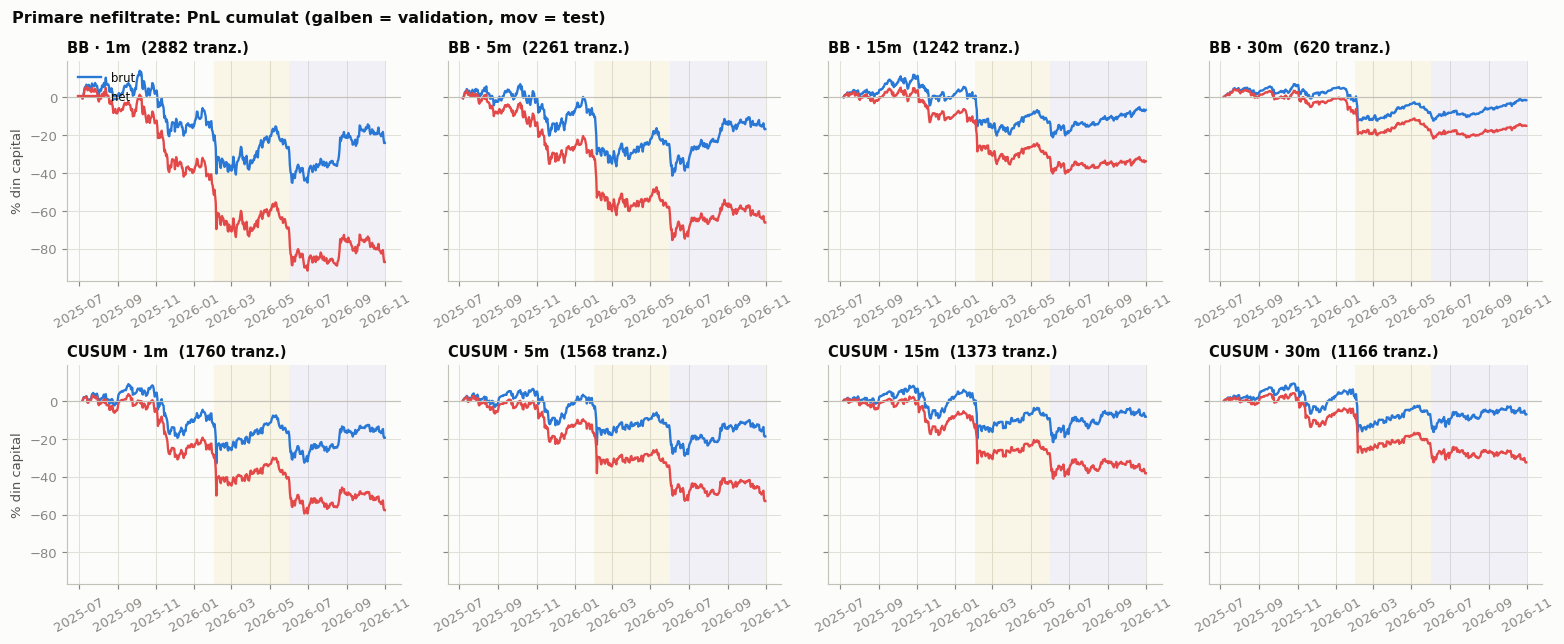

In [14]:
def shade(ax):
    ax.axvspan(VAL_START, TEST_START, color=C["yellow"], alpha=0.08, lw=0)
    ax.axvspan(TEST_START, DATA_END, color=C["purple"], alpha=0.07, lw=0)
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for i, p in enumerate(PRIMS):
    for j, R in enumerate(RES):
        ax = axes[i, j]
        T, g, n, expo = PRIM_CURVES[(p, R)]
        ax.plot(100 * g.cumsum(), color=C["blue"], label="brut"); ax.plot(100 * n.cumsum(), color=C["red"], label="net")
        shade(ax); ax.axhline(0, color=AXIS, lw=0.8)
        ax.set_title(f"{p} · {R}m  ({len(T)} tranz.)"); ax.tick_params(axis="x", rotation=30)
        if j == 0: ax.set_ylabel("% din capital")
axes[0, 0].legend(loc="upper left")
fig.suptitle("Primare nefiltrate: PnL cumulat (galben = validation, mov = test)", x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout(); plt.show()

### 5.3 Rezultate lunare (portofoliu, net, % din capital)

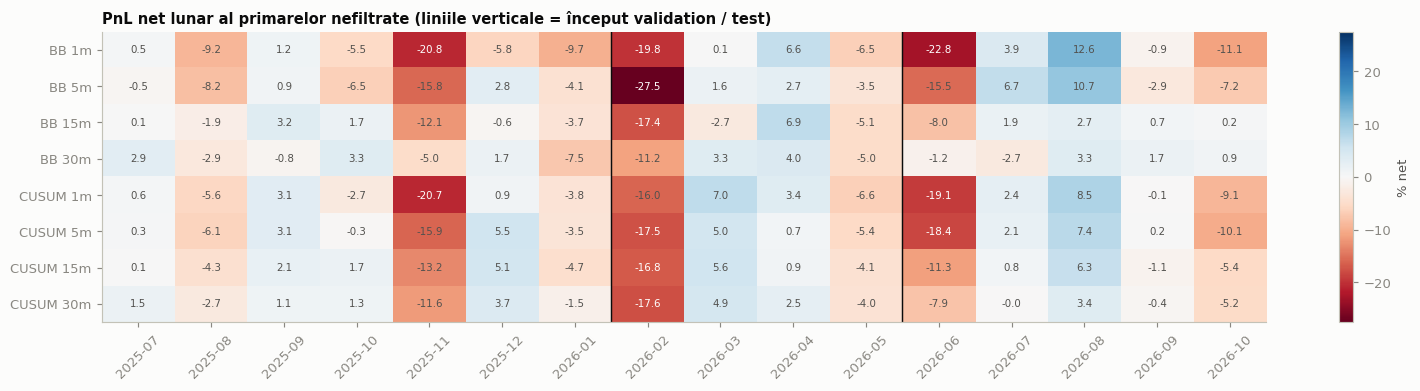

Luni cu PnL net pozitiv (din 16; iul. 2025 parțial): {'BB 1m': 6, 'BB 5m': 6, 'BB 15m': 8, 'BB 30m': 8, 'CUSUM 1m': 7, 'CUSUM 5m': 8, 'CUSUM 15m': 8, 'CUSUM 30m': 7}


In [15]:
MON = {}
for (p, R), (T, g, n, expo) in PRIM_CURVES.items():
    MON[f"{p} {R}m"] = n.groupby(n.index.to_period("M")).sum() * 100
MON = pd.DataFrame(MON).T
fig, ax = plt.subplots(figsize=(15, 3.8))
v = np.nanmax(np.abs(MON.to_numpy()))
im = ax.imshow(MON.to_numpy(), cmap="RdBu", vmin=-v, vmax=v, aspect="auto")
ax.set_yticks(range(len(MON)), MON.index); ax.set_xticks(range(MON.shape[1]), [str(c) for c in MON.columns], rotation=45); ax.grid(False)
for a in range(MON.shape[0]):
    for b in range(MON.shape[1]):
        ax.text(b, a, f"{MON.iat[a, b]:.1f}", ha="center", va="center", fontsize=7, color="white" if abs(MON.iat[a, b]) > 0.6 * v else INK2)
ax.axvline(list(MON.columns.astype(str)).index("2026-02") - 0.5, color=INK, lw=1); ax.axvline(list(MON.columns.astype(str)).index("2026-06") - 0.5, color=INK, lw=1)
fig.colorbar(im, ax=ax, label="% net"); ax.set_title("PnL net lunar al primarelor nefiltrate (liniile verticale = început validation / test)")
fig.tight_layout(); plt.show()
print("Luni cu PnL net pozitiv (din 16; iul. 2025 parțial):", {k: int((r > 0).sum()) for k, r in MON.iterrows()})

### 5.4 Bariere, durate și proporții TP / SL / timeout (toate evenimentele)

n  TP med (bps) TP p10–p90  SL med (bps)  TP %  SL %  timeout+ %  timeout− %  durată med (h)  durată TP med (h)  durată SL med (h)  depășire TP med (bps)  depășire SL med (bps)  uniqueness medie
primară rezoluție                                                                                                                                                                                                        
BB      1m         20539         175.2    119–288         350.4 29.87 10.09       25.21       34.83              24              10.99              13.72                   4.77                   6.27              0.03
        5m          4167         174.2    120–287         348.3 29.81 10.13       25.82       34.25              24              10.92              13.63                   4.81                   5.63              0.15
        15m         1332         176.3    118–289         352.6 31.91 11.26       23.27       33.56              24               9.87              13.18                   4.15                   5.85              0.38
        30m          624         172.1    117–282         344.1 33.17 13.46       21.47       31.89              24                9.6              12.77                   4.95                   6.62              0.59
CUSUM   1m          3239         166.7    119–276         333.4  36.4 14.39       20.13       29.08           23.62                  9              12.45                   4.68                   6.68              0.17
        5m          2299         173.6    120–285         347.2 34.67 13.79       21.01       30.54              24               9.38              12.43                   4.49                   5.86              0.23
        15m         1657           174    122–281           348 34.88 13.16       19.73       32.23              24               9.98              13.02                   4.92                   6.26              0.31
        30m         1268         171.4    121–281         342.9 33.91 13.01        20.5       32.57              24              10.06              13.15                   5.27                   5.94              0.39

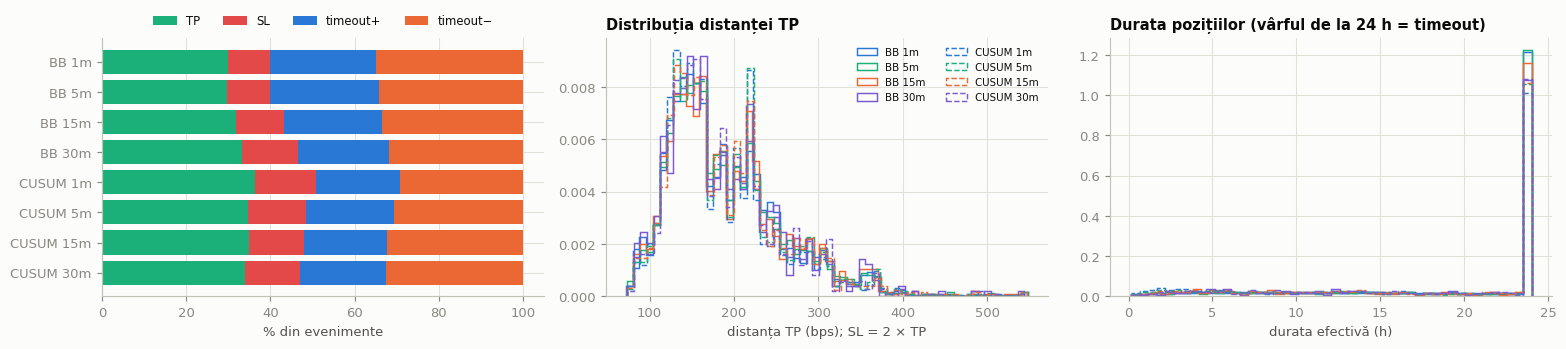

In [16]:
rows = []
for (p, R), L in EV.items():
    oc = L["outcome"].value_counts(normalize=True)
    rows.append({"primară": p, "rezoluție": f"{R}m", "n": len(L), "TP med (bps)": L["tp_bps"].median(), "TP p10–p90": f"{L['tp_bps'].quantile(.1):.0f}–{L['tp_bps'].quantile(.9):.0f}",
                 "SL med (bps)": L["sl_bps"].median(), "TP %": 100 * oc.get("TP", 0), "SL %": 100 * oc.get("SL", 0),
                 "timeout+ %": 100 * oc.get("timeout+", 0), "timeout− %": 100 * oc.get("timeout−", 0),
                 "durată med (h)": L["hold_min"].median() / 60, "durată TP med (h)": L.loc[L.outcome == "TP", "hold_min"].median() / 60,
                 "durată SL med (h)": L.loc[L.outcome == "SL", "hold_min"].median() / 60,
                 "depășire TP med (bps)": (L.loc[L.outcome == "TP", "gross_bps"] - L.loc[L.outcome == "TP", "tp_bps"]).median(),
                 "depășire SL med (bps)": (-L.loc[L.outcome == "SL", "gross_bps"] - L.loc[L.outcome == "SL", "sl_bps"]).median(),
                 "uniqueness medie": L["w"].mean()})
BAR_T = pd.DataFrame(rows).set_index(["primară", "rezoluție"])
display(BAR_T.round(2))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
labels = [f"{p} {R}m" for p in PRIMS for R in RES]
oc = np.array([[ (EV[(p, R)]["outcome"] == o).mean() for o in ["TP", "SL", "timeout+", "timeout−"]] for p in PRIMS for R in RES])
left = np.zeros(len(labels))
for k, (o, col) in enumerate(zip(["TP", "SL", "timeout+", "timeout−"], [C["aqua"], C["red"], C["blue"], C["orange"]])):
    axes[0].barh(labels, 100 * oc[:, k], left=left, color=col, label=o); left += 100 * oc[:, k]
axes[0].invert_yaxis(); axes[0].legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0)); axes[0].set_xlabel("% din evenimente")
for p, ls in zip(PRIMS, ["-", "--"]):
    for R, col in zip(RES, [C["blue"], C["aqua"], C["orange"], C["purple"]]):
        L = EV[(p, R)]
        axes[1].hist(L["tp_bps"], bins=60, histtype="step", color=col, ls=ls, density=True, label=f"{p} {R}m")
        axes[2].hist(L["hold_min"] / 60, bins=48, histtype="step", color=col, ls=ls, density=True)
axes[1].set_xlabel("distanța TP (bps); SL = 2 × TP"); axes[1].set_title("Distribuția distanței TP"); axes[1].legend(ncol=2, fontsize=7)
axes[2].set_xlabel("durata efectivă (h)"); axes[2].set_title("Durata pozițiilor (vârful de la 24 h = timeout)")
fig.tight_layout(); plt.show()

**Ce arată primarele nefiltrate.**
* **Avantajul brut nu se distinge de zero nicăieri.** În toate cele 24 de combinații primară × rezoluție × segment, intervalul de încredere al randamentului brut pe eveniment include zero și are o lățime de ±25–80 bps. Estimările punctuale sunt mici și își schimbă semnul de la un segment la altul (de exemplu BB 30m: −4,8 bps pe train, −23 pe validation, +17 pe test).
* **Costul este de ~11 bps pe tranzacție**: 10 bps comision, ~1 bp funding (rata a fost pozitivă în 81% din decontări, deci long-ul plătește) și slippage din book neglijabil pentru 10.000 USDT (~0,01 bps pe parte). Latența decizie → intrare este practic zero în medie. Cu un avantaj brut de câțiva bps, costul domină, iar PnL-ul net este negativ în aproape toate celulele. Singura excepție, BB 30m pe test (+5,7 bps net pe eveniment), are un IC care include zero și pierde −33 bps pe validation.
* **Rezultatele lunare sunt dominate de piață, nu de strategie.** Toate cele 8 variante pierd în aceleași luni (nov. 2025, feb. 2026, iun. 2026) și câștigă în aceleași (aug. 2026). O poziție long cu SL de 2σ și orizont de 24 h este în primul rând o expunere la direcția BTC.
* **Rezoluția schimbă frecvența, nu natura.** BB scade de la ~43 de semnale/zi (1m) la ~1,4/zi (30m), iar CUSUM de la ~6 la ~2,4/zi. Distanțele TP/SL sunt aceleași la toate rezoluțiile (median ~172–176 / ~345–352 bps), pentru că volatilitatea este comună. Proporțiile rezultatelor variază puțin: TP 30–36%, SL 10–14%, timeout 52–60%. Prețul de ieșire depășește bariera cu ~4–5 bps la TP și ~6 bps la SL, o consecință a observării la nivel de minut.
* La 1m, semnalele BB se suprapun masiv (uniqueness medie 0,03): cele ~20.000 de evenimente conțin informația a doar câteva sute de observații independente.

## 6. Modele secundare pe fiecare primară și rezoluție (ținta: TP atins primul)

**Ținta.** `y_tp = bin` din `ml.labeling.get_bins` cu side = +1. Am verificat în secțiunea 4 că, în versiunea instalată, `bin = 1` ⇔ TP atins înaintea SL și a expirării; `bin = 0` pentru SL, timeout pozitiv și timeout negativ. Nu a fost nevoie de o țintă reconstruită. Pentru claritate, păstrăm și rezultatul în 4 clase (`outcome`), din care derivăm ținta „atingere vs timeout” din secțiunea 10.

**Antrenare.** Numai pe train, cu ponderi de **uniqueness medie** (`ml.sampling.get_av_uniqueness_from_triple_barrier`, normalizate la media 1). Etichetele de 24 h se suprapun puternic: la BB 1m, uniqueness medie este 0,03, adică ~12.000 de evenimente de train echivalează cu câteva sute de observații independente. Ponderile evită ca episoadele cu multe semnale consecutive să domine modelul.

* **LR-L2**: winsorizare la percentilele 1/99 din train, imputare cu mediana din train, standardizare, `C = 0.1`.
* **Random Forest**: imputare cu mediana din train, 300 de arbori, `max_features = sqrt`, `min_samples_leaf = max(10, n/100)`, `max_samples` = uniqueness medie (AFML, cap. 4).
* **LightGBM**: arbori de adâncime 3 (7 frunze), 200 de iterații cu rata 0,03, `min_child_samples = max(20, n/50)`, subeșantionare 0,7 pe rânduri și coloane, `lambda_l2 = 10`. Valorile lipsă sunt tratate nativ.

Hiperparametrii sunt **ficși și identici** pentru toate celulele. Studiile anterioare pe acest set au arătat că optimizarea lor la acest nivel de semnal găsește zgomot. Complexitatea arborilor crește proporțional cu n, prin pragurile relative pe frunze.

In [17]:
DS = {(p, R): EV[(p, R)] for p in PRIMS for R in RES}         # registrul de seturi de evenimente (completat mai jos cu reuniuni și primare aleatoare)

class Prep:
    def __init__(self, X, linear):
        self.linear = linear
        self.med = np.nanmedian(X, 0); self.med = np.where(np.isfinite(self.med), self.med, 0.0)
        if linear:
            self.lo, self.hi = np.nanpercentile(X, 1, 0), np.nanpercentile(X, 99, 0)
            Z = self._clip(X)
            self.mu, self.sd = Z.mean(0), Z.std(0); self.sd[self.sd == 0] = 1.0
    def _clip(self, X):
        Z = np.clip(X, self.lo, self.hi)
        return np.where(np.isnan(Z), self.med, Z)
    def __call__(self, X):
        if self.linear:
            return (self._clip(X) - self.mu) / self.sd
        return np.where(np.isnan(X), self.med, X)

def fit_model(name, X, y, w, seed, avg_uniq=0.5):
    n = len(y)
    if name == "LR":
        prep = Prep(X, True)
        m = LogisticRegression(C=0.1, max_iter=5000).fit(prep(X), y, sample_weight=w)
        imp = np.abs(m.coef_[0])
    elif name == "RF":
        prep = Prep(X, False)
        m = RandomForestClassifier(n_estimators=300, max_features="sqrt", min_samples_leaf=max(10, n // 100), bootstrap=True,
                                   max_samples=float(np.clip(avg_uniq, 0.1, 1.0)),
                                   n_jobs=1, random_state=seed).fit(prep(X), y, sample_weight=w)
        imp = m.feature_importances_
    else:
        prep = None
        m = LGBMClassifier(n_estimators=200, learning_rate=0.03, num_leaves=7, max_depth=3, min_child_samples=max(20, n // 50), subsample=0.7,
                           subsample_freq=1, colsample_bytree=0.7, reg_lambda=10.0, num_threads=1, verbose=-1, random_state=seed).fit(X, y, sample_weight=w)
        imp = m.booster_.feature_importance("gain"); imp = imp / max(imp.sum(), 1e-12)
    pred = (lambda Z: m.predict_proba(prep(Z))[:, 1]) if prep is not None else (lambda Z: m.predict_proba(Z)[:, 1])
    return pred, imp

def ll_vec(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))

def run_task(task):
    """Antrenează un model pe un set de train și întoarce predicțiile pe seturile de evaluare (+ importanțe, la cerere)."""
    try:
        D = DS[task["ds"]]
        tr = D[D["seg"] == "train"]
        if task.get("sub"):
            tr = tr.sample(n=min(task["sub"], len(tr)), random_state=task["seed"])
        feats = task.get("feats", FEATS)
        X, y = tr[feats].to_numpy(float), tr[task["target"]].to_numpy(int)
        w = tr["w"].to_numpy(float); w = w / w.mean()
        pred, imp = fit_model(task["model"], X, y, w, task["seed"], float(tr["w"].mean()))
        out = {"imp": imp, "base_train": float(np.average(y, weights=w)), "n_train": len(y), "preds": {}}
        for ek in task.get("evals", [(task["ds"], "val"), (task["ds"], "test")]):
            E = DS[ek[0]]; E = E[E["seg"] == ek[1]]
            out["preds"][ek] = pred(E[feats].to_numpy(float)).astype(np.float32)
        if task.get("perm"):
            rng = np.random.default_rng(task["seed"] + 7)
            out["perm"] = {}
            for seg in ("val", "test"):
                E = D[D["seg"] == seg]
                Xe, ye = E[feats].to_numpy(float), E[task["target"]].to_numpy(int)
                base = ll_vec(ye, pred(Xe))
                fam_d = np.zeros((len(ye), len(FAMILIES)), np.float32)
                for j, (fam, cols) in enumerate(FAMILIES.items()):
                    ci = [feats.index(c) for c in cols]
                    for _ in range(5):
                        Xp = Xe.copy(); Xp[:, ci] = Xe[rng.permutation(len(ye))][:, ci]
                        fam_d[:, j] += (ll_vec(ye, pred(Xp)) - base) / 5
                ft_d = np.zeros((len(ye), len(feats)), np.float32)
                for j in range(len(feats)):
                    for _ in range(3):
                        Xp = Xe.copy(); Xp[:, j] = Xe[rng.permutation(len(ye)), j]
                        ft_d[:, j] += (ll_vec(ye, pred(Xp)) - base) / 3
                out["perm"][seg] = (fam_d, ft_d)
        return task["id"], out
    except Exception as ex:                       # erorile sunt raportate, nu ascunse
        import traceback
        return task["id"], {"error": traceback.format_exc()}

def run_tasks(tasks, label):
    t0 = time.time()
    res = {}
    import multiprocessing as mp
    with ProcessPoolExecutor(max_workers=WORKERS, mp_context=mp.get_context("fork")) as ex:
        for tid, out in ex.map(run_task, tasks, chunksize=1):
            if "error" in out:
                raise RuntimeError(f"task {tid} a eșuat:\n{out['error']}")
            res[tid] = out
    print(f"{label}: {len(tasks)} modele antrenate în {time.time() - t0:.0f} s")
    return res

MODELS = ["LR", "RF", "LGBM"]
def seed_of(*parts):
    return int(hashlib.md5(repr(parts).encode()).hexdigest()[:8], 16) % 10**8

In [18]:
def day_codes(E):
    return pd.to_datetime(E["dec"]).dt.floor("D").to_numpy()

def auc_ci(y, p, days, n_boot=300, block=5, seed=0):
    """IC 95% pentru AUC: bootstrap circular pe blocuri de 5 zile consecutive (etichetele de 24 h leagă zilele vecine)."""
    if len(np.unique(y)) < 2:
        return np.nan, np.nan
    ud, inv = np.unique(days, return_inverse=True)
    groups = [np.flatnonzero(inv == k) for k in range(len(ud))]
    nd = len(ud); nb = int(np.ceil(nd / block))
    rng = np.random.default_rng(seed); out = []
    for _ in range(n_boot):
        st = rng.integers(0, nd, nb)
        dd = ((st[:, None] + np.arange(block)[None, :]).ravel()[:nd]) % nd
        idx = np.concatenate([groups[k] for k in dd])
        if len(np.unique(y[idx])) == 2:
            out.append(roc_auc_score(y[idx], p[idx]))
    return np.percentile(out, 2.5), np.percentile(out, 97.5)

def clf_metrics(y, p, base, days=None, ci=True):
    p = np.clip(p.astype(float), 1e-6, 1 - 1e-6)
    ll, llc = log_loss(y, p, labels=[0, 1]), log_loss(y, np.full(len(y), base), labels=[0, 1])
    bs, bsc = brier_score_loss(y, p), brier_score_loss(y, np.full(len(y), base))
    auc = roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan
    lo, hi = auc_ci(y, p, days) if (ci and days is not None) else (np.nan, np.nan)
    return {"n": len(y), "rată pozitivă": y.mean(), "AUC": auc, "AUC IC95 jos": lo, "AUC IC95 sus": hi,
            "PR-AUC": average_precision_score(y, p) if len(np.unique(y)) == 2 else np.nan,
            "log loss": ll, "log loss constant": llc, "skill log loss %": 100 * (1 - ll / llc), "Brier": bs, "Brier constant": bsc, "skill Brier %": 100 * (1 - bs / bsc),
            "p medie": p.mean()}

def clf_report(y, p, thr):
    yh = (p >= thr).astype(int)
    pr, rc, f1, sup = precision_recall_fscore_support(y, yh, labels=[0, 1], zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    return {"prag": thr, "precizie 0": pr[0], "recall 0": rc[0], "F1 0": f1[0], "suport 0": sup[0], "precizie 1": pr[1], "recall 1": rc[1], "F1 1": f1[1],
            "suport 1": sup[1], "acuratețe": (yh == y).mean(), "F1 macro": f1.mean(), "TN": tn, "FP": fp, "FN": fn, "TP": tp}

def base_tasks(target):
    return [{"id": (target, p, R, m), "ds": (p, R), "target": target, "model": m, "seed": seed_of(p, R, m), "perm": True}
            for p in PRIMS for R in RES for m in MODELS]
BASE = cached("base_models", lambda: run_tasks(base_tasks("y_tp") + base_tasks("touch"), "Modele de bază (2 ținte × 2 primare × 4 rezoluții × 3 modele)"))

def eval_table(target, seg="test", ci=True):
    rows, reps = {}, {}
    for p in PRIMS:
        for R in RES:
            E = DS[(p, R)]; E = E[E["seg"] == seg]
            y = E[target].to_numpy(int)
            for m in MODELS:
                o = BASE[(target, p, R, m)]
                pr = o["preds"][((p, R), seg)].astype(float)
                rows[(p, f"{R}m", m)] = {"n train": o["n_train"], "rată train (ponderată)": o["base_train"], **clf_metrics(y, pr, o["base_train"], day_codes(E), ci=ci)}
                reps[(p, f"{R}m", m)] = clf_report(y, pr, o["base_train"])
    T = pd.DataFrame(rows).T; T.index.names = ["primară", "rezoluție", "model"]
    Rp = pd.DataFrame(reps).T; Rp.index.names = T.index.names
    return T, Rp
M_TP_TEST, REP_TP_TEST = eval_table("y_tp", "test")
M_TP_VAL, _ = eval_table("y_tp", "val", ci=False)

Modele de bază (2 ținte × 2 primare × 4 rezoluții × 3 modele): 48 modele antrenate în 45 s


### 6.1 Metrici de clasificare pe test (ținta TP)

`skill log loss` și `skill Brier` compară modelul cu o predicție constantă egală cu rata pozitivă din train. O valoare negativă înseamnă probabilități mai proaste decât constanta, chiar dacă AUC > 0,5. IC95 al AUC: bootstrap circular pe blocuri de 5 zile consecutive.

n train     n  rată train (ponderată)  rată pozitivă   AUC  AUC validation  AUC IC95 jos  AUC IC95 sus  PR-AUC  log loss  skill log loss %  Brier  skill Brier %
primară rezoluție model                                                                                                                                                                  
BB      1m        LR       8,928 6,452                   0.372          0.284 0.582           0.536         0.521         0.646   0.323     0.615            -0.173  0.213         -0.997
                  RF       8,928 6,452                   0.372          0.284 0.574           0.493         0.492         0.651   0.343     0.604             1.561  0.207           2.03
                  LGBM     8,928 6,452                   0.372          0.284 0.554           0.497         0.465         0.638   0.349     0.642            -4.536  0.225         -6.414
        5m        LR       1,809 1,332                   0.374          0.295 0.588            0.53         0.522         0.648   0.366     0.615             0.844  0.213          0.688
                  RF       1,809 1,332                   0.374          0.295 0.572           0.508         0.504         0.632   0.391      0.61             1.758  0.209           2.31
                  LGBM     1,809 1,332                   0.374          0.295 0.562           0.523         0.488         0.636   0.395     0.644            -3.784  0.226         -5.429
        15m       LR         622   399                    0.37          0.333 0.572           0.542         0.499         0.638   0.418     0.645            -0.928  0.225         -0.672
                  RF         622   399                    0.37          0.333 0.547            0.46         0.472          0.61   0.398     0.635             0.611  0.222          0.817
                  LGBM       622   399                    0.37          0.333 0.545           0.493         0.468         0.605   0.407     0.656            -2.572  0.231         -3.426
        30m       LR         294   198                   0.345          0.338 0.462           0.513         0.375         0.541   0.346     0.687            -7.344  0.244         -9.135
                  RF         294   198                   0.345          0.338 0.466           0.454         0.391         0.542   0.333     0.655            -2.361  0.231          -2.96
                  LGBM       294   198                   0.345          0.338 0.424           0.527         0.356         0.502   0.295      0.69            -7.868  0.246         -9.727
CUSUM   1m        LR       1,228 1,349                   0.395          0.373  0.53           0.546          0.48         0.575   0.386     0.694            -4.899  0.248          -5.97
                  RF       1,228 1,349                   0.395          0.373 0.494           0.541          0.43         0.563   0.391     0.665            -0.544  0.236         -0.726
                  LGBM     1,228 1,349                   0.395          0.373 0.527           0.528         0.459         0.597   0.402     0.681            -2.928  0.243          -3.86
        5m        LR         877   946                    0.39          0.354 0.513           0.559         0.461         0.576   0.359     0.695            -6.515  0.247         -7.336
                  RF         877   946                    0.39          0.354  0.51           0.526         0.441         0.576   0.375     0.656            -0.529  0.232         -0.681
                  LGBM       877   946                    0.39          0.354 0.489           0.537         0.422          0.55   0.379     0.685             -4.95  0.244         -6.003
        15m       LR         642   662                   0.368          0.363 0.518           0.581         0.449         0.587   0.404     0.692            -5.667  0.246         -6.404
                  RF         642   662                   0.368          0.363 0.477           0.518          0.41      

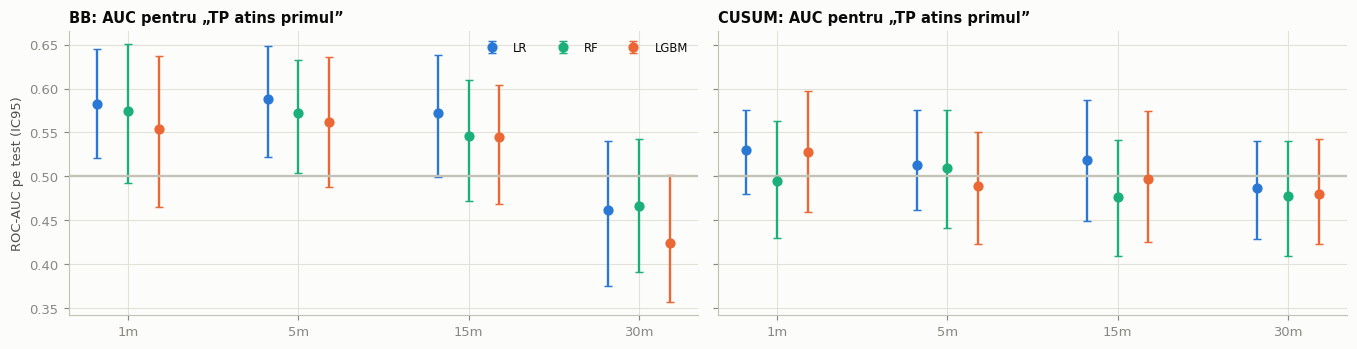

In [19]:
show = ["n train", "n", "rată train (ponderată)", "rată pozitivă", "AUC", "AUC IC95 jos", "AUC IC95 sus", "PR-AUC", "log loss", "skill log loss %", "Brier", "skill Brier %"]
T = M_TP_TEST[show].astype(float).copy()
T.insert(5, "AUC validation", M_TP_VAL["AUC"].astype(float))
display(T.round(3))

def auc_panel(Mtest, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), sharey=True)
    for ax, p in zip(axes, PRIMS):
        for k, m in enumerate(MODELS):
            sub = Mtest.xs((p, m), level=("primară", "model"))
            x = np.arange(len(RES)) + (k - 1) * 0.18
            a = sub["AUC"].astype(float).to_numpy(); lo = sub["AUC IC95 jos"].astype(float).to_numpy(); hi = sub["AUC IC95 sus"].astype(float).to_numpy()
            ax.errorbar(x, a, yerr=[a - lo, hi - a], fmt="o", color=MODEL_COLORS[m], label=m, capsize=3)
        ax.axhline(0.5, color=AXIS); ax.set_xticks(range(len(RES)), [f"{R}m" for R in RES]); ax.set_title(f"{p}: {title}")
    axes[0].set_ylabel("ROC-AUC pe test (IC95)"); axes[0].legend(ncol=3)
    fig.tight_layout(); plt.show()
auc_panel(M_TP_TEST, "AUC pentru „TP atins primul”")

### 6.2 Classification report și matrice de confuzie (test)

Pragul de decizie este rata pozitivă (ponderată) din train: un eveniment este clasificat „1” dacă probabilitatea estimată depășește frecvența medie. Un prag fix de 0,5 ar clasifica aproape totul drept „0” la o rată pozitivă de ~30% și nu ar fi informativ. Pragul de filtrare economică este ales separat, pe validation, în secțiunea 7.

In [20]:
display(REP_TP_TEST.astype(float).round(3))

prag  precizie 0  recall 0  F1 0  suport 0  precizie 1  recall 1  F1 1  suport 1  acuratețe  F1 macro    TN    FP    FN    TP
primară rezoluție model                                                                                                                               
BB      1m        LR    0.372       0.765     0.559 0.646     4,617       0.339     0.569 0.425     1,835      0.562     0.535 2,580 2,037   791 1,044
                  RF    0.372       0.746     0.678  0.71     4,617        0.34     0.418 0.375     1,835      0.604     0.543 3,129 1,488 1,068   767
                  LGBM  0.372       0.735     0.346 0.471     4,617       0.294     0.686 0.412     1,835      0.443     0.441 1,599 3,018   577 1,258
        5m        LR    0.374       0.752     0.601 0.668       939       0.356     0.527 0.425       393      0.579     0.546   564   375   186   207
                  RF    0.374       0.747     0.629 0.683       939       0.357     0.491 0.413       393      0.589     0.548   591   348   200   193
                  LGBM  0.374       0.734     0.396 0.515       939       0.313     0.656 0.424       393      0.473     0.469   372   567   135   258
        15m       LR     0.37       0.714     0.609 0.657       266       0.395     0.511 0.446       133      0.576     0.552   162   104    65    68
                  RF     0.37       0.702      0.62 0.659       266       0.384     0.474 0.424       133      0.571     0.541   165   101    70    63
                  LGBM   0.37       0.651     0.406   0.5       266       0.322     0.564  0.41       133      0.459     0.455   108   158    58    75
        30m       LR    0.345       0.624     0.443 0.518       131       0.305     0.478 0.372        67      0.455     0.445    58    73    35    32
                  RF    0.345       0.659     0.443  0.53       131       0.336     0.552 0.418        67       0.48     0.474    58    73    30    37
                  LGBM  0.345       0.615      0.55 0.581       131       0.272     0.328 0.297        67      0.475     0.439    72    59    45    22
CUSUM   1m        LR    0.395        0.63     0.595 0.612       846       0.377     0.414 0.395       503      0.527     0.503   503   343   295   208
                  RF    0.395       0.617     0.499 0.552       846       0.362     0.479 0.413       503      0.491     0.482   422   424   262   241
                  LGBM  0.395       0.638     0.577 0.606       846       0.387     0.449 0.416       503      0.529     0.511   488   358   277   226
        5m        LR     0.39       0.643     0.651 0.647       611       0.349      0.34 0.344       335      0.541     0.496   398   213   221   114
                  RF     0.39       0.654     0.668 0.661       611        0.37     0.355 0.362       335      0.557     0.511   408   203   216   119
                  LGBM   0.39       0.649     0.614 0.631       611       0.359     0.394 0.376       335      0.536     0.503   375   236   203   132
        15m       LR    0.368       0.632     0.562 0.595       422       0.355     0.425 0.387       240      0.512     0.491   237   185   138   102
                  RF    0.368        0.64     0.616 0.628       422       0.367     0.392 0.379       240      0.535     0.504   260   162   146    94
                  LGBM  0.368       0.645     0.675  0.66       422       0.377     0.346 0.361       240      0.556      0.51   285   137   157    83
        30m       LR    0.376       0.638     0.527 0.577       338       0.316     0.423 0.362       175      0.491     0.469   178   160   101    74
                  RF    0.376       0.623     0.464 0.532       338       0.307     0.457 0.367       175      0.462      0.45   157   181    95    80
                  LGBM  0.376       0.649     0.559 0.601       338       0.329     0.417 0.368       175      0.511     0.484   189   149   102    73

### 6.3 Calibrare: probabilitate estimată vs frecvența reală a atingerii TP (test)

Punctele sunt decile ale probabilității estimate de fiecare model (cvintile când n < 300), cu numărul de evenimente pe punct notat în titlu. Linia gri este calibrarea perfectă, iar linia punctată orizontală este rata pozitivă din test.

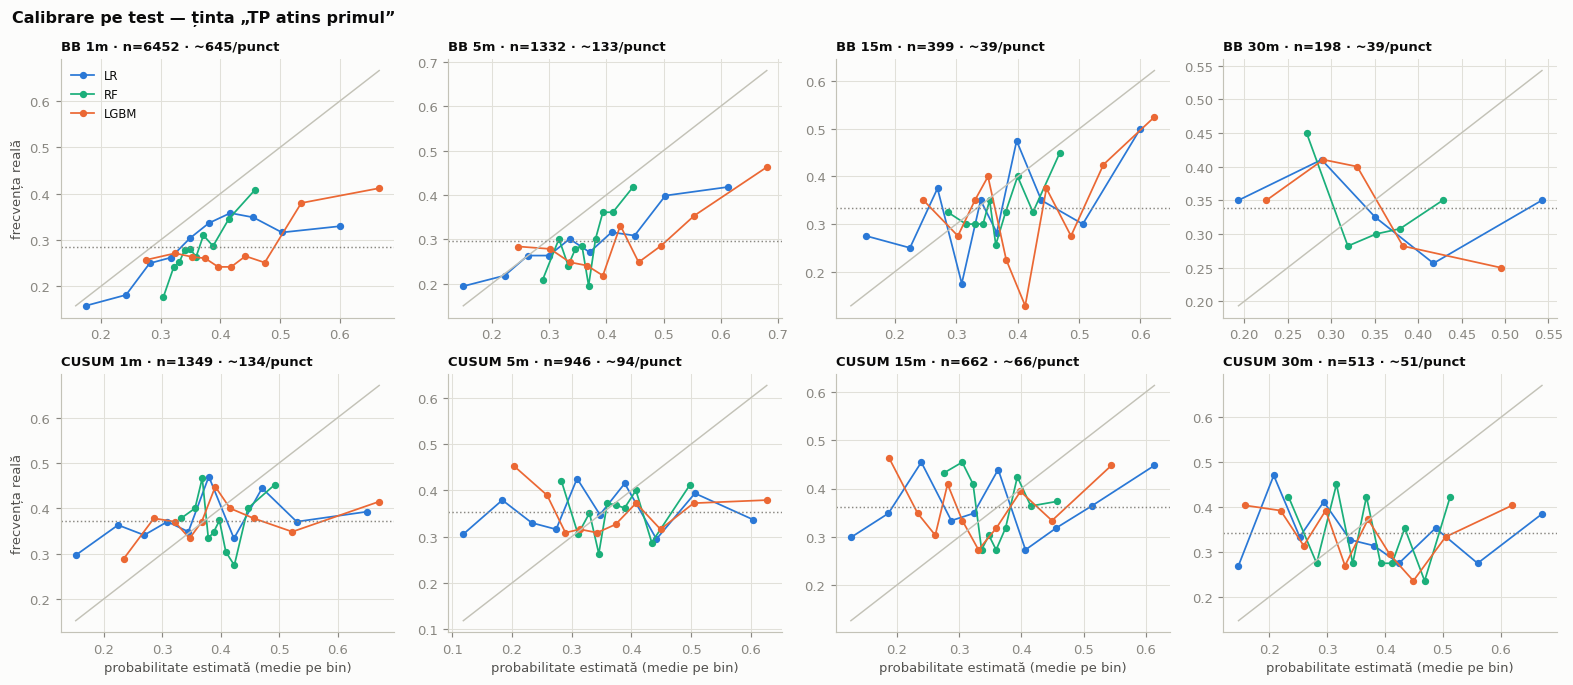

In [21]:
def calib_grid(target, title):
    fig, axes = plt.subplots(2, 4, figsize=(15, 6.6))
    for i, p in enumerate(PRIMS):
        for j, R in enumerate(RES):
            ax = axes[i, j]
            E = DS[(p, R)]; E = E[E["seg"] == "test"]; y = E[target].to_numpy(int)
            nb = 10 if len(y) >= 300 else 5
            lo_, hi_ = 1, 0
            for m in MODELS:
                pr = BASE[(target, p, R, m)]["preds"][((p, R), "test")].astype(float)
                q = pd.qcut(pr, nb, labels=False, duplicates="drop")
                g = pd.DataFrame({"p": pr, "y": y, "q": q}).groupby("q").agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))
                ax.plot(g["p"], g["y"], "o-", color=MODEL_COLORS[m], ms=4, lw=1.2, label=m)
                lo_, hi_ = min(lo_, g["p"].min(), g["y"].min()), max(hi_, g["p"].max(), g["y"].max())
            ax.plot([lo_, hi_], [lo_, hi_], color=AXIS, lw=1); ax.axhline(y.mean(), color=MUTED, ls=":", lw=1)
            ax.set_title(f"{p} {R}m · n={len(y)} · ~{len(y) // nb}/punct", fontsize=9)
            if j == 0: ax.set_ylabel("frecvența reală")
            if i == 1: ax.set_xlabel("probabilitate estimată (medie pe bin)")
    axes[0, 0].legend()
    fig.suptitle(title, x=0.01, ha="left", fontsize=11, fontweight="semibold"); fig.tight_layout(); plt.show()
calib_grid("y_tp", "Calibrare pe test — ținta „TP atins primul”")

### 6.4 Stabilitate pe subperioade (lunile din validation și test)

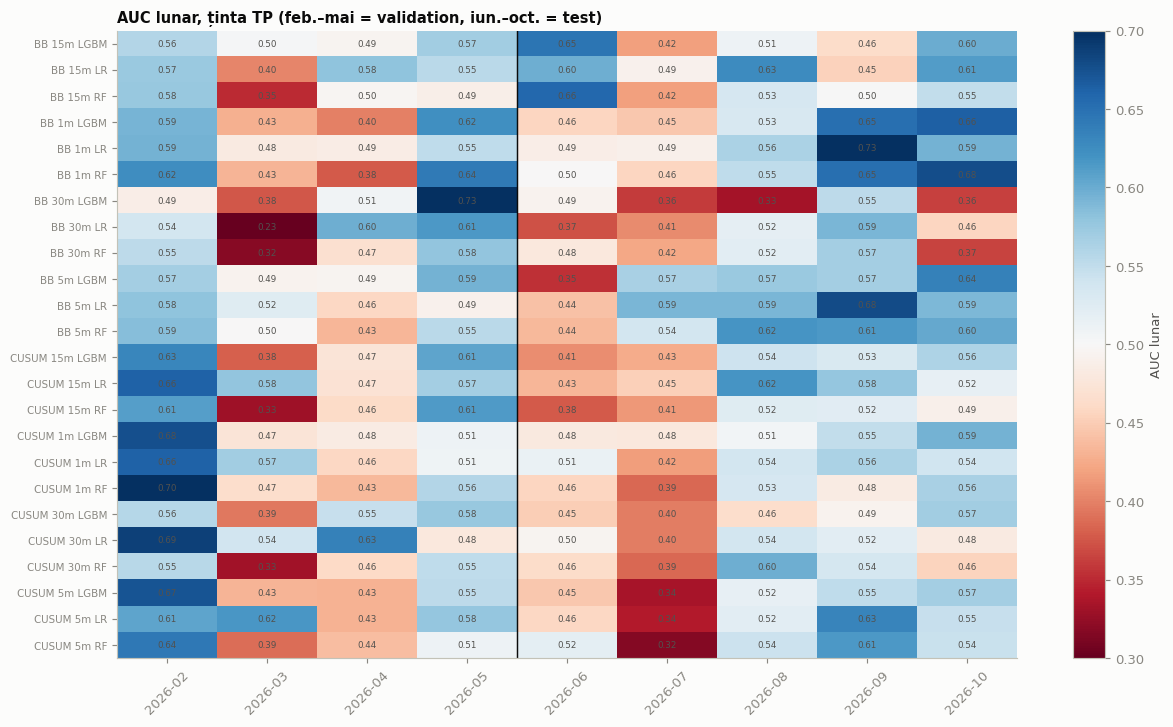

luni cu AUC > 0,5  luni evaluate  AUC lunar median  AUC lunar min  AUC lunar max
BB    1m  LR                    5              9             0.551          0.482          0.735
          RF                    5              9             0.551          0.377          0.677
          LGBM                  5              9             0.532          0.399          0.663
      5m  LR                    6              9             0.581          0.442          0.678
          RF                    6              9             0.555          0.434          0.619
          LGBM                  6              9             0.567          0.355          0.635
      15m LR                    6              9             0.575          0.402          0.626
          RF                    4              9               0.5          0.351          0.657
          LGBM                  6              9              0.51          0.418          0.647
      30m LR                    5              9             0.518          0.226          0.615
          RF                    4              9              0.48          0.317          0.578
          LGBM                  3              9             0.486          0.333          0.734
CUSUM 1m  LR                    7              9             0.537          0.416          0.662
          RF                    4              9             0.483          0.386            0.7
          LGBM                  5              9             0.505          0.473          0.676
      5m  LR                    6              9             0.547          0.341          0.632
          RF                    6              9             0.519          0.317          0.643
          LGBM                  5              9             0.516          0.336          0.673
      15m LR                    6              9             0.567          0.434          0.662
          RF                    4              9             0.489           0.33          0.613
          LGBM                  5              9             0.531          0.381          0.631
      30m LR                    5              9             0.521          0.398          0.687
          RF                    4              9             0.463          0.331          0.598
          LGBM                  4              9             0.492          0.395          0.576

In [22]:
def monthly_metric(target):
    rows = {}
    for p in PRIMS:
        for R in RES:
            for m in MODELS:
                o = BASE[(target, p, R, m)]
                for seg in ("val", "test"):
                    E = DS[(p, R)]; E = E[E["seg"] == seg]
                    pr = o["preds"][((p, R), seg)].astype(float); y = E[target].to_numpy(int)
                    mon = pd.to_datetime(E["dec"]).dt.to_period("M").to_numpy()
                    for mo in np.unique(mon):
                        k = mon == mo
                        if k.sum() >= 20 and 0 < y[k].mean() < 1:
                            rows[(p, f"{R}m", m, str(mo))] = {"AUC": roc_auc_score(y[k], pr[k]), "n": int(k.sum()),
                                                              "skill Brier %": 100 * (1 - brier_score_loss(y[k], pr[k]) / brier_score_loss(y[k], np.full(k.sum(), o["base_train"])))}
    return pd.DataFrame(rows).T
MON_TP = monthly_metric("y_tp")
def monthly_heat(MONX, title):
    A = MONX["AUC"].astype(float).unstack(-1)
    fig, ax = plt.subplots(figsize=(12, 7))
    im = ax.imshow(A.to_numpy(), cmap="RdBu", vmin=0.3, vmax=0.7, aspect="auto")
    ax.set_yticks(range(len(A)), [" ".join(map(str, k)) for k in A.index], fontsize=7); ax.set_xticks(range(A.shape[1]), A.columns, rotation=45); ax.grid(False)
    for a in range(A.shape[0]):
        for b in range(A.shape[1]):
            if np.isfinite(A.iat[a, b]): ax.text(b, a, f"{A.iat[a, b]:.2f}", ha="center", va="center", fontsize=6, color=INK2)
    ax.axvline(list(A.columns).index("2026-06") - 0.5, color=INK, lw=1)
    fig.colorbar(im, ax=ax, label="AUC lunar"); ax.set_title(title); fig.tight_layout(); plt.show()
    A = A.reindex([k for k in pd.MultiIndex.from_product([PRIMS, [f"{R}m" for R in RES], MODELS]) if k in A.index])
    S = pd.DataFrame({"luni cu AUC > 0,5": (A > 0.5).sum(1), "luni evaluate": A.notna().sum(1), "AUC lunar median": A.median(1),
                      "AUC lunar min": A.min(1), "AUC lunar max": A.max(1)})
    return S
STAB_TP = monthly_heat(MON_TP, "AUC lunar, ținta TP (feb.–mai = validation, iun.–oct. = test)")
display(STAB_TP.round(3))

**Interpretare (ținta TP).**
* Singurele celule cu AUC al cărui IC exclude 0,5 sunt **BB 1m și BB 5m** (LR: 0,58 [0,52–0,65] și 0,59 [0,52–0,65]; RF similar). La 15m, AUC-ul este ~0,55–0,57, cu IC care include 0,5. La 30m este sub 0,5. Pentru **CUSUM**, AUC-ul este 0,48–0,53 la toate rezoluțiile.
* AUC-urile pe validation sunt mai mici decât pe test (BB 1m: 0,49–0,54). Același model nu are o putere stabilă de la o perioadă la alta.
* **Calitatea probabilităților este slabă chiar acolo unde AUC > 0,5.** Rata TP a scăzut de la 0,37 (train, ponderat) la 0,28–0,34 pe test. Modelele supraestimează sistematic, iar skill-ul de log loss / Brier este negativ în majoritatea celulelor. Doar RF, cel mai „prudent”, are un skill mic și pozitiv la BB 1m/5m (+1,6% / +1,8%). Pe graficele de calibrare, curbele cresc (ordonarea are informație), dar sunt sub diagonală.
* Pe luni, AUC-ul este > 0,5 în doar 3–7 din 9 luni. Nicio celulă nu are o ordonare stabilă lună de lună.

Secțiunile 9 și 11 arată de unde vine acest AUC: din volatilitate și din condițiile generale ale pieței, nu din direcție și nu din primară.

## 7. Filtrarea primarelor

**Selecția pragului — numai pe validation.** Pentru fiecare model, candidații sunt pragurile de probabilitate care păstrează 100%, 80%, 60%, 50%, 40%, 30% sau 20% din evenimentele din validation. Pentru fiecare candidat calculăm randamentul **net mediu pe eveniment** al celor acceptate și eroarea lui standard grupată pe zile. Alegem candidatul cu **cea mai mare limită inferioară (medie − 1 SE)**, cu cel puțin 30 de evenimente acceptate. Dacă niciun prag nu are o limită inferioară mai mare decât varianta fără filtru, filtrul rămâne oprit (se acceptă tot).

De ce acest criteriu: (a) folosește randamentul pe eveniment, nu PnL-ul total, care ar favoriza mecanic tranzacționarea mai rară când primara pierde; (b) penalizează subeșantioanele mici, a căror medie are varianță mare; (c) costul pe tranzacție este aproape constant, deci ordinea după net = ordinea după brut.

Pragul de **probabilitate** ales este aplicat apoi pe test, așa că numărul de tranzacții acceptate pe test poate diferi de cel din validation. Filtrul schimbă numai acceptarea intrării; direcția (long) și ieșirile rămân identice.

**Referința aleatoare.** Pe test, pentru fiecare filtru, extragem de 300 de ori un filtru aleator care acceptă **același număr** de evenimente din aceeași primară și îl trecem prin aceeași politică de sloturi. Comparăm modelul cu distribuția acestor filtre: o respingere eliberează capital pentru semnalele următoare, iar efectul acesta există și pentru un filtru fără informație.

In [23]:
RETAIN = [1.0, 0.8, 0.6, 0.5, 0.4, 0.3, 0.2]
def cluster_mean_se(x, days):
    s = pd.DataFrame({"d": days, "x": x}).groupby("d")["x"].agg(["sum", "count"])
    n = s["count"].sum(); m = s["sum"].sum() / n
    se = np.sqrt(((s["sum"] - m * s["count"]) ** 2).sum()) / n
    return m, se

def choose_threshold(pv, Ev):
    days = day_codes(Ev); net = Ev["net_bps"].to_numpy()
    best = None; rows = []
    for r in RETAIN:
        thr = -np.inf if r == 1.0 else np.quantile(pv, 1 - r)
        acc = pv >= thr
        if acc.sum() < 30:
            continue
        m, se = cluster_mean_se(net[acc], days[acc])
        rows.append({"păstrat": r, "prag p": thr, "acceptate": int(acc.sum()), "net mediu": m, "SE": se, "limită inferioară": m - se})
    T = pd.DataFrame(rows)
    i = int(T["limită inferioară"].idxmax())
    if T.loc[i, "limită inferioară"] <= T.loc[T["păstrat"] == 1.0, "limită inferioară"].iloc[0]:
        i = int(T.index[T["păstrat"] == 1.0][0])
    return T.loc[i].to_dict(), T

def portfolio_stats(L, accept, seg="test"):
    T, g, n, expo = simulate(L, accept, seg=seg)
    st = trade_stats(T, g, n, expo, int(np.sum(accept)))
    return st, g, n

N_RAND_FILTER = 300
@njit(cache=True)
def random_filter_stats(e, x, p0, r, ci, co, net, n_acc, n_draw, seed, day_ns, day_px, K, dmask):
    np.random.seed(seed)
    n = e.size
    out = np.zeros((n_draw, 4))      # net mediu / eveniment acceptat, net mediu / tranzacție executată, PnL net total, Sharpe net
    for b in range(n_draw):
        idx = np.random.permutation(n)[:n_acc]
        acc = np.zeros(n, np.bool_); acc[idx] = True
        tk = take_slots(e, x, acc, K)
        g, nn = daily_pnl(e, x, p0, r, ci, co, tk, day_ns, day_px, K)
        d = nn[dmask]
        out[b, 0] = net[acc].mean(); out[b, 1] = net[tk].mean() if tk.sum() > 0 else np.nan
        out[b, 2] = d.sum(); sd = d.std()
        out[b, 3] = d.mean() / sd * np.sqrt(365.0) if sd > 0 else np.nan
    return out

def filter_one(D, pv, pt, seed, n_rand=N_RAND_FILTER):
    """Prag ales pe validation, aplicat pe test; comparație cu filtre aleatoare de aceeași mărime prin aceeași politică de sloturi."""
    Ev, Et = D[D["seg"] == "val"], D[D["seg"] == "test"]
    ch, Tthr = choose_threshold(pv, Ev)
    acc = pt >= ch["prag p"]
    st, g, n = portfolio_stats(Et, acc)
    full = 0 < acc.sum() < len(acc)
    if full:
        Ls, e, x, p0, r, ci, co = arrays(Et)
        rnd = random_filter_stats(e, x, p0, r, ci, co, Ls["net_bps"].to_numpy(), int(acc.sum()), n_rand, seed % 2**31, DAY_NS, DAY_PX, K_SLOTS, seg_days("test"))
    else:
        rnd = np.full((1, 4), np.nan)
    ev_net = Et["net_bps"].to_numpy()[acc].mean() if acc.sum() else np.nan
    st.update({"net mediu / eveniment acceptat": ev_net, "brut mediu / eveniment acceptat": Et["gross_bps"].to_numpy()[acc].mean() if acc.sum() else np.nan,
               "păstrat (val)": ch["păstrat"], "prag p": ch["prag p"], "acceptate test %": 100 * acc.mean(),
               "Δ net / eveniment vs nefiltrat (bps)": ev_net - Et["net_bps"].mean(),
               "percentilă vs aleator: net/eveniment": 100 * np.nanmean(rnd[:, 0] < ev_net) if full else np.nan,
               "percentilă vs aleator: PnL net total": 100 * np.nanmean(rnd[:, 2] < n.sum()) if full else np.nan,
               "aleator: net/eveniment median": np.nanmedian(rnd[:, 0]) if full else np.nan, "aleator: PnL net median %": 100 * np.nanmedian(rnd[:, 2]) if full else np.nan})
    return st, g, n, rnd, Tthr

FILT, FILT_CURVES, THR_TABLES = {}, {}, {}
def run_filtering(target="y_tp"):
    res = {}
    for p in PRIMS:
        for R in RES:
            D = DS[(p, R)]; Et = D[D["seg"] == "test"]
            base_st, g0, n0 = portfolio_stats(Et, np.ones(len(Et), bool))
            res[(p, R, "nefiltrat")] = {**base_st, "net mediu / eveniment acceptat": Et["net_bps"].mean(), "brut mediu / eveniment acceptat": Et["gross_bps"].mean(),
                                        "păstrat (val)": 1.0, "prag p": np.nan}
            FILT_CURVES[(p, R, "nefiltrat")] = (g0, n0)
            for m in MODELS:
                o = BASE[(target, p, R, m)]
                st, g, n, rnd, Tthr = filter_one(D, o["preds"][((p, R), "val")].astype(float), o["preds"][((p, R), "test")].astype(float), seed_of(p, R, m))
                THR_TABLES[(p, R, m)] = Tthr
                res[(p, R, m)] = st
                FILT_CURVES[(p, R, m)] = (g, n, rnd)
    return res
FILT = run_filtering("y_tp")
FT = pd.DataFrame(FILT).T
FT.index = pd.MultiIndex.from_tuples([(p, f"{R}m", m) for p, R, m in FT.index], names=["primară", "rezoluție", "filtru"])

### 7.1 Pragurile alese pe validation

In [24]:
thr_rows = {(p, f"{R}m", m): {"păstrat (val)": FILT[(p, R, m)]["păstrat (val)"], "prag p": FILT[(p, R, m)]["prag p"],
                              "acceptate test %": FILT[(p, R, m)]["acceptate test %"]} for p in PRIMS for R in RES for m in MODELS}
display(pd.DataFrame(thr_rows).T.astype(float).round(3).unstack(-1))
print(f"Filtre pornite (păstrat < 100% pe validation): {sum(FILT[(p, R, m)]['păstrat (val)'] < 1 for p in PRIMS for R in RES for m in MODELS)} din {len(PRIMS) * len(RES) * len(MODELS)}.")

păstrat (val)         prag p             acceptate test %            
                   LGBM  LR  RF   LGBM    LR    RF             LGBM    LR    RF
BB    15m             1 0.2   1   -inf 0.454  -inf              100 22.56   100
      1m              1 0.6   1   -inf 0.264  -inf              100 79.88   100
      30m             1 0.5   1   -inf 0.308  -inf              100 64.14   100
      5m              1 0.4   1   -inf 0.323  -inf              100 58.48   100
CUSUM 15m           0.2 0.2 0.3  0.394 0.448 0.373            25.83 27.64 36.41
      1m            0.2 0.2 0.2  0.442 0.496 0.422            28.09 20.39 25.72
      30m           0.2 0.5 0.3  0.422 0.334 0.405             30.8 56.34 38.21
      5m            0.2 0.5   1  0.436 0.298  -inf            27.59 57.51   100

Filtre pornite (păstrat < 100% pe validation): 15 din 24.


### 7.2 Rezultate pe test: nefiltrat vs filtrat vs filtre aleatoare

In [25]:
cols_f = ["semnale", "tranzacții", "expunere %", "brut mediu / eveniment acceptat", "net mediu / eveniment acceptat", "Δ net / eveniment vs nefiltrat (bps)",
          "aleator: net/eveniment median", "percentilă vs aleator: net/eveniment", "win rate net %", "net mediu (bps)", "profit factor net",
          "randament total brut %", "randament total net %", "aleator: PnL net median %", "percentilă vs aleator: PnL net total", "Sharpe brut", "Sharpe net", "max DD net %"]
display(FT[cols_f].astype(float).round(2))

semnale  tranzacții  expunere %  brut mediu / eveniment acceptat  net mediu / eveniment acceptat  Δ net / eveniment vs nefiltrat (bps)  aleator: net/eveniment median  percentilă vs aleator: net/eveniment  \
primară rezoluție filtru                                                                                                                                                                                                                   
BB      1m        nefiltrat    6,452         914       93.87                             -1.2                          -12.36                                   NaN                            NaN                                   NaN   
                  LR           5,154         869       89.01                            -4.63                          -15.79                                 -3.43                         -12.43                                     0   
                  RF           6,452         914       93.87                             -1.2                          -12.36                                     0                            NaN                                   NaN   
                  LGBM         6,452         914       93.87                             -1.2                          -12.36                                     0                            NaN                                   NaN   
        5m        nefiltrat    1,332         721       74.61                             1.27                           -9.86                                   NaN                            NaN                                   NaN   
                  LR             779         534       53.18                            -5.35                           -16.5                                 -6.64                         -10.19                                     6   
                  RF           1,332         721       74.61                             1.27                           -9.86                                     0                            NaN                                   NaN   
                  LGBM         1,332         721       74.61                             1.27                           -9.86                                     0                            NaN                                   NaN   
        15m       nefiltrat      399         381        37.9                             8.96                            -2.1                                   NaN                            NaN                                   NaN   
                  LR              90          89        8.41                            -0.11                          -11.13                                 -9.02                          -2.41                                 23.33   
                  RF             399         381        37.9                             8.96                            -2.1                                     0                            NaN                                   NaN   
                  LGBM           399         381        37.9                             8.96                            -2.1                                     0                            NaN                                   NaN   
        30m       nefiltrat      198         197        19.5                            16.84                            5.74                                   NaN                            NaN                                   NaN   
                  LR             127         127       12.71                             0.81                          -10.39                                -16.14                           5.63                                  3.33   
                  RF             198         197        19.5                            16.84                            5.74                                     0                            NaN                                   NaN   
                 

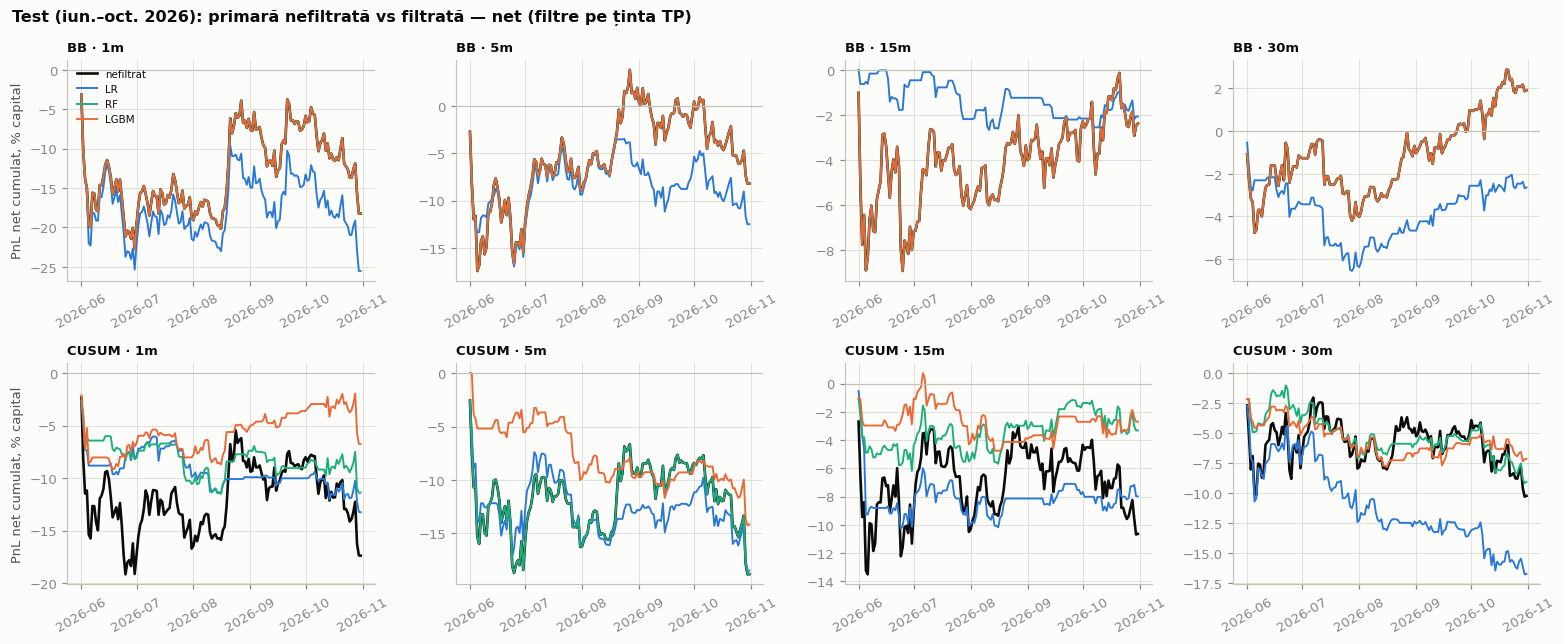

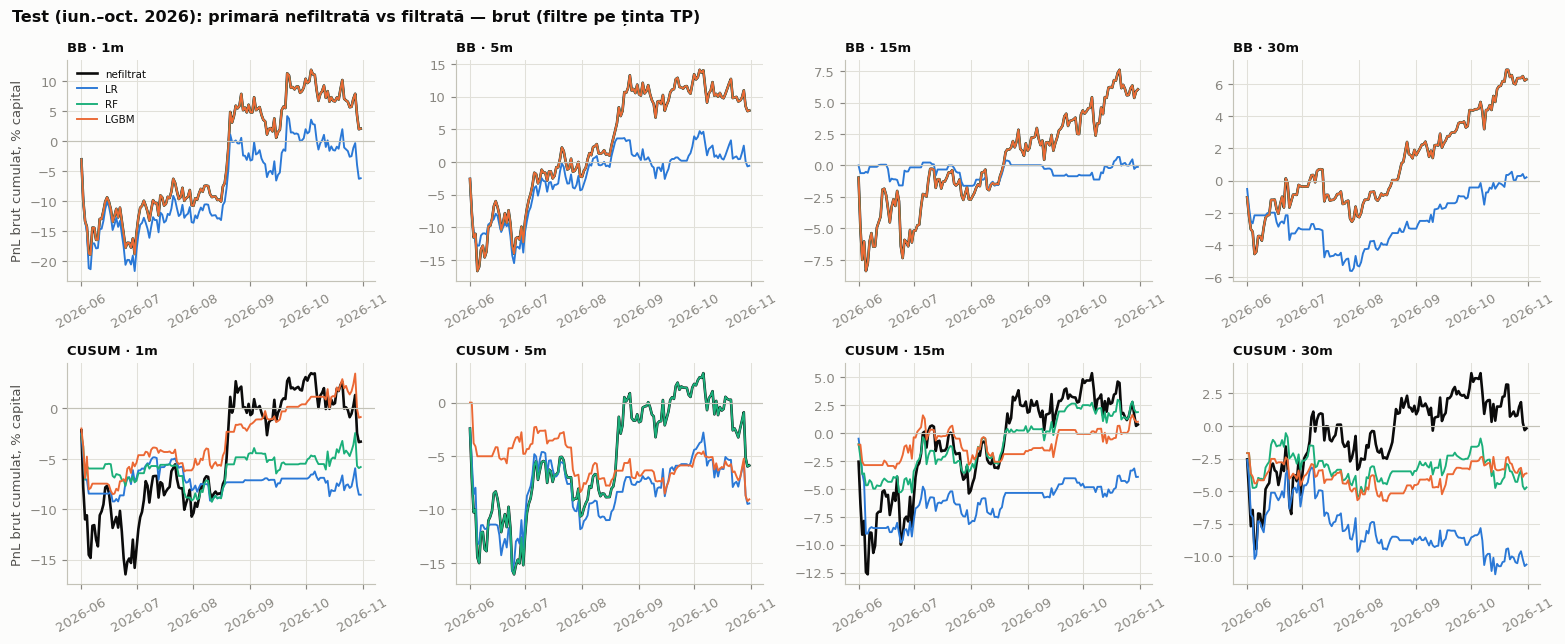

In [26]:
def filter_curves(target_label):
    for kind, idx in [("net", 1), ("brut", 0)]:
        fig, axes = plt.subplots(2, 4, figsize=(15, 6.2))
        for i, p in enumerate(PRIMS):
            for j, R in enumerate(RES):
                ax = axes[i, j]
                g0, n0 = FILT_CURVES[(p, R, "nefiltrat")]
                ax.plot(100 * (n0 if idx else g0).cumsum(), color=INK, lw=1.8, label="nefiltrat")
                for m in MODELS:
                    g, n, rnd = FILT_CURVES[(p, R, m)]
                    ax.plot(100 * (n if idx else g).cumsum(), color=MODEL_COLORS[m], lw=1.3, label=m)
                ax.axhline(0, color=AXIS, lw=0.8); ax.set_title(f"{p} · {R}m", fontsize=9); ax.tick_params(axis="x", rotation=30)
                if j == 0: ax.set_ylabel(f"PnL {kind} cumulat, % capital")
        axes[0, 0].legend(fontsize=7)
        fig.suptitle(f"Test (iun.–oct. 2026): primară nefiltrată vs filtrată — {kind} ({target_label})", x=0.01, ha="left", fontsize=11, fontweight="semibold")
        fig.tight_layout(); plt.show()
filter_curves("filtre pe ținta TP")

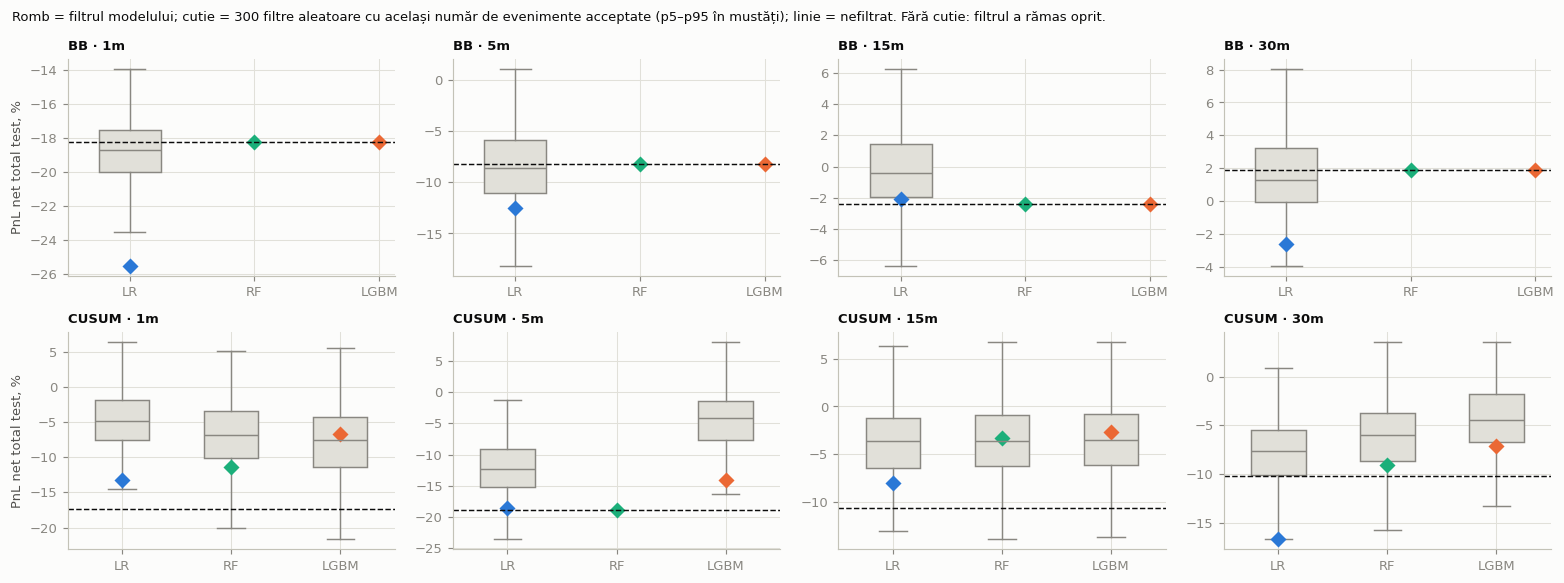

In [27]:
# Distribuția filtrelor aleatoare vs model: PnL net total pe test
fig, axes = plt.subplots(2, 4, figsize=(15, 5.6))
for i, p in enumerate(PRIMS):
    for j, R in enumerate(RES):
        ax = axes[i, j]
        for k, m in enumerate(MODELS):
            g, n, rnd = FILT_CURVES[(p, R, m)]
            if np.isfinite(rnd).all() and FILT[(p, R, m)]["păstrat (val)"] < 1:
                ax.boxplot(100 * rnd[:, 2], positions=[k], widths=0.5, showfliers=False, patch_artist=True,
                           boxprops=dict(facecolor=GRID, color=MUTED), medianprops=dict(color=MUTED), whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
            ax.plot(k, 100 * n.sum(), "D", color=MODEL_COLORS[m], ms=7)
        ax.axhline(100 * FILT_CURVES[(p, R, "nefiltrat")][1].sum(), color=INK, lw=1, ls="--")
        ax.set_xticks(range(3), MODELS); ax.set_title(f"{p} · {R}m", fontsize=9)
        if j == 0: ax.set_ylabel("PnL net total test, %")
fig.suptitle("Romb = filtrul modelului; cutie = 300 filtre aleatoare cu același număr de evenimente acceptate (p5–p95 în mustăți); linie = nefiltrat. Fără cutie: filtrul a rămas oprit.",
             x=0.01, ha="left", fontsize=9)
fig.tight_layout(); plt.show()

In [28]:
# Rezultate lunare pe test (PnL net, % capital) pentru nefiltrat și cele trei filtre
rows = {}
for p in PRIMS:
    for R in RES:
        for f in ["nefiltrat"] + MODELS:
            n = FILT_CURVES[(p, R, f)][1]
            rows[(p, f"{R}m", f)] = 100 * n.groupby(n.index.to_period("M")).sum()
MONF = pd.DataFrame(rows).T
MONF.columns = [str(c) for c in MONF.columns]
MONF = MONF.loc[:, [c for c in MONF.columns if c >= "2026-06"]]
display(MONF.round(2))

2026-06  2026-07  2026-08  2026-09  2026-10
BB    1m  nefiltrat   -22.75     3.89    12.65    -0.92   -11.11
          LR          -25.35     3.89     7.86       -1   -10.91
          RF          -22.75     3.89    12.65    -0.92   -11.11
          LGBM        -22.75     3.89    12.65    -0.92   -11.11
      5m  nefiltrat   -15.49     6.75    10.67     -2.9    -7.22
          LR          -15.98     6.58     3.43    -0.86    -5.67
          RF          -15.49     6.75    10.67     -2.9    -7.22
          LGBM        -15.49     6.75    10.67     -2.9    -7.22
      15m nefiltrat    -7.99     1.91     2.73     0.75     0.22
          LR           -0.46    -1.72     0.95    -0.92     0.09
          RF           -7.99     1.91     2.73     0.75     0.22
          LGBM         -7.99     1.91     2.73     0.75     0.22
      30m nefiltrat    -1.23    -2.72     3.25     1.67     0.94
          LR           -3.39    -2.92     1.65      2.1    -0.08
          RF           -1.23    -2.72     3.25     1.67     0.94
          LGBM         -1.23    -2.72     3.25     1.67     0.94
CUSUM 1m  nefiltrat   -19.13     2.42     8.55    -0.15    -9.07
          LR           -8.18     -1.7    -0.04     -0.1    -3.24
          RF            -8.2    -2.35     3.14    -1.59    -2.37
          LGBM         -6.98    -1.04     2.73     1.69    -3.14
      5m  nefiltrat   -18.41     2.14     7.44     0.17   -10.14
          LR          -15.65    -0.33     3.19     1.13    -6.82
          RF          -18.41     2.14     7.44     0.17   -10.14
          LGBM         -5.51    -4.49     0.75    -0.19    -4.72
      15m nefiltrat   -11.33     0.83     6.32    -1.07    -5.39
          LR          -10.13     0.08     1.92      0.3    -0.15
          RF           -6.19     0.66      2.9     0.92    -1.62
          LGBM         -2.88    -1.43     0.45     1.15     0.01
      30m nefiltrat    -7.91    -0.03     3.38    -0.44    -5.22
          LR           -7.61    -4.78     0.05    -0.99    -3.38
          RF           -4.13    -2.96     1.21      0.5    -3.68
          LGBM         -5.15    -1.77     0.26     0.68    -1.15

### 7.3 Ce selectează filtrele? Compoziția evenimentelor acceptate vs respinse (test)

Dacă un model mărește P(TP) doar alegând momente mai volatile, crește și P(SL), iar randamentul pe tranzacție nu se îmbunătățește (cu bariere [1, 2], un SL costă cât două TP). Tabelul compară rezultatele tranzacțiilor acceptate și respinse de fiecare filtru activ.

In [29]:
rows = {}
for p in PRIMS:
    for R in RES:
        D = DS[(p, R)]; Ev, Et = D[D["seg"] == "val"], D[D["seg"] == "test"]
        for m in MODELS:
            if FILT[(p, R, m)]["păstrat (val)"] >= 1:
                continue
            pt = BASE[("y_tp", p, R, m)]["preds"][((p, R), "test")].astype(float)
            acc = pt >= FILT[(p, R, m)]["prag p"]
            for name, k in [("acceptate", acc), ("respinse", ~acc)]:
                S = Et[k]
                rows[(p, f"{R}m", m, name)] = {"n": len(S), "TP %": 100 * (S["outcome"] == "TP").mean(), "SL %": 100 * (S["outcome"] == "SL").mean(),
                                               "timeout %": 100 * S["outcome"].str.startswith("timeout").mean(),
                                               "P(TP | atins) %": 100 * (S["outcome"] == "TP").sum() / max(1, S["touch"].sum()),
                                               "brut mediu (bps)": S["gross_bps"].mean(), "σ zilnic med (bps)": S["tp_bps"].median(),
                                               "vol 1h / σ zilnic (med)": np.nanmedian(np.exp(S["log_vol_1h"]) * np.sqrt(24) / S["trgt"])}
COMP = pd.DataFrame(rows).T
COMP.index.names = ["primară", "rezoluție", "filtru", "grup"]
display(COMP.astype(float).round(2))

n  TP %  SL %  timeout %  P(TP | atins) %  brut mediu (bps)  σ zilnic med (bps)  vol 1h / σ zilnic (med)
primară rezoluție filtru grup                                                                                                                  
BB      1m        LR     acceptate 5,154 31.32 11.18      57.51             73.7             -4.63               154.4                     0.78
                         respinse  1,298 17.03   4.7      78.27            78.37             12.42               237.3                     0.58
        5m        LR     acceptate   779 33.76 11.42      54.81            74.72             -5.35               150.3                     0.83
                         respinse    553 23.51  5.97      70.52            79.75             10.59               210.8                     0.63
        15m       LR     acceptate    90 37.78 11.11      51.11            77.27             -0.11               133.8                     0.88
                         respinse    309 32.04  9.71      58.25            76.74              11.6               171.3                     0.83
        30m       LR     acceptate   127  31.5 11.81      56.69            72.73              0.81               148.7                     1.03
                         respinse     71 38.03  8.45      53.52            81.82             45.51               185.5                     0.92
CUSUM   1m        LR     acceptate   275 38.18 14.91      46.91            71.92             -2.91               131.2                     1.17
                         respinse  1,074 37.06 12.57      50.37            74.67              4.67               167.8                     1.33
                  RF     acceptate   347 39.48 15.85      44.67            71.35             -5.49               126.2                     1.21
                         respinse  1,002 36.53 12.08       51.4            75.15              6.11               171.3                     1.33
                  LGBM   acceptate   379 37.73 15.83      46.44            70.44             -7.42               134.7                     1.26
                         respinse    970 37.11 11.96      50.93            75.63              7.24               168.8                     1.31
        5m        LR     acceptate   544 36.76 14.34       48.9            71.94             -5.46               151.4                     1.11
                         respinse    402 33.58 10.45      55.97            76.27              5.69               199.8                     1.32
                  LGBM   acceptate   261 33.72 15.71      50.57            68.22            -18.36               140.6                        1
                         respinse    685 36.06 11.53      52.41            75.77                 6               173.6                     1.25
        15m       LR     acceptate   183 38.25 14.21      47.54            72.92            -10.61                 147                     1.04
                         respinse    479 35.49 12.32      52.19            74.24              3.36               174.3                     1.12
                  RF     acceptate   241 37.34 11.62      51.04            76.27              3.07                 146                     0.96
                         respinse    421 35.63 13.54      50.83            72.46             -2.54               183.7                     1.23
                  LGBM   acceptate   171 39.18  11.7      49.12            77.01              2.84               141.7                        1
                         respinse    491 35.23 13.24      51.53            72.69             -1.67               176.4                     1.16
        30m       LR     acceptate   289 31.83 15.22      52.94            67.65            -21.36               149.9                     1.02
                         respinse    224 37.05 10.27      52.68             78.3             17.93               183.9                     1.18
       

**Interpretare (filtrare).**
* Criteriul de pe validation a pornit 15 din 24 de filtre (toate la CUSUM, cu excepția RF 5m; la BB doar LR). Pe test, **randamentul net pe eveniment scade față de primara nefiltrată în 12 din cele 15 filtre active**. Singurele creșteri (CUSUM 15m RF/LGBM, +3,5 / +3,2 bps) sunt la percentila ~60 a filtrelor aleatoare de aceeași mărime, deci nu se disting de o selecție la întâmplare. Filtrele LR pentru BB sunt la percentilele 0–23: **selectează mai prost decât întâmplarea**.
* **Mecanismul (tabelul 7.3).** Evenimentele acceptate au un σ zilnic mai mic (BB 1m: 154 vs 237 bps) și o volatilitate curentă mare relativ la σ zilnic. Barierele sunt deci înguste față de mișcarea actuală. Ambele bariere devin mai probabile: TP% crește, dar și SL% crește. P(TP | atins) chiar scade (73,7% vs 78,4%), iar randamentul brut se înrăutățește. Cu bariere [1, 2], un SL anulează două TP.
* Unele curbe nete arată mai bine după filtrare (de exemplu CUSUM 1m LGBM: −6,7% față de −17,4%). Motivul principal este tranzacționarea mai rară (expunere 24% vs 63%) a unei strategii care pierde, iar filtrul aleator de aceeași mărime ajunge în același loc (percentila 58).

**Concluzie:** cu ținta „TP atins primul”, informația din model (AUC 0,55–0,59 la BB 1m/5m) **nu** se traduce în selecția unor tranzacții mai bune. Este un caz concret în care există informație predictivă, dar filtrul nu ajută.

## 8. Importanța features între rezoluții: aparentă vs verificabilă out-of-sample

Folosim patru măsuri, de la cea mai puțin la cea mai mult verificabilă:

1. **Importanță internă (aparentă, pe train):** MDI la Random Forest, gain la LightGBM și |coeficient standardizat| la LR. Descrie ce a folosit modelul pentru a se potrivi pe train, nu ce prezice. MDI favorizează și variabilele continue cu multe valori unice.
2. **Permutare pe grup (out-of-sample):** pe validation și separat pe test, permutăm **împreună** toate coloanele unei familii (aceeași permutare a rândurilor). Astfel păstrăm corelațiile din interiorul familiei și evităm ca un feature permutat să fie înlocuit de un alt feature redundant din aceeași familie. Măsura este creșterea log loss-ului pe eveniment, în milinați (mnat = 0,001 nat). Eroarea standard este grupată pe zile.
3. **Permutare pe feature individual (OOS):** utilă pentru a vedea predictorii dominanți, dar subestimează features care au substitute corelate.
4. **Leave-one-family-out (LOFO):** reantrenăm modelul pe train fără o familie și măsurăm schimbarea log loss-ului pe validation/test. Acesta este singurul test care permite modelului să compenseze prin alte familii, deci măsoară contribuția **unică** a familiei.

Toate seturile de features sunt fixate dinainte. Rezultatele pe test sunt **descriptive**: nu le folosim pentru a alege features și a reraporta același test.

|ρ Spearman| mediu: în interiorul familiilor 0.30, între familii 0.18.
62 perechi din familii diferite au |ρ| > 0,6; cele mai puternice 12: range_log_1h~bb_width (+0.93), range_log_1h~drawdown_from_high_1h (-0.92), ret_trade_1h~drawdown_from_high_1h (+0.89), log_vol_1h~bb_width (+0.87), drawdown_from_high_1h~bb_width (-0.86), log_vol_1h~log_notional_1h (+0.85), range_log_1h~log_notional_1h (+0.84), log_notional_1h~bb_width (+0.84), log_vol_1h~drawdown_from_high_1h (-0.83), close_location_1h~bar_close_location (+0.82), ret_trade_1h~bb_width (-0.82), log_notional_1h~log1p_liq_notional_1h (+0.82)


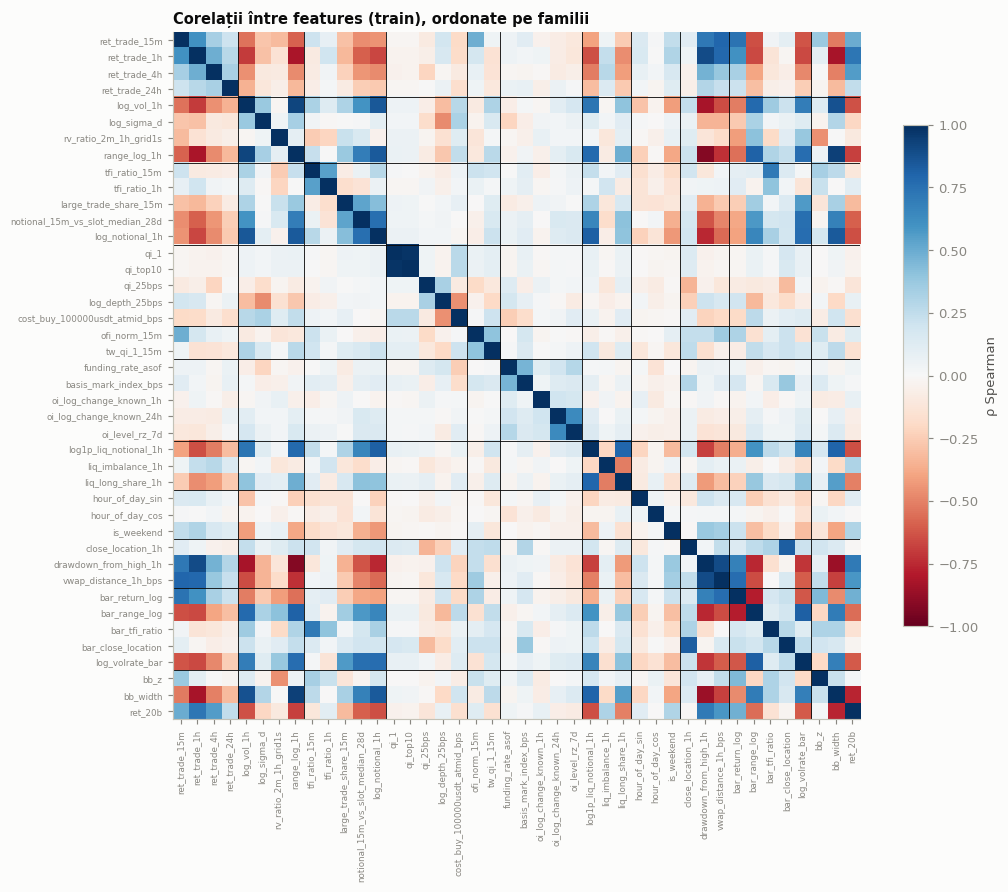

In [30]:
# 8.0 Structura de corelații (train, evenimente BB 5m + CUSUM 5m): justifică gruparea pe familii
Xc = pd.concat([DS[("BB", 5)], DS[("CUSUM", 5)]]).query("seg == 'train'")[FEATS]
RHO = Xc.rank().corr()
fam_arr = np.array([FAM_OF[f] for f in FEATS])
same = fam_arr[:, None] == fam_arr[None, :]
off = ~np.eye(len(FEATS), dtype=bool)
print(f"|ρ Spearman| mediu: în interiorul familiilor {np.abs(RHO.to_numpy())[same & off].mean():.2f}, între familii {np.abs(RHO.to_numpy())[~same].mean():.2f}.")
pairs = [(FEATS[i], FEATS[j], RHO.iat[i, j]) for i in range(len(FEATS)) for j in range(i + 1, len(FEATS)) if not same[i, j] and abs(RHO.iat[i, j]) > 0.6]
print(f"{len(pairs)} perechi din familii diferite au |ρ| > 0,6; cele mai puternice 12:", ", ".join(f"{a}~{b} ({r:+.2f})" for a, b, r in sorted(pairs, key=lambda z: -abs(z[2]))[:12]))
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(RHO.to_numpy(), cmap="RdBu", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATS)), FEATS, rotation=90, fontsize=6); ax.set_yticks(range(len(FEATS)), FEATS, fontsize=6); ax.grid(False)
b = np.flatnonzero(np.r_[True, fam_arr[1:] != fam_arr[:-1]])
for x in b[1:]:
    ax.axhline(x - 0.5, color=INK, lw=0.6); ax.axvline(x - 0.5, color=INK, lw=0.6)
fig.colorbar(im, ax=ax, shrink=0.7, label="ρ Spearman"); ax.set_title("Corelații între features (train), ordonate pe familii"); fig.tight_layout(); plt.show()

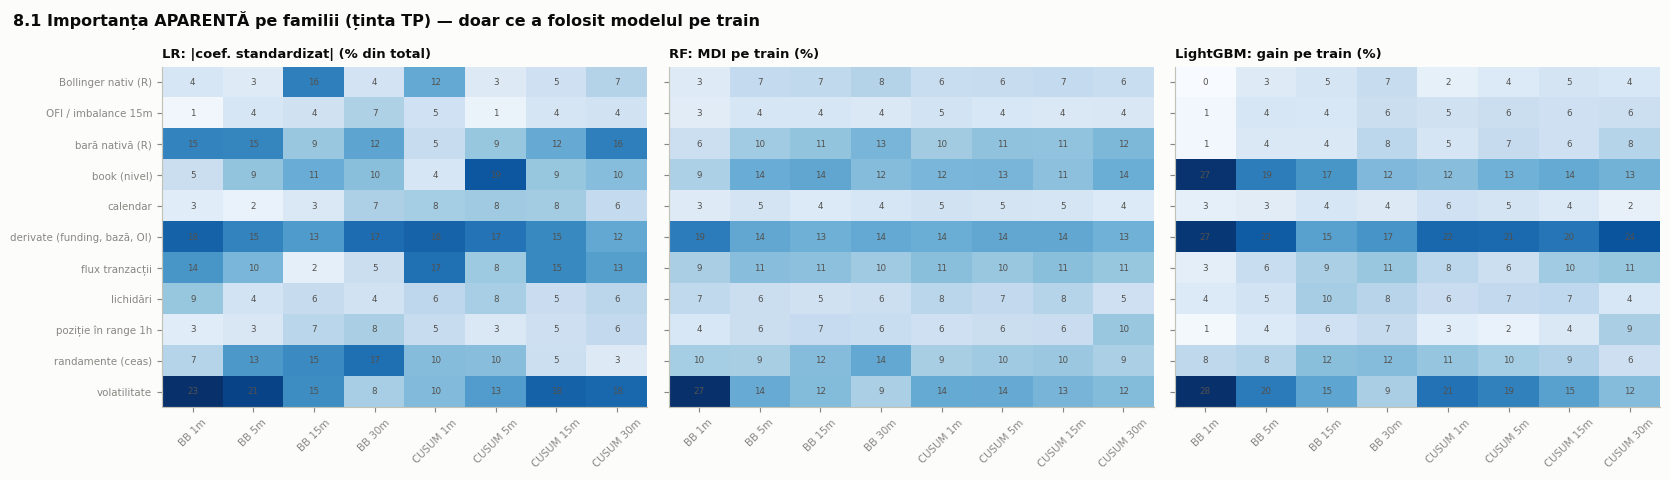

In [31]:
FAMS = list(FAMILIES)
CELLS = [(p, R) for p in PRIMS for R in RES]
def apparent_fam(target):
    out = {}
    for m in MODELS:
        A = pd.DataFrame({f"{p} {R}m": pd.Series(BASE[(target, p, R, m)]["imp"], index=FEATS).groupby(FAM_OF).sum() for p, R in CELLS})
        out[m] = 100 * A / A.sum()
    return out

def perm_fam(target, seg, model=None, split=None):
    """Media ΔLL (mnat/eveniment) pe familie și SE grupat pe zile; model=None → media celor 3 modele."""
    M, S = {}, {}
    for p, R in CELLS:
        D = DS[(p, R)]; E = D[D["seg"] == seg]; days = day_codes(E)
        k = np.ones(len(E), bool)
        if split is not None:
            mid = E["dec"].quantile(0.5); k = (E["dec"] <= mid).to_numpy() if split == 0 else (E["dec"] > mid).to_numpy()
        arr = np.mean([BASE[(target, p, R, mm)]["perm"][seg][0] for mm in (MODELS if model is None else [model])], axis=0)[k]
        ms, ss = [], []
        for j in range(len(FAMS)):
            mu, se = cluster_mean_se(arr[:, j], days[k]); ms.append(1e3 * mu); ss.append(1e3 * se)
        M[f"{p} {R}m"], S[f"{p} {R}m"] = ms, ss
    return pd.DataFrame(M, index=FAMS), pd.DataFrame(S, index=FAMS)

def heat(ax, A, title, fmt="{:.1f}", cmap="Blues", center=False, sig=None):
    v = np.nanmax(np.abs(A.to_numpy())) if center else np.nanmax(A.to_numpy())
    im = ax.imshow(A.to_numpy(), cmap=cmap, vmin=-v if center else 0, vmax=v, aspect="auto")
    ax.set_yticks(range(len(A)), A.index, fontsize=7); ax.set_xticks(range(A.shape[1]), A.columns, rotation=45, fontsize=7); ax.grid(False)
    for a in range(A.shape[0]):
        for c in range(A.shape[1]):
            t = fmt.format(A.iat[a, c]) + ("*" if sig is not None and sig.iat[a, c] else "")
            ax.text(c, a, t, ha="center", va="center", fontsize=6, color=INK2)
    ax.set_title(title, fontsize=9)
    return im

APP_TP = apparent_fam("y_tp")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for ax, m in zip(axes, MODELS):
    heat(ax, APP_TP[m], {"LR": "LR: |coef. standardizat| (% din total)", "RF": "RF: MDI pe train (%)", "LGBM": "LightGBM: gain pe train (%)"}[m], fmt="{:.0f}")
fig.suptitle("8.1 Importanța APARENTĂ pe familii (ținta TP) — doar ce a folosit modelul pe train", x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout(); plt.show()

### 8.2 Permutare pe familii, out-of-sample (ținta TP)

Valorile sunt creșterea log loss-ului (mnat pe eveniment) când familia este permutată, ca medie pe cele trei modele. * = media depășește 2 SE (grupat pe zile). O valoare negativă înseamnă că modelul **prezice mai bine fără** informația familiei: familia a fost învățată pe train, dar relația nu s-a păstrat.

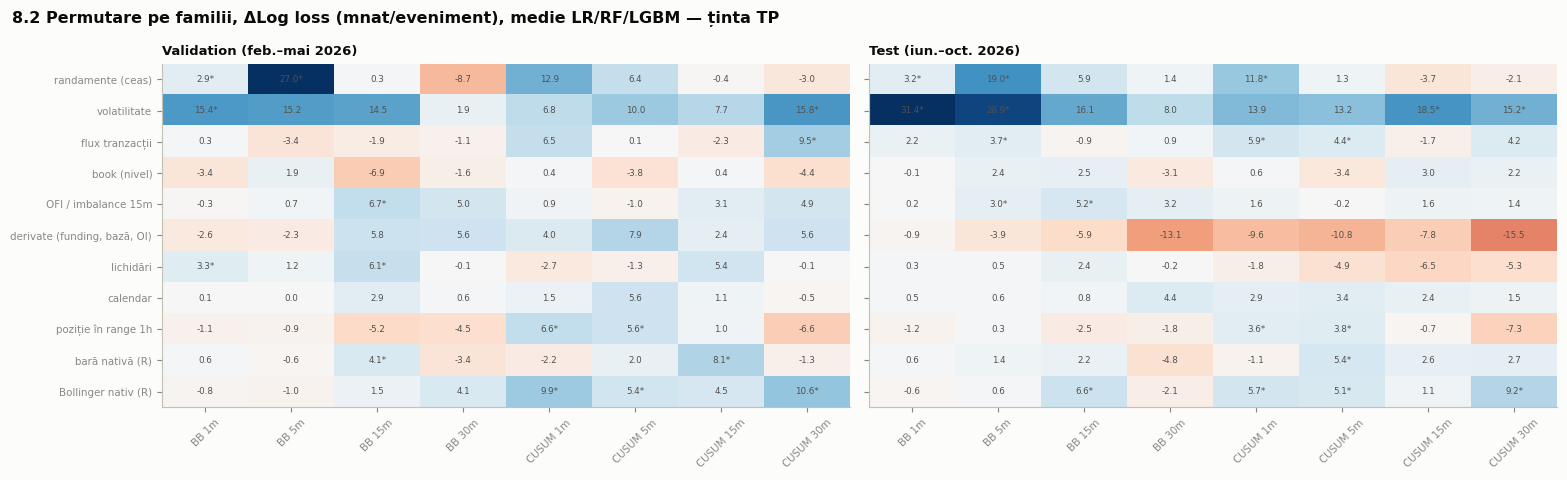

,"ρ(val, test) între familii",familia #1 pe validation,familia #1 pe test,familii semnificative val,familii semnificative test
BB 1m,0.8364,volatilitate,volatilitate,3,2
BB 5m,0.5273,randamente (ceas),volatilitate,1,4
BB 15m,0.2909,volatilitate,volatilitate,3,2
BB 30m,0.05455,"derivate (funding, bază, OI)",volatilitate,0,0
CUSUM 1m,0.8,randamente (ceas),volatilitate,2,4
CUSUM 5m,0.3,volatilitate,volatilitate,2,4
CUSUM 15m,0.3091,bară nativă (R),volatilitate,1,1
CUSUM 30m,0.5182,volatilitate,volatilitate,3,2


In [32]:
PV, PVs = perm_fam("y_tp", "val"); PT, PTs = perm_fam("y_tp", "test")
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
heat(axes[0], PV, "Validation (feb.–mai 2026)", center=True, cmap="RdBu", sig=PV > 2 * PVs)
heat(axes[1], PT, "Test (iun.–oct. 2026)", center=True, cmap="RdBu", sig=PT > 2 * PTs)
fig.suptitle("8.2 Permutare pe familii, ΔLog loss (mnat/eveniment), medie LR/RF/LGBM — ținta TP", x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout(); plt.show()
stab = pd.DataFrame({c: {"ρ(val, test) între familii": pd.Series(PV[c]).corr(pd.Series(PT[c]), method="spearman"),
                         "familia #1 pe validation": PV[c].idxmax(), "familia #1 pe test": PT[c].idxmax(),
                         "familii semnificative val": int((PV[c] > 2 * PVs[c]).sum()), "familii semnificative test": int((PT[c] > 2 * PTs[c]).sum())} for c in PV.columns}).T
display(stab)

LOFO (2 ținte × 8 celule × 3 modele × 11 familii): 528 modele antrenate în 29 s


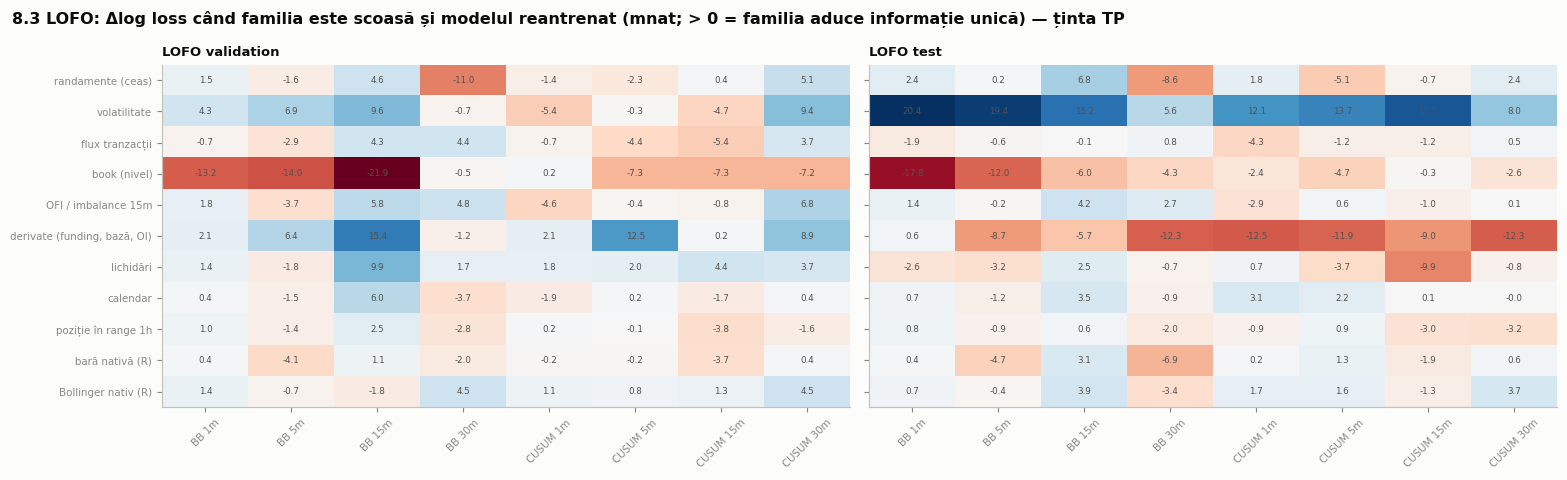

In [33]:
# 8.3 LOFO: reantrenare fără fiecare familie
def lofo_tasks(target):
    return [{"id": ("lofo", target, p, R, m, fam), "ds": (p, R), "target": target, "model": m, "seed": seed_of(p, R, m),
             "feats": [f for f in FEATS if FAM_OF[f] != fam]} for p in PRIMS for R in RES for m in MODELS for fam in FAMS]
LOFO = cached("lofo", lambda: run_tasks(lofo_tasks("y_tp") + lofo_tasks("touch"), "LOFO (2 ținte × 8 celule × 3 modele × 11 familii)"))
def lofo_table(target, seg, model=None):
    out = {}
    for p, R in CELLS:
        D = DS[(p, R)]; E = D[D["seg"] == seg]; y = E[target].to_numpy(int)
        vals = []
        for fam in FAMS:
            d = [ll_vec(y, LOFO[("lofo", target, p, R, mm, fam)]["preds"][((p, R), seg)].astype(float)).mean()
                 - ll_vec(y, BASE[(target, p, R, mm)]["preds"][((p, R), seg)].astype(float)).mean() for mm in (MODELS if model is None else [model])]
            vals.append(1e3 * np.mean(d))
        out[f"{p} {R}m"] = vals
    return pd.DataFrame(out, index=FAMS)
LV, LT = lofo_table("y_tp", "val"), lofo_table("y_tp", "test")
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
heat(axes[0], LV, "LOFO validation", center=True, cmap="RdBu"); heat(axes[1], LT, "LOFO test", center=True, cmap="RdBu")
fig.suptitle("8.3 LOFO: Δlog loss când familia este scoasă și modelul reantrenat (mnat; > 0 = familia aduce informație unică) — ținta TP",
             x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout(); plt.show()

### 8.4 Predictori dominanți pe rezoluție: aparent vs verificabil

Pentru fiecare celulă: cei mai importanți 5 features individuali după gain LightGBM (aparent, train) și după permutarea individuală OOS (validation + test, media celor 3 modele).

In [34]:
def top_feats(target):
    rows = {}
    for p, R in CELLS:
        gain = pd.Series(BASE[(target, p, R, "LGBM")]["imp"], index=FEATS)
        ft = []
        for seg in ("val", "test"):
            ft.append(np.mean([BASE[(target, p, R, mm)]["perm"][seg][1].mean(0) for mm in MODELS], axis=0))
        oos = pd.Series(1e3 * (ft[0] + ft[1]) / 2, index=FEATS)
        rows[f"{p} {R}m"] = {"top 5 aparent (gain LGBM)": ", ".join(gain.nlargest(5).index),
                             "top 5 OOS (permutare, val+test)": ", ".join(f"{k} ({v:+.2f})" for k, v in oos.nlargest(5).items()),
                             "suprapunere": len(set(gain.nlargest(5).index) & set(oos.nlargest(5).index))}
    return pd.DataFrame(rows).T
with pd.option_context("display.max_colwidth", 200):
    display(top_feats("y_tp"))

,top 5 aparent (gain LGBM),"top 5 OOS (permutare, val+test)",suprapunere
BB 1m,"log_sigma_d, cost_buy_100000usdt_atmid_bps, oi_level_rz_7d, ret_trade_24h, oi_log_change_known_24h","log_sigma_d (+22.04), log_vol_1h (+11.04), bar_return_log (+4.86), log1p_liq_notional_1h (+3.83), notional_15m_vs_slot_median_28d (+2.13)",1
BB 5m,"log_sigma_d, cost_buy_100000usdt_atmid_bps, oi_level_rz_7d, basis_mark_index_bps, oi_log_change_known_24h","log_sigma_d (+25.43), ret_trade_1h (+9.50), ret_trade_15m (+7.55), log_vol_1h (+5.27), oi_level_rz_7d (+2.92)",2
BB 15m,"log_sigma_d, liq_imbalance_1h, ret_trade_24h, cost_buy_100000usdt_atmid_bps, qi_top10","bb_width (+16.41), log_sigma_d (+12.07), ret_trade_1h (+10.32), bar_range_log (+3.60), ofi_norm_15m (+3.28)",1
BB 30m,"oi_level_rz_7d, ret_trade_4h, tw_qi_1_15m, large_trade_share_15m, oi_log_change_known_1h","ret_trade_1h (+6.73), oi_level_rz_7d (+6.70), log_sigma_d (+3.32), hour_of_day_cos (+3.02), is_weekend (+2.57)",1
CUSUM 1m,"log_sigma_d, ret_trade_24h, oi_log_change_known_24h, oi_level_rz_7d, funding_rate_asof","bb_width (+13.83), log_sigma_d (+10.41), ret_trade_1h (+7.63), log_notional_1h (+7.21), oi_level_rz_7d (+7.05)",2
CUSUM 5m,"log_sigma_d, oi_log_change_known_24h, oi_level_rz_7d, ret_trade_24h, cost_buy_100000usdt_atmid_bps","log_sigma_d (+11.47), log_volrate_bar (+8.92), qi_1 (+7.18), oi_level_rz_7d (+6.26), log_vol_1h (+5.01)",2
CUSUM 15m,"log_sigma_d, oi_log_change_known_24h, log_depth_25bps, oi_level_rz_7d, funding_rate_asof","log_sigma_d (+17.29), bb_width (+7.13), bar_close_location (+7.05), log_vol_1h (+6.36), oi_level_rz_7d (+2.86)",2
CUSUM 30m,"log_sigma_d, funding_rate_asof, vwap_distance_1h_bps, basis_mark_index_bps, oi_log_change_known_24h","ret_20b (+12.26), log_sigma_d (+10.36), tfi_ratio_15m (+8.72), bar_range_log (+7.63), bar_tfi_ratio (+6.60)",1


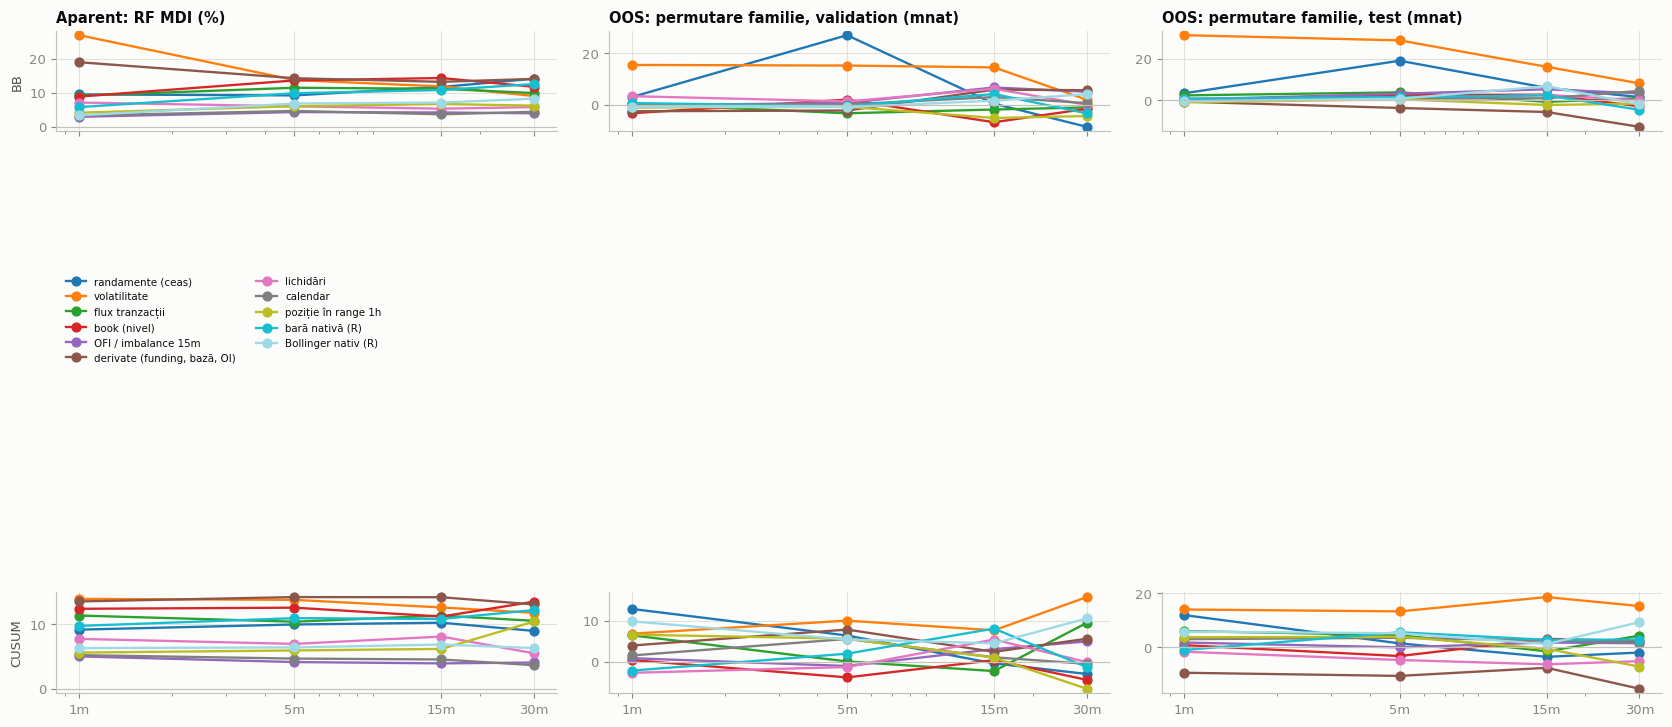

In [35]:
# 8.5 Comparație vizuală pe rezoluții: o familie = o linie (permutare OOS pe validation și pe test; aparent RF MDI)
fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex=True)
fam_cols = plt.cm.tab20(np.linspace(0, 1, len(FAMS)))
for i, p in enumerate(PRIMS):
    cols = [f"{p} {R}m" for R in RES]
    for k, fam in enumerate(FAMS):
        axes[i, 0].plot(RES, APP_TP["RF"].loc[fam, cols], "o-", color=fam_cols[k], label=fam)
        axes[i, 1].plot(RES, PV.loc[fam, cols], "o-", color=fam_cols[k])
        axes[i, 2].plot(RES, PT.loc[fam, cols], "o-", color=fam_cols[k])
    axes[i, 0].set_ylabel(f"{p}")
    for a in axes[i]:
        a.set_xscale("log"); a.set_xticks(RES, [f"{R}m" for R in RES]); a.axhline(0, color=AXIS, lw=0.8)
axes[0, 0].set_title("Aparent: RF MDI (%)"); axes[0, 1].set_title("OOS: permutare familie, validation (mnat)"); axes[0, 2].set_title("OOS: permutare familie, test (mnat)")
axes[0, 0].legend(fontsize=7, ncol=2, loc="upper left", bbox_to_anchor=(0, -1.35))
fig.tight_layout(); plt.show()

**Interpretare (importanța features).**
* **Volatilitatea este singura familie dominantă și verificabilă.** Pe test, este familia #1 la permutare în toate cele 8 celule, iar la LOFO pe test are contribuție unică pozitivă în toate cele 8 (5–20 mnat). Contribuția ei scade cu rezoluția la BB (~31 mnat la 1m, ~8 la 30m). Predictorii individuali sunt `log_sigma_d` (lățimea barierelor), `log_vol_1h` și `bb_width`, deci raportul dintre volatilitatea curentă și σ zilnic.
* **Importanța aparentă înșală.** Familia derivatelor (OI, funding, bază) primește 13–27% din gain/MDI/coeficienți, dar pe test permutarea ei **îmbunătățește** log loss-ul în 7 din 8 celule (−4…−16 mnat), iar LOFO pe test este negativ în 6 din 8. Este un regim învățat pe train care nu s-a păstrat (`oi_level_rz_7d`, nivelul funding-ului). Book-ul are 27% din gain la BB 1m, dar scoaterea lui îmbunătățește validation cu 13–22 mnat la BB 1m–15m. Acoperirea book-ului s-a degradat în mai 2026 (validation), iar nivelurile de cost/adâncime derivă în timp.
* **Ce se schimbă odată cu agregarea.** La 1m–5m contează aproape exclusiv features pe ferestre fixe de ceas (volatilitate, randamente 15m–1h). La 15m–30m câștigă teren familiile **native rezoluției** (bara curentă, indicatorii Bollinger pe 20 de bare), mai ales la CUSUM: familia Bollinger nativă este semnificativă la CUSUM 1m/5m/30m atât pe validation, cât și pe test. La BB, features Bollinger native sunt aproape inutile, pentru că toate evenimentele au prin construcție `bb_z < −2`.
* **BB vs CUSUM.** Familia dominantă este aceeași (volatilitatea); diferă doar familia secundară: randamentele pe ceas la BB 5m, respectiv poziția în range-ul de 1h și features Bollinger native la CUSUM.
* **Stabilitate.** Corelația de rang val–test a importanței familiilor este 0,84 (BB 1m) și 0,80 (CUSUM 1m), dar scade la 0,05–0,5 la rezoluțiile mari, unde sunt puține evenimente. Importanțele la 30m nu sunt reproductibile.

## 9. Ținta separată: atingerea oricărei bariere vs timeout

`touch = 1` dacă TP **sau** SL este atins înaintea expirării de 24 h, `touch = 0` la timeout. Aceleași trei modele, aceleași features, ponderi și perioade (antrenate deja în batch-ul din secțiunea 6). Această țintă măsoară predictibilitatea **mărimii** mișcării (volatilitate relativ la lățimea barierelor), nu a direcției.

n train     n  rată train (ponderată)  rată pozitivă   AUC  AUC validation  AUC IC95 jos  AUC IC95 sus  PR-AUC  log loss  skill log loss %  Brier  skill Brier %
primară rezoluție model                                                                                                                                                                  
BB      1m        LR       8,928 6,452                   0.491          0.383 0.681           0.598         0.606         0.744   0.515      0.65             5.639  0.229          7.667
                  RF       8,928 6,452                   0.491          0.383 0.619           0.581         0.541         0.685   0.471     0.669             3.003  0.238          4.111
                  LGBM     8,928 6,452                   0.491          0.383 0.623           0.623         0.534         0.704   0.474     0.695            -0.825   0.25         -0.731
        5m        LR       1,809 1,332                   0.483          0.387  0.66           0.592         0.598         0.726   0.532     0.659             3.898  0.233          5.289
                  RF       1,809 1,332                   0.483          0.387 0.612           0.584         0.544         0.674   0.496     0.661             3.582  0.235          4.843
                  LGBM     1,809 1,332                   0.483          0.387  0.63           0.643         0.563         0.695   0.512     0.678             1.117  0.242          1.692
        15m       LR         622   399                   0.482          0.434 0.619           0.593         0.544         0.688   0.576     0.673             2.304  0.239          3.497
                  RF         622   399                   0.482          0.434 0.607           0.561          0.55         0.662   0.558     0.675             1.991  0.241          2.733
                  LGBM       622   399                   0.482          0.434  0.62           0.585         0.563         0.681   0.575     0.693             -0.51   0.25         -0.653
        30m       LR         294   198                   0.481          0.444 0.567           0.539         0.491         0.649   0.499     0.717            -3.906   0.26         -4.608
                  RF         294   198                   0.481          0.444 0.538           0.587          0.46         0.609   0.493     0.689             0.121  0.248          0.157
                  LGBM       294   198                   0.481          0.444 0.533           0.578         0.449         0.616   0.499     0.708             -2.73  0.257         -3.648
CUSUM   1m        LR       1,228 1,349                   0.509          0.503 0.632           0.513         0.577         0.689   0.618     0.692             0.216  0.246          1.442
                  RF       1,228 1,349                   0.509          0.503 0.592           0.568         0.531         0.652    0.57     0.683             1.536  0.245          2.122
                  LGBM     1,228 1,349                   0.509          0.503 0.588            0.53          0.52         0.652   0.572     0.693             -0.01  0.249           0.48
        5m        LR         877   946                   0.505          0.481 0.605           0.558          0.54         0.676   0.554     0.699             -0.79   0.25          0.082
                  RF         877   946                   0.505          0.481 0.549           0.586         0.491         0.613   0.522      0.69             0.505  0.248          0.702
                  LGBM       877   946                   0.505          0.481 0.568           0.605         0.502         0.642   0.541     0.703            -1.417  0.254         -1.452
        15m       LR         642   662                   0.483          0.491 0.616           0.534          0.54         0.695   0.602     0.684             1.375  0.244          2.204
                  RF         642   662                   0.483          0.491 0.547           0.557         0.483      

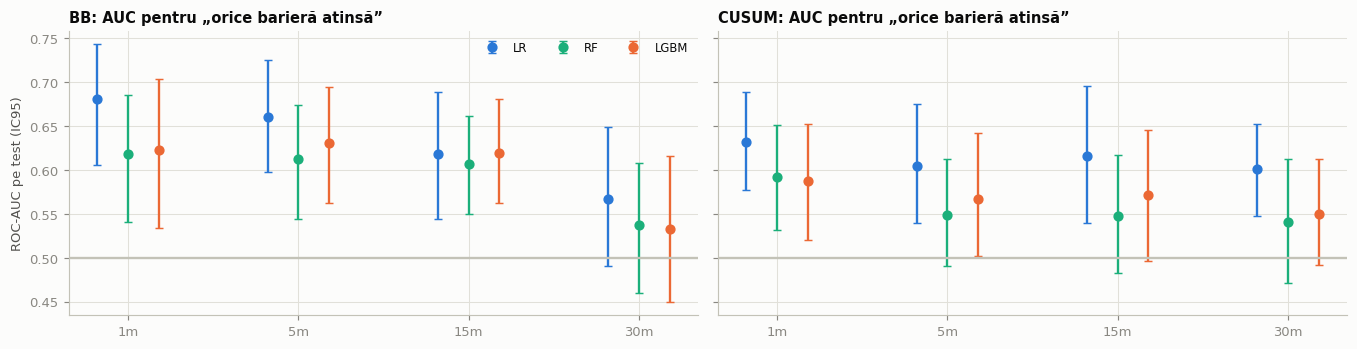

**Classification report și matrice de confuzie (test, prag = rata pozitivă din train)**

prag  precizie 0  recall 0  F1 0  suport 0  precizie 1  recall 1  F1 1  suport 1  acuratețe  F1 macro    TN    FP    FN    TP
primară rezoluție model                                                                                                                               
BB      1m        LR    0.491       0.761     0.572 0.653     3,980       0.508     0.711 0.593     2,472      0.625     0.623 2,276 1,704   714 1,758
                  RF    0.491       0.675     0.637 0.656     3,980       0.464     0.505 0.484     2,472      0.587      0.57 2,537 1,443 1,223 1,249
                  LGBM  0.491        0.74     0.428 0.542     3,980       0.451     0.757 0.566     2,472      0.554     0.554 1,704 2,276   600 1,872
        5m        LR    0.483       0.721     0.541 0.618       817       0.478     0.668 0.558       515       0.59     0.588   442   375   171   344
                  RF    0.483       0.673     0.657 0.665       817       0.476     0.493 0.484       515      0.594     0.575   537   280   261   254
                  LGBM  0.483       0.705     0.482 0.573       817       0.453      0.68 0.543       515      0.559     0.558   394   423   165   350
        15m       LR    0.482       0.639     0.571 0.603       226       0.508     0.578 0.541       173      0.574     0.572   129    97    73   100
                  RF    0.482       0.643     0.527 0.579       226         0.5     0.618 0.553       173      0.566     0.566   119   107    66   107
                  LGBM  0.482       0.667     0.319 0.431       226       0.471     0.792 0.591       173      0.524     0.511    72   154    36   137
        30m       LR    0.481       0.622     0.418   0.5       110       0.484     0.682 0.566        88      0.535     0.533    46    64    28    60
                  RF    0.481       0.549     0.455 0.498       110       0.439     0.534 0.482        88       0.49      0.49    50    60    41    47
                  LGBM  0.481       0.577     0.409 0.479       110       0.458     0.625 0.529        88      0.505     0.504    45    65    33    55
CUSUM   1m        LR    0.509       0.642     0.407 0.499       670        0.57     0.776 0.658       679      0.593     0.578   273   397   152   527
                  RF    0.509       0.573      0.54 0.556       670        0.57     0.602 0.586       679      0.572     0.571   362   308   270   409
                  LGBM  0.509       0.568     0.476 0.518       670       0.554     0.642 0.595       679       0.56     0.556   319   351   243   436
        5m        LR    0.505         0.6     0.548 0.573       491       0.554     0.607 0.579       455      0.576     0.576   269   222   179   276
                  RF    0.505       0.552      0.56 0.556       491       0.518      0.51 0.514       455      0.536     0.535   275   216   223   232
                  LGBM  0.505       0.582     0.501 0.538       491       0.532     0.611 0.569       455      0.554     0.553   246   245   177   278
        15m       LR    0.483       0.612     0.496 0.548       337       0.563     0.674 0.613       325      0.583      0.58   167   170   106   219
                  RF    0.483       0.551     0.513 0.531       337       0.529     0.566 0.547       325      0.539     0.539   173   164   141   184
                  LGBM  0.483       0.562     0.576 0.569       337       0.549     0.535 0.542       325      0.556     0.555   194   143   151   174
        30m       LR    0.497         0.6     0.542  0.57       271       0.537     0.595 0.565       242      0.567     0.567   147   124    98   144
                  RF    0.497       0.539     0.535 0.537       271       0.484     0.488 0.486       242      0.513     0.511   145   126   124   118
                  LGBM  0.497       0.549     0.557 0.553       271       0.496     0.488 0.492       242      0.524     0.522   151   120   124   118

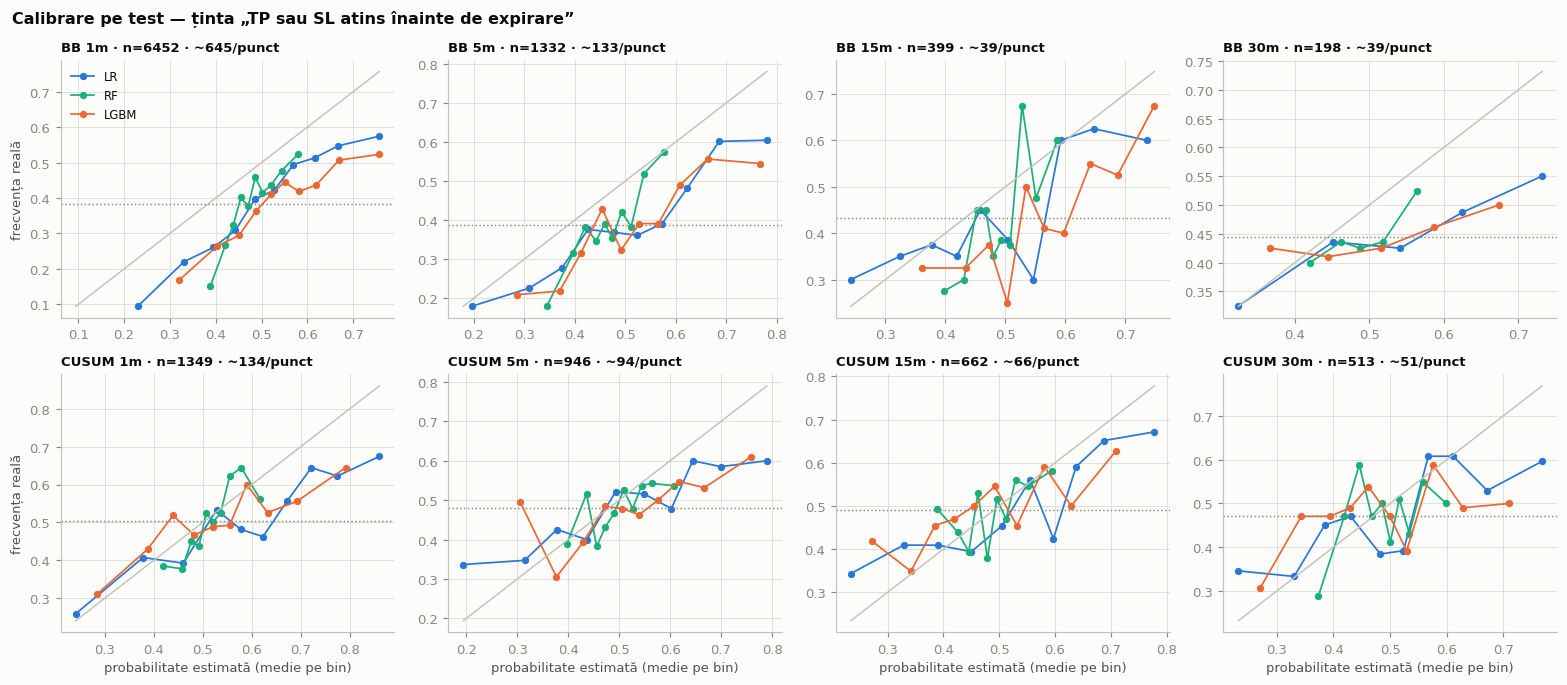

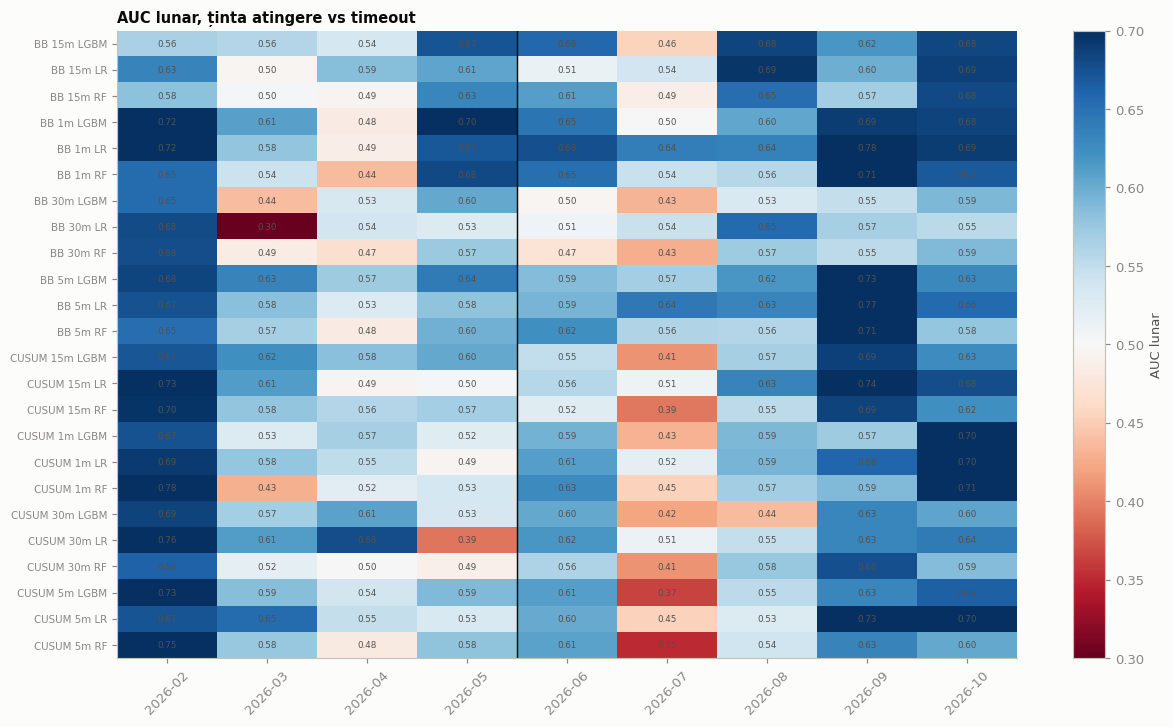

luni cu AUC > 0,5  luni evaluate  AUC lunar median  AUC lunar min  AUC lunar max
BB    1m  LR                    8              9             0.669          0.487          0.785
          RF                    8              9              0.65          0.436          0.707
          LGBM                  7              9             0.645          0.483           0.72
      5m  LR                    9              9             0.632          0.527          0.767
          RF                    8              9             0.577          0.483          0.715
          LGBM                  9              9              0.63          0.568          0.732
      15m LR                    8              9             0.597          0.496          0.695
          RF                    7              9             0.582          0.487          0.681
          LGBM                  8              9             0.616          0.455          0.683
      30m LR                    8              9             0.544          0.303          0.679
          RF                    5              9             0.552          0.427          0.677
          LGBM                  6              9             0.532          0.433          0.654
CUSUM 1m  LR                    8              9             0.593          0.494          0.703
          RF                    7              9              0.57          0.429          0.782
          LGBM                  8              9             0.572          0.431          0.702
      5m  LR                    8              9               0.6          0.454          0.728
          RF                    7              9             0.581          0.351          0.752
          LGBM                  8              9             0.588          0.365          0.734
      15m LR                    8              9             0.612          0.494          0.744
          RF                    8              9             0.568          0.394          0.696
          LGBM                  8              9             0.602           0.41          0.687
      30m LR                    8              9             0.616          0.393           0.76
          RF                    6              9             0.562          0.409          0.676
          LGBM                  7              9             0.602          0.421          0.686

In [36]:
M_TO_TEST, REP_TO_TEST = eval_table("touch", "test")
M_TO_VAL, _ = eval_table("touch", "val", ci=False)
T = M_TO_TEST[show].astype(float).copy(); T.insert(5, "AUC validation", M_TO_VAL["AUC"].astype(float))
display(T.round(3))
auc_panel(M_TO_TEST, "AUC pentru „orice barieră atinsă”")
display(Markdown("**Classification report și matrice de confuzie (test, prag = rata pozitivă din train)**"))
display(REP_TO_TEST.astype(float).round(3))
calib_grid("touch", "Calibrare pe test — ținta „TP sau SL atins înainte de expirare”")
MON_TO = monthly_metric("touch")
STAB_TO = monthly_heat(MON_TO, "AUC lunar, ținta atingere vs timeout")
display(STAB_TO.round(3))

### 9.1 Volatilitate vs direcție: ce învață de fapt modelul pentru TP?

Evenimentul „TP atins primul” combină două lucruri: (a) se atinge o barieră și (b) bariera atinsă este cea de sus. Pentru fiecare model antrenat pe ținta TP, calculăm pe test:
* AUC pentru ținta TP (cea pe care a fost antrenat);
* AUC pentru „atingere” (dacă modelul TP prezice de fapt mărimea mișcării);
* **AUC pentru direcție condiționat de atingere**: TP vs SL, numai printre evenimentele care au atins o barieră;
* AUC pentru direcție printre timeout-uri (timeout+ vs timeout−);
* corelația Spearman dintre probabilitățile modelului TP și ale modelului de atingere.

Dacă AUC-ul pe direcție este ≈ 0,5 iar cel pe atingere este mare, modelul TP a învățat volatilitate, nu direcție.

In [37]:
def safe_auc(y, p):
    return roc_auc_score(y, p) if len(y) > 10 and 0 < np.mean(y) < 1 else np.nan
rows = {}
for p in PRIMS:
    for R in RES:
        E = DS[(p, R)]; E = E[E["seg"] == "test"]
        tch = E["touch"].to_numpy(int) == 1; to = ~tch
        for m in MODELS:
            ptp = BASE[("y_tp", p, R, m)]["preds"][((p, R), "test")].astype(float)
            pto = BASE[("touch", p, R, m)]["preds"][((p, R), "test")].astype(float)
            rows[(p, f"{R}m", m)] = {"AUC țintă TP": safe_auc(E["y_tp"].to_numpy(), ptp), "AUC modelului TP pe atingere": safe_auc(tch.astype(int), ptp),
                                     "AUC modelului TP: TP vs SL | atins": safe_auc((E["outcome"].to_numpy()[tch] == "TP").astype(int), ptp[tch]),
                                     "AUC modelului TP: timeout+ vs − ": safe_auc((E["outcome"].to_numpy()[to] == "timeout+").astype(int), ptp[to]),
                                     "AUC modelului de atingere (țintă proprie)": safe_auc(tch.astype(int), pto),
                                     "ρ(p_TP, p_atingere)": pd.Series(ptp).corr(pd.Series(pto), method="spearman"),
                                     "n atinse": int(tch.sum()), "P(TP | atins) %": 100 * (E["outcome"].to_numpy()[tch] == "TP").mean()}
DECOMP = pd.DataFrame(rows).T; DECOMP.index.names = ["primară", "rezoluție", "model"]
display(DECOMP.astype(float).round(3))
print("Media pe cele 24 de celule:", DECOMP.astype(float).mean().round(3).to_dict())

AUC țintă TP  AUC modelului TP pe atingere  AUC modelului TP: TP vs SL | atins  AUC modelului TP: timeout+ vs −   AUC modelului de atingere (țintă proprie)  ρ(p_TP, p_atingere)  n atinse  P(TP | atins) %
primară rezoluție model                                                                                                                                                                                                             
BB      1m        LR            0.582                         0.609                               0.465                             0.435                                      0.681                0.813     2,472            74.23
                  RF            0.574                         0.578                               0.522                             0.459                                      0.619                0.797     2,472            74.23
                  LGBM          0.554                         0.548                               0.538                             0.461                                      0.623                0.755     2,472            74.23
        5m        LR            0.588                         0.611                               0.477                             0.442                                       0.66                0.857       515            76.31
                  RF            0.572                         0.596                                0.47                             0.459                                      0.612                0.775       515            76.31
                  LGBM          0.562                         0.577                                0.49                             0.496                                       0.63                0.737       515            76.31
        15m       LR            0.572                         0.578                                0.52                             0.516                                      0.619                0.758       173            76.88
                  RF            0.547                         0.558                               0.494                             0.553                                      0.607                0.689       173            76.88
                  LGBM          0.545                         0.547                               0.513                             0.522                                       0.62                 0.68       173            76.88
        30m       LR            0.462                         0.473                               0.456                             0.393                                      0.567                0.545        88            76.14
                  RF            0.466                         0.473                               0.464                              0.39                                      0.538                0.261        88            76.14
                  LGBM          0.424                         0.439                                0.44                             0.408                                      0.533                0.317        88            76.14
CUSUM   1m        LR             0.53                         0.542                               0.492                             0.432                                      0.632                0.621       679            74.08
                  RF            0.494                         0.516                               0.459                             0.464                                      0.592                0.593       679            74.08
                  LGBM          0.527                         0.545                                0.48                             0.491                                      0.588                0.766       679            74.08
        5m        LR            0.513                         0.532                               0.468                             

Media pe cele 24 de celule: {'AUC țintă TP': 0.519, 'AUC modelului TP pe atingere': 0.531, 'AUC modelului TP: TP vs SL | atins': 0.48, 'AUC modelului TP: timeout+ vs − ': 0.473, 'AUC modelului de atingere (țintă proprie)': 0.594, 'ρ(p_TP, p_atingere)': 0.685, 'n atinse': 618.625, 'P(TP | atins) %': 74.678}


### 9.2 Importanța features: atingere vs TP

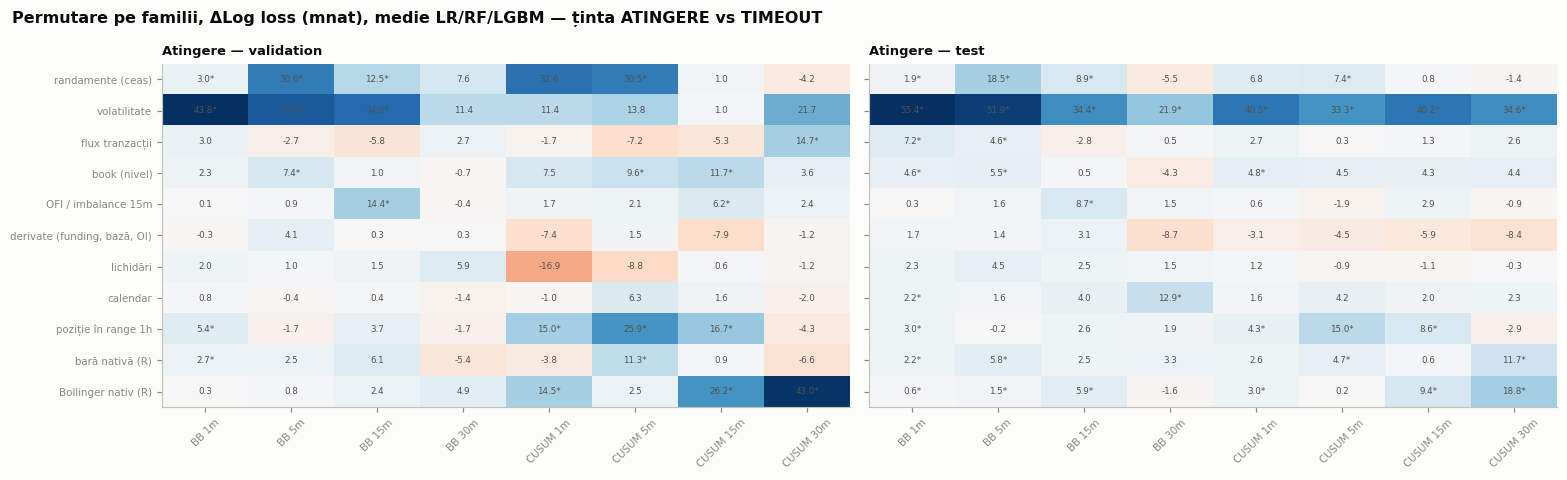

,"ρ(TP, atingere) permutare val","ρ(TP, atingere) permutare test",#1 TP (val+test),#1 atingere (val+test),"Σ permutare TP (val+test, mnat)","Σ permutare atingere (val+test, mnat)",LOFO volatilitate TP (val),LOFO volatilitate atingere (val)
BB 1m,0.4727,0.3727,volatilitate,volatilitate,60.89,144.3,4.285,14.93
BB 5m,0.7091,0.8364,randamente (ceas),volatilitate,101.6,177.7,6.865,8.673
BB 15m,0.4273,0.6,volatilitate,volatilitate,75.35,149.3,9.585,9.336
BB 30m,0.2091,0.5091,volatilitate,volatilitate,24.99,62.11,-0.7393,3.908
CUSUM 1m,0.7636,0.7545,randamente (ceas),volatilitate,91.47,144.3,-5.437,-22.31
CUSUM 5m,0.4818,0.6182,volatilitate,volatilitate,71.63,169.4,-0.2736,-11.14
CUSUM 15m,-0.08182,0.6455,volatilitate,volatilitate,54.31,134.1,-4.704,-19.67
CUSUM 30m,0.7545,0.9455,volatilitate,Bollinger nativ (R),73.13,150.4,9.365,3.588


,top 5 aparent (gain LGBM),"top 5 OOS (permutare, val+test)",suprapunere
BB 1m,"log_sigma_d, cost_buy_100000usdt_atmid_bps, oi_level_rz_7d, oi_log_change_known_24h, log_depth_25bps","log_sigma_d (+51.19), log_vol_1h (+12.31), drawdown_from_high_1h (+7.31), log_notional_1h (+7.06), bar_return_log (+4.17)",1
BB 5m,"log_sigma_d, oi_level_rz_7d, cost_buy_100000usdt_atmid_bps, oi_log_change_known_24h, basis_mark_index_bps","log_sigma_d (+49.95), log_vol_1h (+15.48), ret_trade_1h (+8.75), log_depth_25bps (+6.26), ret_trade_15m (+6.14)",1
BB 15m,"log_sigma_d, oi_level_rz_7d, cost_buy_100000usdt_atmid_bps, ofi_norm_15m, oi_log_change_known_1h","log_sigma_d (+28.20), vwap_distance_1h_bps (+12.50), bb_width (+10.87), ofi_norm_15m (+8.82), ret_trade_1h (+8.33)",2
BB 30m,"log_sigma_d, oi_level_rz_7d, oi_log_change_known_1h, liq_imbalance_1h, liq_long_share_1h","log_sigma_d (+15.76), log_vol_1h (+7.16), is_weekend (+6.23), ret_trade_1h (+5.18), vwap_distance_1h_bps (+2.89)",1
CUSUM 1m,"log_sigma_d, ret_trade_24h, funding_rate_asof, oi_level_rz_7d, cost_buy_100000usdt_atmid_bps","log_sigma_d (+21.17), log_vol_1h (+17.95), bb_width (+15.20), ret_trade_24h (+13.39), log_depth_25bps (+5.96)",2
CUSUM 5m,"log_sigma_d, oi_level_rz_7d, ret_trade_24h, funding_rate_asof, qi_25bps","log_sigma_d (+22.21), log_vol_1h (+14.16), ret_trade_24h (+13.91), log_depth_25bps (+13.37), bar_range_log (+9.29)",2
CUSUM 15m,"log_sigma_d, oi_level_rz_7d, log_depth_25bps, ret_trade_24h, funding_rate_asof","log_sigma_d (+27.57), bb_width (+13.59), log_vol_1h (+12.34), log_depth_25bps (+9.71), vwap_distance_1h_bps (+9.61)",2
CUSUM 30m,"log_sigma_d, funding_rate_asof, ret_20b, basis_mark_index_bps, oi_level_rz_7d","log_sigma_d (+26.22), ret_20b (+18.17), log_vol_1h (+13.72), bar_range_log (+8.23), tfi_ratio_15m (+7.54)",2


In [38]:
PVt, PVts = perm_fam("touch", "val"); PTt, PTts = perm_fam("touch", "test")
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
heat(axes[0], PVt, "Atingere — validation", center=True, cmap="RdBu", sig=PVt > 2 * PVts)
heat(axes[1], PTt, "Atingere — test", center=True, cmap="RdBu", sig=PTt > 2 * PTts)
fig.suptitle("Permutare pe familii, ΔLog loss (mnat), medie LR/RF/LGBM — ținta ATINGERE vs TIMEOUT", x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout(); plt.show()
LVt, LTt = lofo_table("touch", "val"), lofo_table("touch", "test")
cmp = pd.DataFrame({c: {"ρ(TP, atingere) permutare val": PV[c].corr(PVt[c], method="spearman"), "ρ(TP, atingere) permutare test": PT[c].corr(PTt[c], method="spearman"),
                        "#1 TP (val+test)": (PV[c] + PT[c]).idxmax(), "#1 atingere (val+test)": (PVt[c] + PTt[c]).idxmax(),
                        "Σ permutare TP (val+test, mnat)": (PV[c] + PT[c]).clip(lower=0).sum(), "Σ permutare atingere (val+test, mnat)": (PVt[c] + PTt[c]).clip(lower=0).sum(),
                        "LOFO volatilitate TP (val)": LV.loc["volatilitate", c], "LOFO volatilitate atingere (val)": LVt.loc["volatilitate", c]} for c in PV.columns}).T
display(cmp)
with pd.option_context("display.max_colwidth", 200):
    display(top_feats("touch"))

**Interpretare (atingere vs timeout).**
* Atingerea este **mai predictibilă** decât TP: AUC 0,59–0,68 la BB 1m–15m și 0,55–0,63 la CUSUM. IC-urile exclud 0,5 în majoritatea celulelor de 1m–15m (BB 1m LR: 0,68 [0,61–0,74]). Skill-ul de log loss este pozitiv pentru LR/RF în cele mai multe celule (până la +5,6%), deci și probabilitățile sunt utile, nu doar ordonarea.
* **Modelul de TP învață volatilitate, nu direcție.** În medie, AUC-ul modelelor TP este 0,53 pe atingere, dar **0,48 pentru direcție condiționat de atingere** (TP vs SL) și 0,47 printre timeout-uri. Corelația dintre p_TP și p_atingere este 0,69 în medie (0,81 la BB 1m LR). Cu TP la 1σ și SL la 2σ, o mișcare mare atinge întâi TP-ul, care e mai aproape, așa că „TP primul” moștenește predictibilitatea volatilității.
* Pentru atingere, volatilitatea domină și mai clar (22–55 mnat la permutare pe test). Ordinea importanței familiilor seamănă cu cea pentru TP (corelație de rang 0,37–0,95), încă un semn că cele două ținte folosesc aceeași informație.

## 10. Antrenare separată vs comună (în cadrul fiecărei rezoluții, ambele ținte)

Pentru fiecare rezoluție antrenăm modele pe:
* **P1**: numai evenimentele BB din train;
* **P2**: numai evenimentele CUSUM din train;
* **P1 ∪ P2**: reuniunea, **fără duplicate**. Un eveniment care apare în ambele primare (aceeași intrare) are aceeași etichetă și este păstrat o singură dată. Uniqueness este recalculată pe reuniune, pentru că suprapunerea etichetelor se schimbă;
* **P1 ∪ P2 redus la mărimea lui P1** și **redus la mărimea lui P2** (3 subeșantioane aleatoare, medie): reuniunea cu același număr de exemple ca primara evaluată. Dacă reuniunea completă e mai bună decât P-ul propriu, dar reuniunea redusă nu, avantajul vine din numărul de exemple. Dacă și reuniunea redusă egalează sau depășește P-ul propriu, informația se transferă între primare.

Evaluare pe testul P1, testul P2 și testul combinat (reuniunea testelor, fără duplicate). Nu există scurgeri temporale: toate seturile folosesc aceleași granițe și aceeași purjare. Modelul comun nu primește un indicator al primarei, deci trebuie să folosească informație comună.

In [39]:
def make_union(R):
    A, B_ = DS[("BB", R)].assign(in_bb=1, in_cs=0), DS[("CUSUM", R)].assign(in_bb=0, in_cs=1)
    U = pd.concat([A, B_], ignore_index=True)
    flags = U.groupby("entry_t")[["in_bb", "in_cs"]].max()
    U = U.drop_duplicates("entry_t", keep="first").drop(columns=["in_bb", "in_cs"]).join(flags, on="entry_t")
    U = U.sort_values("entry_t").reset_index(drop=True)
    e_ns = pd.to_datetime(U["entry_t"]).to_numpy().astype("datetime64[ns]").astype(np.int64)
    U["w"] = uniqueness_numba(e_ns, pd.to_datetime(U["t1"]).to_numpy().astype("datetime64[ns]").astype(np.int64), PATH_NS)
    return U
dup_rows = {}
for R in RES:
    DS[("UNION", R)] = make_union(R)
    U = DS[("UNION", R)]
    dup_rows[f"{R}m"] = {"BB": len(DS[("BB", R)]), "CUSUM": len(DS[("CUSUM", R)]), "reuniune fără duplicate": len(U), "în ambele": int(((U.in_bb == 1) & (U.in_cs == 1)).sum())}
display(pd.DataFrame(dup_rows).T)

def joint_tasks():
    T = []
    for R in RES:
        evals = [(("BB", R), "test"), (("CUSUM", R), "test"), (("UNION", R), "test")]
        ntr = {p: int((DS[(p, R)]["seg"] == "train").sum()) for p in PRIMS}
        for target in ("y_tp", "touch"):
            for m in MODELS:
                for name, ds, sub, rep in [("P1", ("BB", R), None, 0), ("P2", ("CUSUM", R), None, 0), ("P1∪P2", ("UNION", R), None, 0)] + \
                        [(f"P1∪P2 mărime P1", ("UNION", R), ntr["BB"], k) for k in range(3)] + [(f"P1∪P2 mărime P2", ("UNION", R), ntr["CUSUM"], k) for k in range(3)]:
                    T.append({"id": ("joint", R, target, m, name, rep), "ds": ds, "target": target, "model": m, "sub": sub,
                              "seed": seed_of(R, m, name, rep), "evals": evals})
    return T
JOINT = cached("joint", lambda: run_tasks(joint_tasks(), "Separat vs comun"))

rows = {}
for (_, R, target, m, name, rep), o in JOINT.items():
    for ek, lab in [((("BB", R), "test"), "test P1 (BB)"), ((("CUSUM", R), "test"), "test P2 (CUSUM)"), ((("UNION", R), "test"), "test combinat")]:
        E = DS[ek[0]]; E = E[E["seg"] == "test"]; y = E[target].to_numpy(int); pr = o["preds"][ek].astype(float)
        k = (f"{R}m", "TP" if target == "y_tp" else "atingere", m, name, lab)
        rows.setdefault(k, []).append({"AUC": roc_auc_score(y, pr), "skill log loss %": 100 * (1 - log_loss(y, pr) / log_loss(y, np.full(len(y), o["base_train"])))})
JT = pd.DataFrame({k: pd.DataFrame(v).mean() for k, v in rows.items()}).T
JT.index.names = ["rezoluție", "țintă", "model", "antrenat pe", "evaluat pe"]
ORDER_TR = ["P1", "P2", "P1∪P2", "P1∪P2 mărime P1", "P1∪P2 mărime P2"]
for target in ["TP", "atingere"]:
    A = JT.xs(target, level="țintă")["AUC"].groupby(level=["rezoluție", "antrenat pe", "evaluat pe"]).mean().unstack("evaluat pe")
    A = A.reindex(pd.MultiIndex.from_product([[f"{R}m" for R in RES], ORDER_TR]))
    display(Markdown(f"**Ținta {target}: AUC pe test, media celor 3 modele** (pe rânduri: setul de antrenare)"))
    display(A.round(3))
# Detaliu pe model
display(Markdown("**Detaliu: AUC și skill log loss pe model**"))
display(JT.unstack("evaluat pe").round(3))

,BB,CUSUM,reuniune fără duplicate,în ambele
1m,20539,3239,22859,919
5m,4167,2299,5688,778
15m,1332,1657,2511,478
30m,624,1268,1573,319


Separat vs comun: 216 modele antrenate în 13 s


**Ținta TP: AUC pe test, media celor 3 modele** (pe rânduri: setul de antrenare)

evaluat pe           test P1 (BB)  test P2 (CUSUM)  test combinat
1m  P1                       0.57            0.531           0.56
    P2                      0.544            0.524          0.536
    P1∪P2                   0.571            0.527          0.562
    P1∪P2 mărime P1         0.569            0.524          0.559
    P1∪P2 mărime P2         0.556            0.529           0.55
5m  P1                      0.577            0.547          0.569
    P2                      0.545              0.5          0.511
    P1∪P2                   0.574            0.521          0.548
    P1∪P2 mărime P1          0.57            0.525          0.549
    P1∪P2 mărime P2         0.552            0.513          0.535
15m P1                      0.555            0.496          0.517
    P2                      0.524            0.507          0.519
    P1∪P2                   0.537              0.5          0.516
    P1∪P2 mărime P1          0.52            0.501          0.512
    P1∪P2 mărime P2         0.523            0.496          0.509
30m P1                      0.445            0.492          0.485
    P2                      0.478             0.48          0.486
    P1∪P2                   0.493            0.485          0.491
    P1∪P2 mărime P1         0.498            0.488          0.493
    P1∪P2 mărime P2         0.483            0.483          0.489

**Ținta atingere: AUC pe test, media celor 3 modele** (pe rânduri: setul de antrenare)

evaluat pe           test P1 (BB)  test P2 (CUSUM)  test combinat
1m  P1                      0.647            0.618          0.647
    P2                      0.619            0.605          0.621
    P1∪P2                   0.644            0.617          0.645
    P1∪P2 mărime P1         0.642            0.618          0.643
    P1∪P2 mărime P2         0.639            0.606          0.638
5m  P1                      0.642            0.615          0.638
    P2                      0.614            0.579          0.594
    P1∪P2                    0.64            0.608          0.632
    P1∪P2 mărime P1         0.643             0.61          0.635
    P1∪P2 mărime P2         0.623            0.594          0.616
15m P1                      0.601            0.545          0.566
    P2                      0.594            0.584          0.596
    P1∪P2                   0.615            0.581          0.598
    P1∪P2 mărime P1         0.593            0.565          0.579
    P1∪P2 mărime P2         0.596             0.56          0.579
30m P1                      0.546            0.579          0.582
    P2                      0.574            0.556           0.57
    P1∪P2                   0.585            0.593          0.602
    P1∪P2 mărime P1         0.576            0.567          0.575
    P1∪P2 mărime P2         0.571            0.575          0.585

**Detaliu: AUC și skill log loss pe model**

AUC                               skill log loss %                              
evaluat pe                               test P1 (BB) test P2 (CUSUM) test combinat     test P1 (BB) test P2 (CUSUM) test combinat
rezoluție țintă    model antrenat pe                                                                                              
15m       TP       LGBM  P1                     0.556           0.496         0.524           -2.928          -7.029        -5.642
                         P1∪P2                   0.54           0.497         0.518           -1.735          -3.531        -2.373
                         P1∪P2 mărime P1        0.516           0.494          0.51           -3.415          -4.681        -3.875
                         P1∪P2 mărime P2        0.544           0.508         0.528           -1.603          -3.791        -2.417
                         P2                     0.516           0.505         0.519            -2.73          -3.702        -2.738
                   LR    P1                     0.572           0.501         0.517           -0.928          -11.65        -9.018
                         P1∪P2                  0.553           0.528         0.536            -1.73          -3.852        -2.948
                         P1∪P2 mărime P1        0.527            0.52         0.525           -4.831          -5.551        -4.867
                         P1∪P2 mărime P2         0.53           0.506         0.515           -5.544          -10.22        -8.164
                         P2                      0.54           0.518         0.529           -3.839          -5.667        -4.629
                   RF    P1                     0.539            0.49         0.511            0.018          -1.174        -0.702
                         P1∪P2                  0.518           0.475         0.495            -0.07          -1.298        -0.642
                         P1∪P2 mărime P1        0.516           0.489         0.502           -0.487          -0.946        -0.656
                         P1∪P2 mărime P2        0.494           0.474         0.485           -0.482          -1.001        -0.623
                         P2                     0.515           0.497          0.51             0.09          -0.909        -0.349
          atingere LGBM  P1                     0.617           0.554         0.578           -0.044          -2.472        -1.589
                         P1∪P2                  0.608           0.566         0.589            0.979          -0.671         0.635
                         P1∪P2 mărime P1        0.596           0.564         0.583            -0.04          -1.035        -0.089
                         P1∪P2 mărime P2        0.607           0.562         0.586            1.382          -1.504         0.352
                         P2                     0.583           0.579         0.591            0.075          -0.136         0.707
                   LR    P1                     0.619           0.554         0.574            2.304          -4.399        -2.311
                         P1∪P2                  0.636           0.606          0.62            2.832           0.649         1.949
                         P1∪P2 mărime P1        0.613            0.59         0.604           -0.279          -2.803        -1.189
                         P1∪P2 mărime P2        0.616           0.576         0.594             2.74          -2.267        -0.136
                         P2                     0.618           0.616         0.624            1.482           1.375             2
                   RF    P1                     0.569           0.528         0.545            0.269           -0.02         0.192
                         P1∪P2                  0.602           0.571         0.585            1.995           1.055         1.621
                         P1∪P2 mărime P1        0.569           0.541         0.551            0.745           0.234    

In [40]:
def joint_effects(target):
    A = JT.xs(target, level="țintă")["AUC"].groupby(level=["rezoluție", "antrenat pe", "evaluat pe"]).mean()
    out = {}
    for R in RES:
        r = f"{R}m"
        out[r] = {"P1: comun − propriu": A[(r, "P1∪P2", "test P1 (BB)")] - A[(r, "P1", "test P1 (BB)")],
                  "P1: comun(mărime P1) − propriu": A[(r, "P1∪P2 mărime P1", "test P1 (BB)")] - A[(r, "P1", "test P1 (BB)")],
                  "P1: transfer (antrenat P2) − propriu": A[(r, "P2", "test P1 (BB)")] - A[(r, "P1", "test P1 (BB)")],
                  "P2: comun − propriu": A[(r, "P1∪P2", "test P2 (CUSUM)")] - A[(r, "P2", "test P2 (CUSUM)")],
                  "P2: comun(mărime P2) − propriu": A[(r, "P1∪P2 mărime P2", "test P2 (CUSUM)")] - A[(r, "P2", "test P2 (CUSUM)")],
                  "P2: transfer (antrenat P1) − propriu": A[(r, "P1", "test P2 (CUSUM)")] - A[(r, "P2", "test P2 (CUSUM)")]}
    return pd.DataFrame(out).T
for target in ["TP", "atingere"]:
    display(Markdown(f"**Ținta {target}: diferențe de AUC (media celor 3 modele)**. > 0 = mai bine decât modelul antrenat pe propria primară."))
    display(joint_effects(target).round(3))

**Ținta TP: diferențe de AUC (media celor 3 modele)**. > 0 = mai bine decât modelul antrenat pe propria primară.

,P1: comun − propriu,P1: comun(mărime P1) − propriu,P1: transfer (antrenat P2) − propriu,P2: comun − propriu,P2: comun(mărime P2) − propriu,P2: transfer (antrenat P1) − propriu
1m,0.002,-0.001,-0.026,0.004,0.005,0.008
5m,-0.003,-0.007,-0.031,0.022,0.013,0.048
15m,-0.019,-0.035,-0.032,-0.007,-0.011,-0.011
30m,0.047,0.053,0.033,0.004,0.002,0.012


**Ținta atingere: diferențe de AUC (media celor 3 modele)**. > 0 = mai bine decât modelul antrenat pe propria primară.

,P1: comun − propriu,P1: comun(mărime P1) − propriu,P1: transfer (antrenat P2) − propriu,P2: comun − propriu,P2: comun(mărime P2) − propriu,P2: transfer (antrenat P1) − propriu
1m,-0.003,-0.005,-0.029,0.012,0.001,0.013
5m,-0.002,0.002,-0.027,0.029,0.015,0.036
15m,0.014,-0.009,-0.008,-0.003,-0.025,-0.039
30m,0.039,0.03,0.028,0.037,0.019,0.023


**Interpretare (separat vs comun).**
* Diferențele sunt mici (|ΔAUC| ≤ 0,05) și comparabile cu variația dintre extrageri aleatoare (~±0,03), deci nu există un câștig clar al antrenării comune.
* **Informația se transferă.** Un model antrenat pe CUSUM prezice testul BB aproape la fel de bine ca unul antrenat pe BB (1m: 0,544 vs 0,570). Invers, la 5m, modelul antrenat pe BB prezice testul CUSUM **mai bine** decât modelul propriu (+0,048 pentru TP, +0,036 pentru atingere).
* Reuniunea redusă la mărimea primarei evaluate dă practic același rezultat ca reuniunea completă. Acolo unde reuniunea ajută (30m, +0,05), ajută și varianta redusă, deci avantajul nu vine din numărul de exemple. La 30m, toate AUC-urile pentru TP sunt oricum ≈ 0,49.
* Concluzie: ce învață modelele este în mare parte **comun celor două primare**, deci o proprietate a pieței (volatilitate, regim), nu a regulii de intrare.

## 11. Primara aleatoare

Pentru fiecare rezoluție construim o primară long-only **fără informație**. În fiecare lună extragem aleator, dintre barele eligibile ale rezoluției R (aceleași criterii de eligibilitate ca primarele reale), un număr de decizii egal cu media numărului lunar de evenimente al celor două primare reale la acea rezoluție. Astfel distribuția temporală (pe luni și segmente) este comparabilă. Extragerea este repetată de `N_RANDOM_DRAWS` ori. Barierele, costurile, features, modelele, perioadele, pragul ales pe validation și filtrele aleatoare de referință sunt identice cu cele ale primarelor reale. Etichetarea folosește reimplementarea numba verificată în secțiunea 4 (identică cu `mlfinpy` pe toate cele 35.125 de evenimente reale).

Ce testăm: dacă AUC-ul, calibrarea și efectul filtrării la BB și CUSUM sunt similare cu cele de pe intrări aleatoare, atunci modelele învață **condiții generale ale pieței** (volatilitate, regim), nu ceva specific strategiei. Evaluăm și modelele antrenate pe intrări aleatoare direct pe testul primarelor reale.

In [41]:
ELIG = {R: BARS[R].index[eligible_mask(R, BARS[R].index)] for R in RES}
MONTH_TARGET = {}
for R in RES:
    cnt = sum(pd.to_datetime(DS[(p, R)]["dec"]).dt.to_period("M").value_counts().sort_index() for p in PRIMS)
    MONTH_TARGET[R] = (cnt / 2).round().astype(int)

def label_random(R, d):
    rng = np.random.default_rng(seed_of("RND", R, d) % 2**31)
    el = ELIG[R]; mon = el.to_period("M")
    pick = []
    for mo, n in MONTH_TARGET[R].items():
        cand = el[mon == mo]
        if len(cand):
            pick.append(cand[np.sort(rng.choice(len(cand), size=min(n, len(cand)), replace=False))])
    dec = pd.DatetimeIndex(np.concatenate([p_.asi8 for p_ in pick])).sort_values()
    e_ns, e_px, e_k = entry_points(dec.asi8)
    ok = e_k >= 0
    dec, e_ns, e_px, e_k = dec[ok], e_ns[ok], e_px[ok], e_k[ok]
    trgt = VOL.reindex(dec).to_numpy()
    t1, ret, code = tb_numba(e_ns, trgt, PATH_NS, PATH_PX, int(HOLD.value), 1.0, 2.0)
    keep = (code != -9) & np.isfinite(trgt)
    L = pd.DataFrame({"dec": dec[keep], "entry_t": pd.to_datetime(e_ns[keep]), "entry_px": e_px[keep], "entry_k": e_k[keep], "trgt": trgt[keep],
                      "vb": pd.NaT, "t1": pd.to_datetime(t1[keep]), "ret": ret[keep], "bin": (code[keep] == 1).astype(int)})
    L["w"] = uniqueness_numba(e_ns[keep], t1[keep], PATH_NS)
    return enrich(L, R)

def build_random():
    return {(R, d): label_random(R, d) for R in RES for d in range(N_RANDOM_DRAWS)}
RND = cached(f"random_primary_{N_RANDOM_DRAWS}", build_random)
for (R, d), L in RND.items():
    DS[("RND", R, d)] = L
rows = {}
for R in RES:
    for seg in SEGMENTS:
        rows[(f"{R}m", SEG_RO[seg])] = {"BB": int((DS[("BB", R)]["seg"] == seg).sum()), "CUSUM": int((DS[("CUSUM", R)]["seg"] == seg).sum()),
                                        "aleator (medie pe extrageri)": np.mean([(RND[(R, d)]["seg"] == seg).sum() for d in range(N_RANDOM_DRAWS)])}
display(pd.DataFrame(rows).T.round(0))

# Avantajul brut al primarelor reale față de intrări aleatoare cu aceeași distribuție temporală (toate segmentele)
rows = {}
for R in RES:
    rg = np.array([RND[(R, d)]["gross_bps"].mean() for d in range(N_RANDOM_DRAWS)])
    rt = np.array([RND[(R, d)]["y_tp"].mean() for d in range(N_RANDOM_DRAWS)])
    for p in PRIMS:
        L = DS[(p, R)]
        rows[(p, f"{R}m")] = {"brut mediu / eveniment (bps)": L["gross_bps"].mean(), "aleator: medie": rg.mean(), "aleator: p5": np.percentile(rg, 5), "aleator: p95": np.percentile(rg, 95),
                              "percentilă vs aleator": 100 * np.mean(rg < L["gross_bps"].mean()), "rată TP": L["y_tp"].mean(), "rată TP aleator": rt.mean()}
display(Markdown("**Randamentul brut pe eveniment al primarelor reale vs primara aleatoare (tot intervalul)**"))
display(pd.DataFrame(rows).T.round(3))

BB  CUSUM  aleator (medie pe extrageri)
1m  train      8,928  1,228                         5,078
    validation 5,159    662                         2,910
    test       6,452  1,349                         3,900
5m  train      1,809    877                         1,341
    validation 1,026    476                           751
    test       1,332    946                         1,139
15m train        622    642                           632
    validation   311    353                           331
    test         399    662                           531
30m train        294    495                           393
    validation   132    260                           196
    test         198    513                           355

**Randamentul brut pe eveniment al primarelor reale vs primara aleatoare (tot intervalul)**

,,brut mediu / eveniment (bps),aleator: medie,aleator: p5,aleator: p95,percentilă vs aleator,rată TP,rată TP aleator
BB,1m,-2.765,-4.56,-6.765,-2.346,75,0.299,0.293
CUSUM,1m,-5.546,-4.56,-6.765,-2.346,45,0.364,0.293
BB,5m,-2.24,-6.975,-10.25,-2.996,95,0.298,0.29
CUSUM,5m,-5.476,-6.975,-10.25,-2.996,70,0.347,0.29
BB,15m,-3.252,-7.962,-16.87,0.038,90,0.319,0.287
CUSUM,15m,-4.838,-7.962,-16.87,0.038,65,0.349,0.287
BB,30m,-1.824,-8.651,-13.31,-2.531,95,0.332,0.286
CUSUM,30m,-3.982,-8.651,-13.31,-2.531,80,0.339,0.286


Primara aleatoare (20 extrageri × 4 rezoluții × 2 ținte × 3 modele): 480 modele antrenate în 29 s


### 11.1 Clasificare: primare reale vs primara aleatoare (test)
`model aleator → test P` = model antrenat pe intrări aleatoare, evaluat pe testul primarei reale P (media pe extrageri).

aleator AUC medie  aleator AUC p5  aleator AUC p95  aleator skill LL % medie  BB AUC  BB percentilă  BB skill LL %  model aleator → test BB AUC  CUSUM AUC  CUSUM percentilă  CUSUM skill LL %  model aleator → test CUSUM AUC
țintă    rezoluție model                                                                                                                                                                                                                                
TP       1m        LR                 0.584           0.567            0.604                     0.153   0.582             40         -0.173                        0.584       0.53                 0            -4.899                           0.563
                   RF                 0.584           0.574            0.599                     1.828   0.574             10          1.561                        0.575      0.494                 0            -0.544                           0.539
                   LGBM               0.558           0.535            0.577                    -1.886   0.554             45         -4.536                        0.547      0.527                 0            -2.928                           0.494
         5m        LR                 0.569           0.524            0.601                    -1.744   0.588             70          0.844                        0.571      0.513                 5            -6.515                           0.556
                   RF                 0.565           0.528            0.593                     1.228   0.572             45          1.758                        0.563       0.51                 0            -0.529                           0.535
                   LGBM               0.556           0.527             0.59                    -1.311   0.562             60         -3.784                         0.55      0.489                 0             -4.95                           0.513
         15m       LR                  0.56           0.505            0.595                    -3.639   0.572             65         -0.928                        0.541      0.518                10            -5.667                            0.55
                   RF                 0.561           0.528              0.6                     0.625   0.547             35          0.611                        0.539      0.477                 0            -1.575                           0.535
                   LGBM               0.558           0.513            0.613                    -1.947   0.545             35         -2.572                        0.525      0.497                 5            -4.182                           0.526
         30m       LR                 0.552           0.481            0.601                    -4.755   0.462              0         -7.344                        0.546      0.487                10                -9                           0.523
                   RF                  0.56           0.502            0.597                     0.361   0.466              0         -2.361                        0.533      0.478                 0            -3.399                           0.523
                   LGBM               0.561           0.504            0.622                    -1.976   0.424              0         -7.868                         0.53       0.48                 0            -7.383                           0.523
atingere 1m        LR                 0.676           0.663            0.687                     6.183   0.681             75          5.639                        0.682      0.632                 0             0.216                           0.652
                   RF                 0.631           0.617             0.65                     3.777   0.619             10          3.003                        0.625      0.592                 0             1.536                           0.592
                   LGBM               0.62

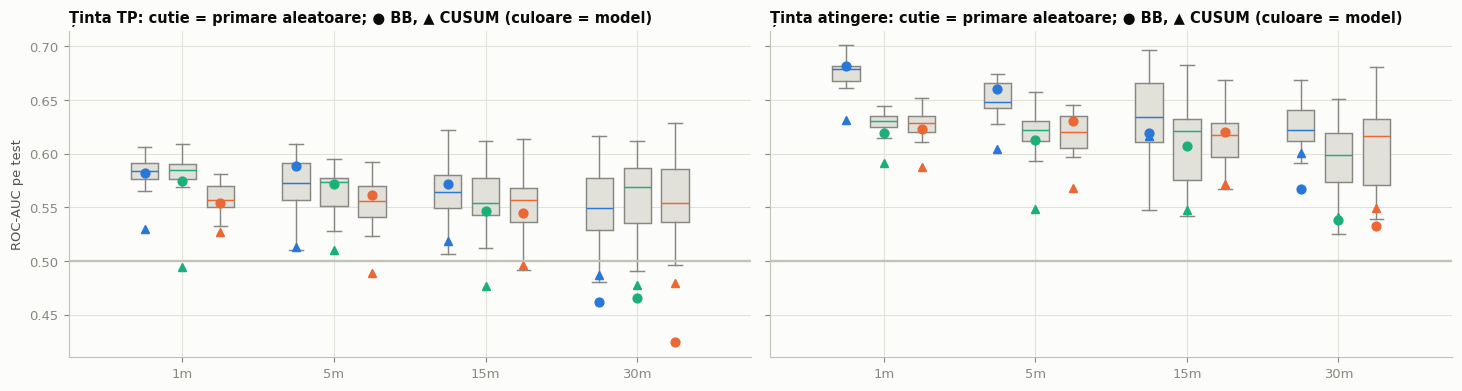

In [42]:
def rnd_tasks():
    T = []
    for R in RES:
        for d in range(N_RANDOM_DRAWS):
            ds = ("RND", R, d)
            for target in ("y_tp", "touch"):
                for m in MODELS:
                    T.append({"id": ("rnd", R, d, target, m), "ds": ds, "target": target, "model": m, "seed": seed_of(R, d, m),
                              "evals": [(ds, "val"), (ds, "test"), (("BB", R), "test"), (("CUSUM", R), "test")]})
    return T
RNDM = cached(f"random_models_{N_RANDOM_DRAWS}", lambda: run_tasks(rnd_tasks(), f"Primara aleatoare ({N_RANDOM_DRAWS} extrageri × 4 rezoluții × 2 ținte × 3 modele)"))

def rnd_metrics():
    rows = []
    for (_, R, d, target, m), o in RNDM.items():
        ds = ("RND", R, d); E = DS[ds]; E = E[E["seg"] == "test"]; y = E[target].to_numpy(int)
        mt = clf_metrics(y, o["preds"][(ds, "test")].astype(float), o["base_train"], ci=False)
        r = {"R": R, "d": d, "target": target, "model": m, **{k: mt[k] for k in ("AUC", "PR-AUC", "rată pozitivă", "skill log loss %", "skill Brier %")}}
        for p in PRIMS:
            Ep = DS[(p, R)]; Ep = Ep[Ep["seg"] == "test"]
            r[f"AUC pe test {p}"] = roc_auc_score(Ep[target].to_numpy(int), o["preds"][((p, R), "test")].astype(float))
        rows.append(r)
    return pd.DataFrame(rows)
RM = rnd_metrics()

rows = {}
for target, Mt in [("y_tp", M_TP_TEST), ("touch", M_TO_TEST)]:
    for R in RES:
        for m in MODELS:
            sub = RM[(RM.R == R) & (RM.target == target) & (RM.model == m)]
            r = {"aleator AUC medie": sub["AUC"].mean(), "aleator AUC p5": sub["AUC"].quantile(.05), "aleator AUC p95": sub["AUC"].quantile(.95),
                 "aleator skill LL % medie": sub["skill log loss %"].mean()}
            for p in PRIMS:
                a = float(Mt.loc[(p, f"{R}m", m), "AUC"])
                r[f"{p} AUC"] = a; r[f"{p} percentilă"] = 100 * np.mean(sub["AUC"] < a)
                r[f"{p} skill LL %"] = float(Mt.loc[(p, f"{R}m", m), "skill log loss %"])
                r[f"model aleator → test {p} AUC"] = sub[f"AUC pe test {p}"].mean()
            rows[("TP" if target == "y_tp" else "atingere", f"{R}m", m)] = r
RCMP = pd.DataFrame(rows).T; RCMP.index.names = ["țintă", "rezoluție", "model"]
display(Markdown("### 11.1 Clasificare: primare reale vs primara aleatoare (test)\n`model aleator → test P` = model antrenat pe intrări aleatoare, evaluat pe testul primarei reale P (media pe extrageri)."))
display(RCMP.astype(float).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, target, Mt in [(axes[0], "y_tp", M_TP_TEST), (axes[1], "touch", M_TO_TEST)]:
    for j, R in enumerate(RES):
        for k, m in enumerate(MODELS):
            sub = RM[(RM.R == R) & (RM.target == target) & (RM.model == m)]["AUC"]
            x = j + (k - 1) * 0.25
            ax.boxplot(sub, positions=[x], widths=0.18, showfliers=False, patch_artist=True, boxprops=dict(facecolor=GRID, color=MUTED),
                       medianprops=dict(color=MODEL_COLORS[m]), whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
            ax.plot(x, float(Mt.loc[("BB", f"{R}m", m), "AUC"]), "o", color=MODEL_COLORS[m], ms=6)
            ax.plot(x, float(Mt.loc[("CUSUM", f"{R}m", m), "AUC"]), "^", color=MODEL_COLORS[m], ms=6)
    ax.axhline(0.5, color=AXIS); ax.set_xticks(range(len(RES)), [f"{R}m" for R in RES])
    ax.set_title(f"Ținta {'TP' if target == 'y_tp' else 'atingere'}: cutie = primare aleatoare; ● BB, ▲ CUSUM (culoare = model)")
axes[0].set_ylabel("ROC-AUC pe test")
fig.tight_layout(); plt.show()

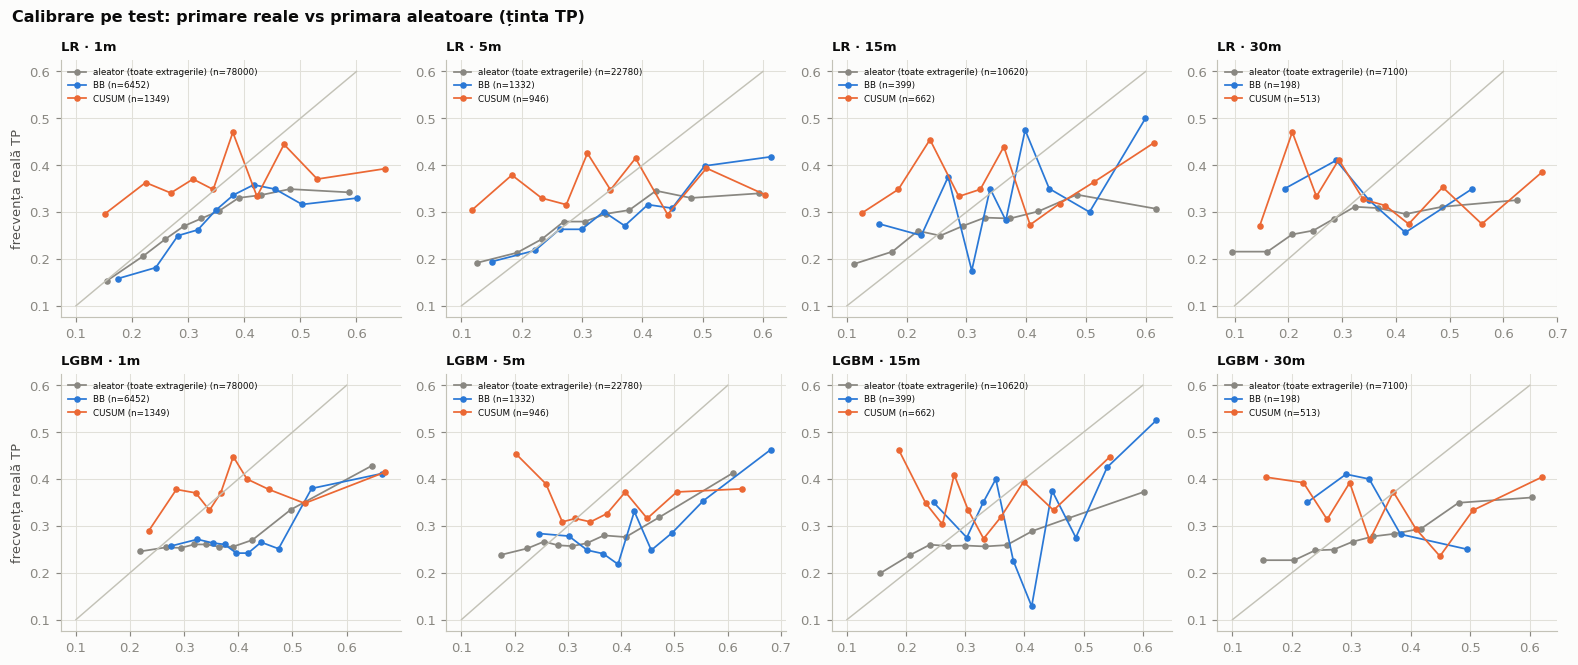

In [43]:
# 11.2 Calibrare: predicțiile tuturor extragerilor aleatoare (concatenate) vs primarele reale, LightGBM și LR, ținta TP
fig, axes = plt.subplots(2, 4, figsize=(15, 6.4))
for i, m in enumerate(["LR", "LGBM"]):
    for j, R in enumerate(RES):
        ax = axes[i, j]
        P, Y = [], []
        for d in range(N_RANDOM_DRAWS):
            ds = ("RND", R, d); E = DS[ds]; E = E[E["seg"] == "test"]
            P.append(RNDM[("rnd", R, d, "y_tp", m)]["preds"][(ds, "test")].astype(float)); Y.append(E["y_tp"].to_numpy(int))
        series = [("aleator (toate extragerile)", np.concatenate(P), np.concatenate(Y), MUTED)]
        for p, col in zip(PRIMS, [C["blue"], C["orange"]]):
            E = DS[(p, R)]; E = E[E["seg"] == "test"]
            series.append((p, BASE[("y_tp", p, R, m)]["preds"][((p, R), "test")].astype(float), E["y_tp"].to_numpy(int), col))
        for lab, pr, y, col in series:
            q = pd.qcut(pr, 10 if len(y) >= 300 else 5, labels=False, duplicates="drop")
            g = pd.DataFrame({"p": pr, "y": y, "q": q}).groupby("q").agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))
            ax.plot(g["p"], g["y"], "o-", ms=3.5, lw=1.2, color=col, label=f"{lab} (n={len(y)})")
        ax.plot([0.1, 0.6], [0.1, 0.6], color=AXIS, lw=1); ax.set_title(f"{m} · {R}m", fontsize=9); ax.legend(fontsize=6)
        if j == 0: ax.set_ylabel("frecvența reală TP")
fig.suptitle("Calibrare pe test: primare reale vs primara aleatoare (ținta TP)", x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout(); plt.show()

In [44]:
# 11.3 Filtrarea primarei aleatoare (aceeași procedură; 100 de filtre aleatoare de referință pe fiecare extragere)
def rnd_filtering():
    rows = []
    for R in RES:
        for d in range(N_RANDOM_DRAWS):
            ds = ("RND", R, d); D = DS[ds]
            for m in MODELS:
                o = RNDM[("rnd", R, d, "y_tp", m)]
                st, g, n, rnd, _ = filter_one(D, o["preds"][(ds, "val")].astype(float), o["preds"][(ds, "test")].astype(float), seed_of("rf", R, d, m), n_rand=100)
                rows.append({"R": R, "d": d, "model": m, "pornit": st["păstrat (val)"] < 1, "Δ net / eveniment": st["Δ net / eveniment vs nefiltrat (bps)"],
                             "percentilă vs aleator": st["percentilă vs aleator: net/eveniment"]})
    return pd.DataFrame(rows)
RF_RND = cached(f"random_filtering_{N_RANDOM_DRAWS}", rnd_filtering)
rows = {}
for R in RES:
    for m in MODELS:
        s = RF_RND[(RF_RND.R == R) & (RF_RND.model == m)]
        on = s[s["pornit"]]
        r = {"aleator: filtre pornite %": 100 * s["pornit"].mean(), "aleator: Δ net/eveniment medie (pornite)": on["Δ net / eveniment"].mean(),
             "aleator: percentilă medie vs filtru aleator": on["percentilă vs aleator"].mean()}
        for p in PRIMS:
            f = FILT[(p, R, m)]
            r[f"{p}: pornit"] = f["păstrat (val)"] < 1
            r[f"{p}: Δ net/eveniment"] = f["Δ net / eveniment vs nefiltrat (bps)"] if f["păstrat (val)"] < 1 else np.nan
            r[f"{p}: percentilă"] = f["percentilă vs aleator: net/eveniment"] if f["păstrat (val)"] < 1 else np.nan
        rows[(f"{R}m", m)] = r
display(Markdown("### 11.3 Filtrare: primare reale vs primara aleatoare (test, ținta TP)"))
display(pd.DataFrame(rows).T.round(2))

### 11.3 Filtrare: primare reale vs primara aleatoare (test, ținta TP)

aleator: filtre pornite % aleator: Δ net/eveniment medie (pornite) aleator: percentilă medie vs filtru aleator BB: pornit BB: Δ net/eveniment BB: percentilă CUSUM: pornit CUSUM: Δ net/eveniment CUSUM: percentilă
1m  LR                         100                                   -2.444                                       13.55       True              -3.427              0          True                 -6.211             24.67
    RF                          10                                     -3.4                                          22      False                 NaN            NaN          True                 -8.707             16.67
    LGBM                        15                                   -7.505                                      0.3333      False                 NaN            NaN          True                 -10.67                13
5m  LR                         100                                   -2.105                                       33.45       True              -6.641              6          True                  -4.86                21
    RF                          55                                   0.1099                                       52.55      False                 NaN            NaN         False                    NaN               NaN
    LGBM                        50                                   -1.714                                        36.3      False                 NaN            NaN          True                 -17.93             2.333
15m LR                         100                                    1.639                                       54.15       True              -9.024          23.33          True                 -10.25             19.33
    RF                          70                                    1.077                                       58.93      False                 NaN            NaN          True                  3.454                61
    LGBM                        60                                    3.581                                       56.83      False                 NaN            NaN          True                  3.217             60.33
30m LR                          90                                   -5.215                                       30.06       True              -16.14          3.333          True                 -17.22                 1
    RF                          60                                    1.771                                       54.75      False                 NaN            NaN          True                  -7.88             23.67
    LGBM                        80                                  -0.7341                                       52.38      False                 NaN            NaN          True                 -6.592             25.33

**Interpretare (primara aleatoare).**
* O primară **fără nicio informație** atinge același AUC pentru TP ca BB: 0,584 la 1m cu LR (p5–p95 între extrageri: 0,567–0,604), față de 0,582 pentru BB (percentila 40). BB rămâne în distribuția aleatoare la 1m–15m. La 30m este sub ea, iar CUSUM este la percentilele 0–10 la aproape toate rezoluțiile: pe evenimentele CUSUM, modelele câștigă *mai puțin* decât pe intrări aleatoare.
* **Modelele antrenate pe intrări aleatoare prezic testul BB la fel de bine ca modelele antrenate pe BB** (1m LR: 0,584 vs 0,582). Același lucru este valabil pentru atingere. Calibrarea primarei aleatoare are aceeași formă (ordonare corectă, nivel supraestimat).
* Filtrarea pe primara aleatoare reproduce efectul negativ: la 1m LR, filtrul este în medie la percentila 13 față de filtre aleatoare, ca la BB.
* **Avantajul brut față de intrări aleatoare.** BB are un randament brut pe eveniment peste media primarei aleatoare la toate rezoluțiile (percentilele 75–95, adică +2…+7 bps). Evenimentele BB sunt însă puternic grupate în timp (uniqueness 0,03–0,59), iar dispersia extragerilor aleatoare, care sunt mai uniforme, subestimează incertitudinea lui BB. Nu considerăm acest rezultat o dovadă, ci o ipoteză.

**Concluzie:** modelele secundare învață **condiții generale de piață** (cât de mare va fi mișcarea față de barieră), nu ceva specific strategiilor.

## 12. Sinteză și concluzii

### 12.1 Tabel comparativ: cele trei întrebări, separat, pentru fiecare primară × rezoluție (test)

In [45]:
rows = {}
for p in PRIMS:
    for R in RES:
        k = (p, f"{R}m"); pr = PR.loc[(p, f"{R}m", "test")]
        tp = M_TP_TEST.xs((p, f"{R}m"), level=("primară", "rezoluție")); to = M_TO_TEST.xs((p, f"{R}m"), level=("primară", "rezoluție"))
        dec = DECOMP.xs((p, f"{R}m"), level=("primară", "rezoluție"))
        rnd_auc = RM[(RM.R == R) & (RM.target == "y_tp")].groupby("model")["AUC"].mean()
        act = [m for m in MODELS if FILT[(p, R, m)]["păstrat (val)"] < 1]
        rows[k] = {
            "[1] AUC TP (medie 3 modele)": tp["AUC"].astype(float).mean(),
            "[1] AUC TP primară aleatoare": rnd_auc.mean(),
            "[1] AUC atingere (medie)": to["AUC"].astype(float).mean(),
            "[1] AUC direcție | atingere": dec["AUC modelului TP: TP vs SL | atins"].astype(float).mean(),
            "[1] skill log loss TP % (medie)": tp["skill log loss %"].astype(float).mean(),
            "[2] filtre pornite (din 3)": len(act),
            "[2] Δ net/eveniment, filtre pornite (bps)": np.mean([FILT[(p, R, m)]["Δ net / eveniment vs nefiltrat (bps)"] for m in act]) if act else np.nan,
            "[2] percentilă vs filtru aleator (medie)": np.mean([FILT[(p, R, m)]["percentilă vs aleator: net/eveniment"] for m in act]) if act else np.nan,
            "[3] brut / eveniment (bps)": pr["brut mediu / eveniment (bps)"], "[3] IC95 brut": f"[{pr['IC95 jos']:.0f}, {pr['IC95 sus']:.0f}]",
            "[3] net / eveniment (bps)": pr["net mediu / eveniment (bps)"], "[3] PnL net portofoliu %": pr["randament total net %"], "[3] Sharpe net": pr["Sharpe net"]}
SUM = pd.DataFrame(rows).T
SUM.index.names = ["primară", "rezoluție"]
display(SUM)
print(f"Timp total de rulare: {(time.time() - T0) / 60:.1f} min")

[1] AUC TP (medie 3 modele) [1] AUC TP primară aleatoare [1] AUC atingere (medie) [1] AUC direcție | atingere [1] skill log loss TP % (medie) [2] filtre pornite (din 3) [2] Δ net/eveniment, filtre pornite (bps)  \
primară rezoluție                                                                                                                                                                                                                      
BB      1m                             0.5702                       0.5754                   0.6412                      0.5084                          -1.049                          1                                    -3.427   
        5m                             0.5739                       0.5633                   0.6342                      0.4789                          -0.394                          1                                    -6.641   
        15m                            0.5544                       0.5597                   0.6151                      0.5089                         -0.9629                          1                                    -9.024   
        30m                            0.4506                       0.5578                    0.546                      0.4532                          -5.858                          1                                    -16.14   
CUSUM   1m                             0.5172                       0.5754                   0.6036                      0.4769                           -2.79                          3                                     -8.53   
        5m                              0.504                       0.5633                   0.5736                      0.4714                          -3.998                          2                                    -11.39   
        15m                            0.4973                       0.5597                   0.5784                      0.4882                          -3.808                          3                                    -1.191   
        30m                            0.4815                       0.5578                   0.5637                      0.4573                          -6.594                          3                                    -10.56   

                  [2] percentilă vs filtru aleator (medie) [3] brut / eveniment (bps) [3] IC95 brut [3] net / eveniment (bps) [3] PnL net portofoliu % [3] Sharpe net  
primară rezoluție                                                                                                                                                      
BB      1m                                               0                     -1.203     [-28, 23]                    -12.36                   -18.25         -1.279  
        5m                                               6                      1.267     [-29, 28]                    -9.859                   -8.191        -0.6772  
        15m                                          23.33                      8.957     [-21, 35]                    -2.103                   -2.378         -0.325  
        30m                                          3.333                      16.84     [-11, 43]                     5.742                    1.913         0.4784  
CUSUM   1m                                           18.11                      3.125     [-28, 35]                    -7.836                   -17.38         -1.554  
        5m                                           11.67                    -0.7255     [-35, 32]                    -11.72                   -18.81         -1.715  
        15m                                          46.89                    -0.5013     [-36, 34]                    -11.51                   -10.64         -1.057  
        30m                                          16.67                     -4.201     [-37, 26]                    -15.21                   -10.21         -1.214

Timp total de rulare: 4.7 min


`[1]` = există informație predictivă? · `[2]` = filtrul selectează tranzacții mai bune? · `[3]` = strategia acoperă costurile?

### 12.2 Răspunsuri

**Cum se schimbă primarele între rezoluții.** BB pe 20 de bare devine de ~30 de ori mai rar de la 1m la 30m și își mută orizontul de la 20 de minute la 10 ore. CUSUM, cu prag fix în unități de σ și condiție pe ferestre de 1 oră, este aproape invariant (de la ~6 la ~2,4 evenimente/zi). Ieșirile sunt identice, deci proporțiile TP/SL/timeout și distanțele barierelor variază puțin. **La nicio rezoluție avantajul brut nu se distinge de zero.** IC-urile au ±25–80 bps, estimările punctuale își schimbă semnul între segmente, iar costul de ~11 bps (10 comision + ~1 funding; slippage neglijabil) face PnL-ul net negativ aproape peste tot. BB la rezoluțiile mari pare ușor mai bun decât intrările aleatoare (+2…+7 bps brut), dar evenimentele sunt prea grupate și prea puține pentru o concluzie.

**Cum se schimbă modelele.** AUC-ul pentru „TP primul” scade cu rezoluția la BB: ~0,57–0,59 la 1m/5m (singurele celule cu IC peste 0,5), ~0,55 la 15m și sub 0,5 la 30m. La CUSUM este ~0,50 peste tot. Probabilitățile sunt prost calibrate, pentru că rata TP a scăzut de la 0,37 (train) la ~0,30 (test). Ținta „atingere vs timeout” este clar mai predictibilă (AUC 0,59–0,68, skill pozitiv la LR/RF) și se degradează mai lent cu rezoluția.

**Unde filtrarea aduce îmbunătățire și cât de stabilă este.** **Nicăieri, în mod verificabil.** 12 din 15 filtre active reduc randamentul net pe eveniment. Cele 3 care îl cresc sunt la percentila ~60 față de filtre aleatoare de aceeași mărime. Îmbunătățirile de PnL total vin din tranzacționarea mai rară a unor strategii care pierd și se reproduc cu filtre aleatoare. Cauza e identificată: modelul crește P(TP) alegând momente în care barierele sunt înguste față de volatilitatea curentă, ceea ce crește și P(SL).

**Se schimbă features relevante cu agregarea?** Familia dominantă **nu** se schimbă: volatilitatea (lățimea barierei σ_zilnic, volatilitatea de 1 h, `bb_width`) este #1 la orice rezoluție, pentru ambele primare și ambele ținte. Se schimbă însă cele secundare: la 1m–5m contează doar features pe ferestre de ceas, iar la 15m–30m câștigă features native rezoluției (bara curentă, Bollinger pe 20 de bare), mai ales la CUSUM. În același timp, stabilitatea importanțelor scade (corelație val–test 0,8 la 1m, aproape 0 la 30m). Importanța aparentă (gain/MDI) supraestimează sistematic familiile OI/funding/bază și book. Out-of-sample, acestea înrăutățesc predicția (regim nestaționar; acoperirea book-ului s-a degradat în mai 2026).

**Specific strategiei sau condiții generale?** **Condiții generale.** O primară aleatoare cu aceeași distribuție temporală obține același AUC ca BB. Modelele antrenate pe intrări aleatoare prezic testul BB la fel de bine ca cele antrenate pe BB, iar informația se transferă între BB și CUSUM fără pierderi semnificative. AUC-ul pentru direcție condiționat de atingere este ~0,48. Nimic din rezultate nu indică informație despre **direcție** specifică vreunei primare.

**Atenție la interpretare.** Lipsa semnificației pentru avantajul brut **nu** dovedește că avantajul este zero: intervalele permit și efecte de ±20 bps. Lipsa profitului net **nu** înseamnă lipsă de informație: modelele de atingere au informație reală, stabilă și calibrabilă, care nu poate fi transformată în bani printr-un filtru de intrare long-only cu această țintă.

### 12.3 Ce justifică un experiment ulterior (numai pe date de după 31.10.2026)

1. **Volatilitatea ca informație de dimensionare și de plasare a barierelor, nu ca filtru.** Predictibilitatea atingerii (AUC ~0,65, skill pozitiv) și rolul raportului „volatilitate curentă / σ zilnic” sugerează două teste: (a) bariere cu o estimare de volatilitate mai rapidă sau combinată și (b) dimensionarea poziției invers proporțional cu riscul prezis. Ipoteza de confirmat: varianța PnL-ului scade la același randament mediu.
2. **O țintă legată direct de valoarea așteptată.** Direcția condiționată de atingere sau randamentul la ieșire împărțit la σ zilnic, în locul „TP primul”, care, cu bariere asimetrice [1, 2], recompensează predicția volatilității. Fără un semnal de direcție (AUC ~0,48 aici), meta-labeling-ul nu are ce filtra.
3. **BB pe 15m/30m ca ipoteză îngustă de avantaj brut** (+2…+7 bps față de intrări aleatoare, insuficient pentru costuri taker), testată pre-declarat, cu inferență pe blocuri de timp și cu execuție maker pentru a reduce costul de 10 bps.
4. **Recalibrare pe fereastră recentă** a probabilităților, înainte de orice utilizare. Scăderea ratei de bază de la 0,37 la ~0,30 este suficientă pentru a face log loss-ul negativ.

**Nu justifică un experiment:** rafinarea condiției CUSUM sau a parametrilor Bollinger, alte features de book/OI/funding pentru aceeași țintă, ori antrenarea comună ca sursă de câștig.